In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 32
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 333,185
Discriminator parameters: 138,689
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(32, 1, 1))
    (1): ConvTranspose2d(32, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.431659	G_loss: 1.184602
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.185630	G_loss: 0.982908
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.212324	G_loss: 0.982881
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.191232	G_loss: 1.008593
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.193794	G_loss: 1.014819
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.194801	G_loss: 0.871868
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.116898	G_loss: 0.830933
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.160516	G_loss: 0.740078
Epoch: 1 [51200/60000 (85%)]	D_loss: 1.129643	G_loss: 0.851598
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.099977	G_loss: 1.024453
====> Epoch: 1 Train D_loss: 1.1769, Train G_loss: 0.9967
====> Epoch: 1 Val D_loss: 1.2459, Val G_loss: 0.7381
📈 Epoch 1 Summary:
   Train D Loss: 1.1769, Val D Loss: 1.2459
   Train G Loss: 0.9967, Val G Loss: 0.7381

📊 Epoch 2/100
------------------------

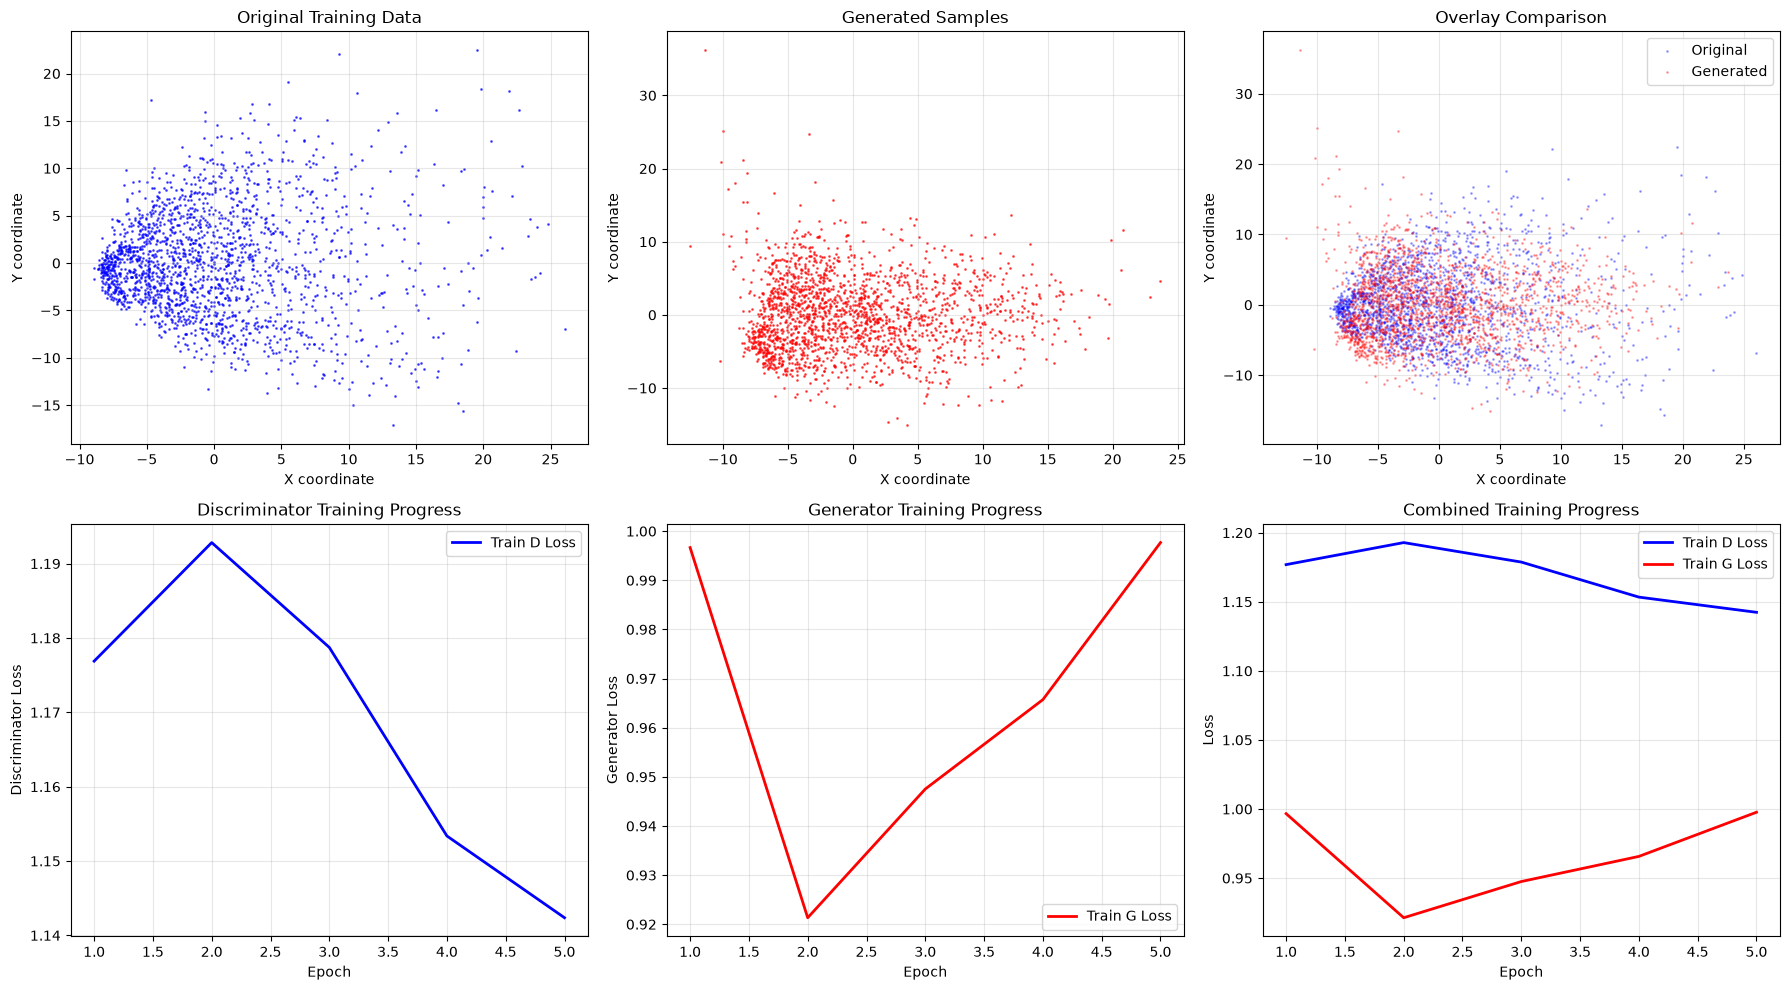

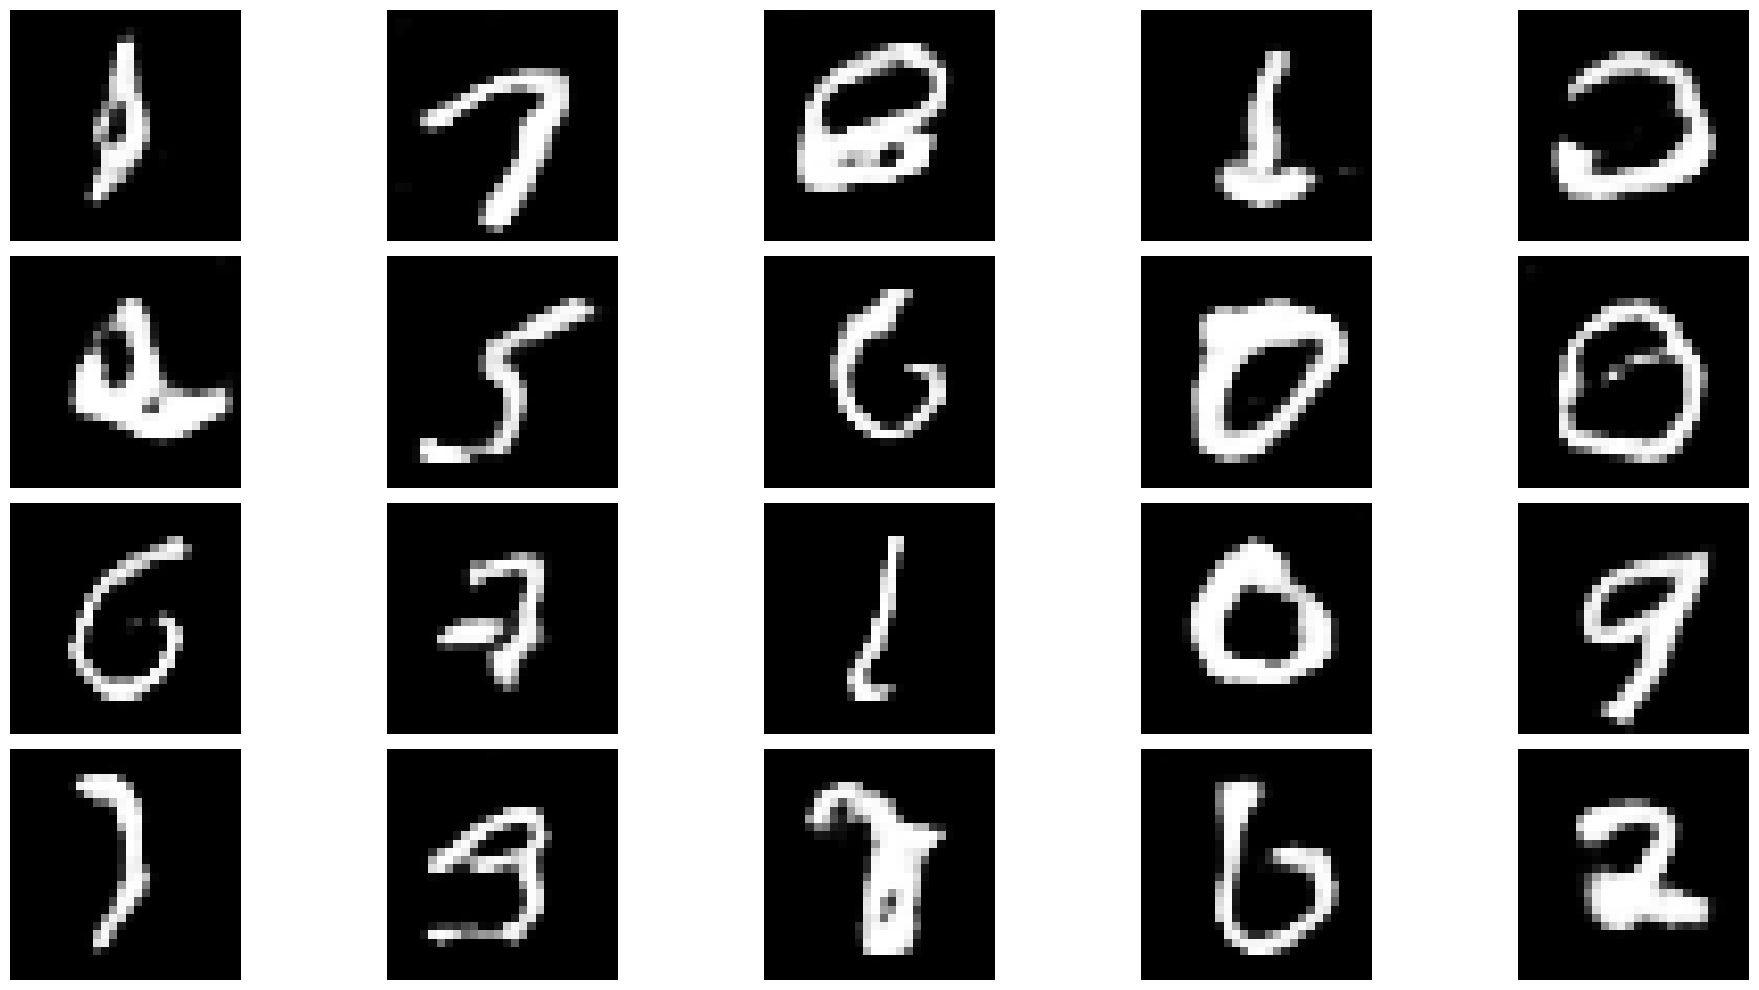

📈 Epoch 5 Summary:
   Train D Loss: 1.1424, Val D Loss: 1.3528
   Train G Loss: 0.9977, Val G Loss: 1.3708

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.205344	G_loss: 0.613234
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.093311	G_loss: 0.941543
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.001191	G_loss: 1.077271
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.126867	G_loss: 0.882382
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.034500	G_loss: 0.883579
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.129956	G_loss: 0.726065
Epoch: 6 [38400/60000 (64%)]	D_loss: 1.039361	G_loss: 1.100582
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.074815	G_loss: 1.445963
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.022896	G_loss: 0.994031
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.096094	G_loss: 0.958622
====> Epoch: 6 Train D_loss: 1.1156, Train G_loss: 1.0069
====> Epoch: 6 Val D_loss: 1.2116, Val G_loss: 1.0241
📈 Epoch 6 Summary:
   Train D Loss: 1.1156, Val D Loss: 1.2116
   Train G Loss: 1.0069, Val G Loss: 1

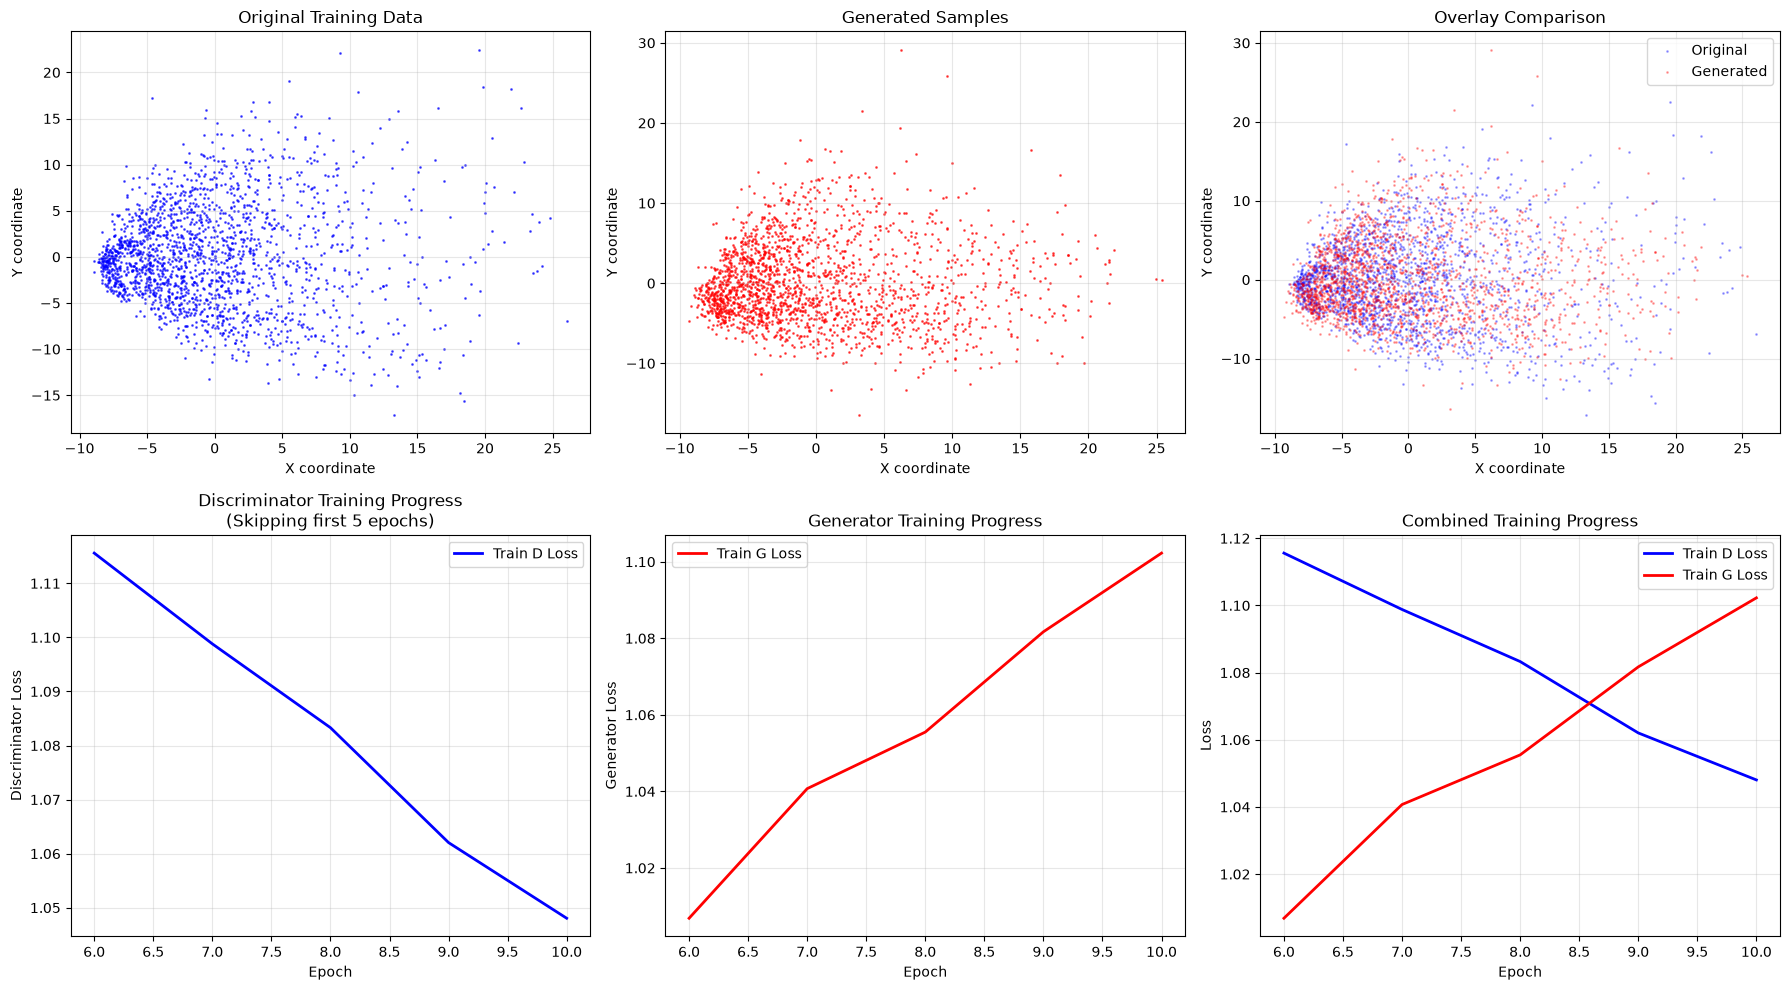

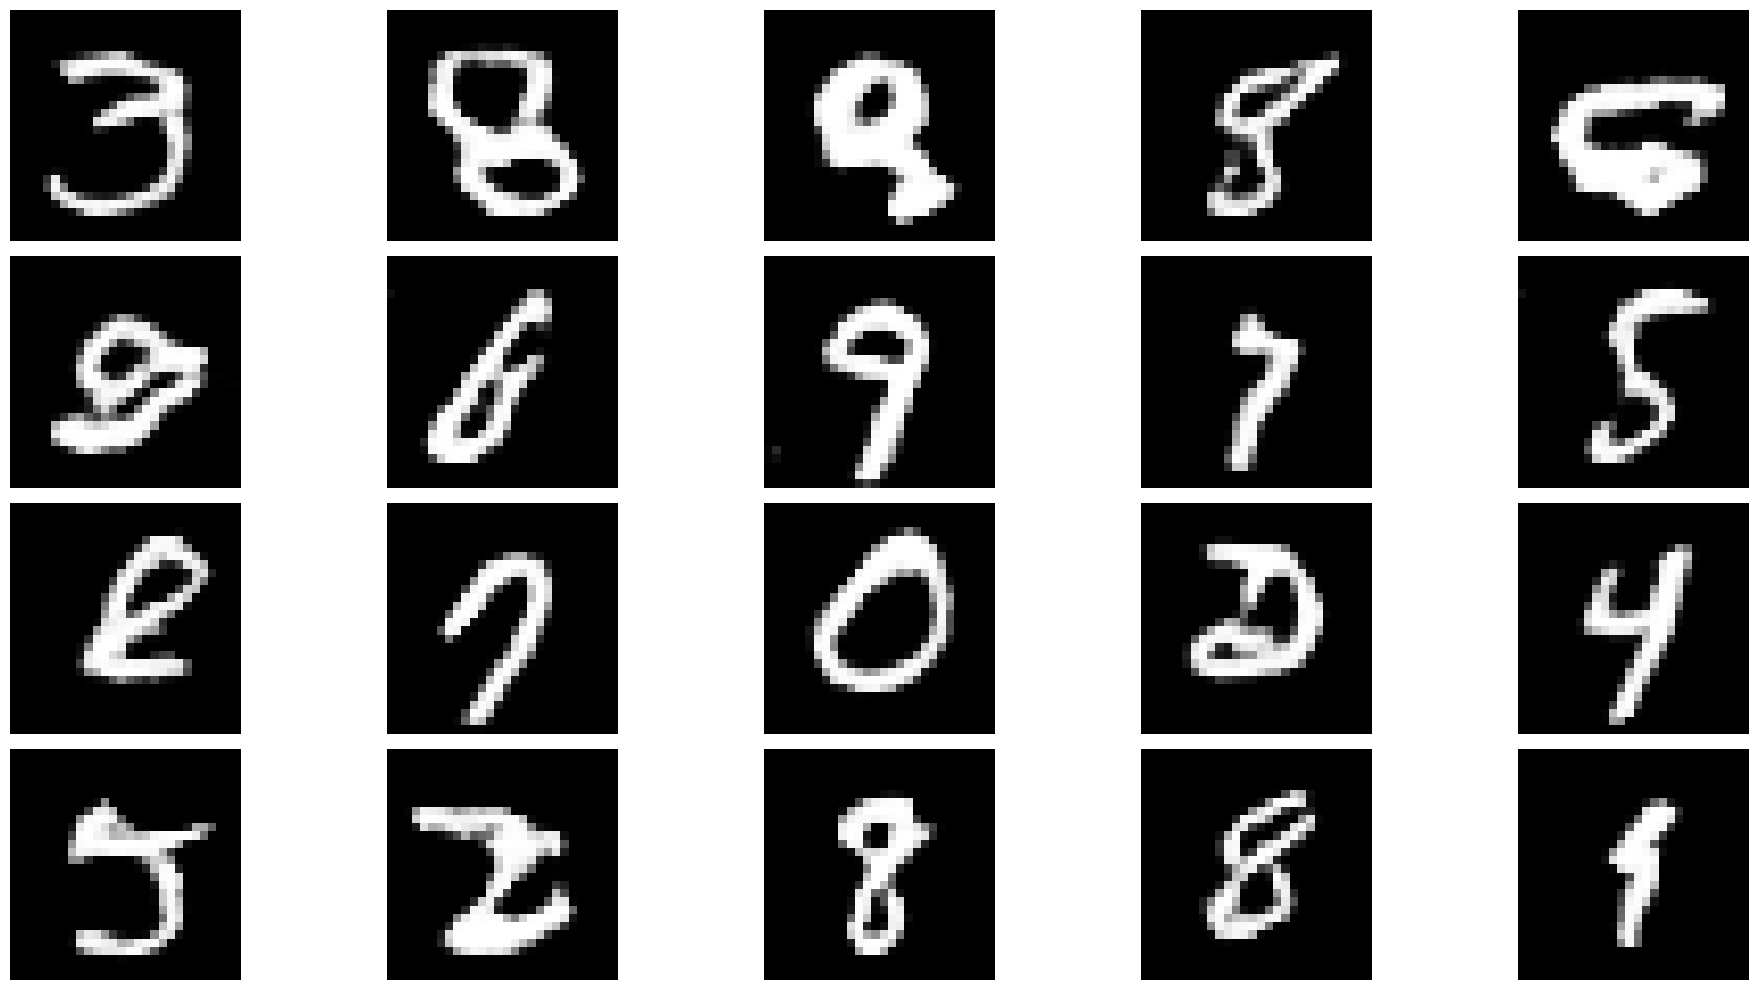

📈 Epoch 10 Summary:
   Train D Loss: 1.0481, Val D Loss: 1.1994
   Train G Loss: 1.1023, Val G Loss: 0.6692

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.008818	G_loss: 1.460865
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.970150	G_loss: 1.139183
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.958891	G_loss: 1.369651
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.199043	G_loss: 1.803359
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.039617	G_loss: 1.179162
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.929220	G_loss: 0.982696
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.091440	G_loss: 0.756348
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.986887	G_loss: 1.051870
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.105924	G_loss: 0.583284
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.100952	G_loss: 0.635600
====> Epoch: 11 Train D_loss: 1.0379, Train G_loss: 1.1255
====> Epoch: 11 Val D_loss: 1.1945, Val G_loss: 1.1274
📈 Epoch 11 Summary:
   Train D Loss: 1.0379, Val D Loss: 1.1945
   Train G Loss: 1.1255

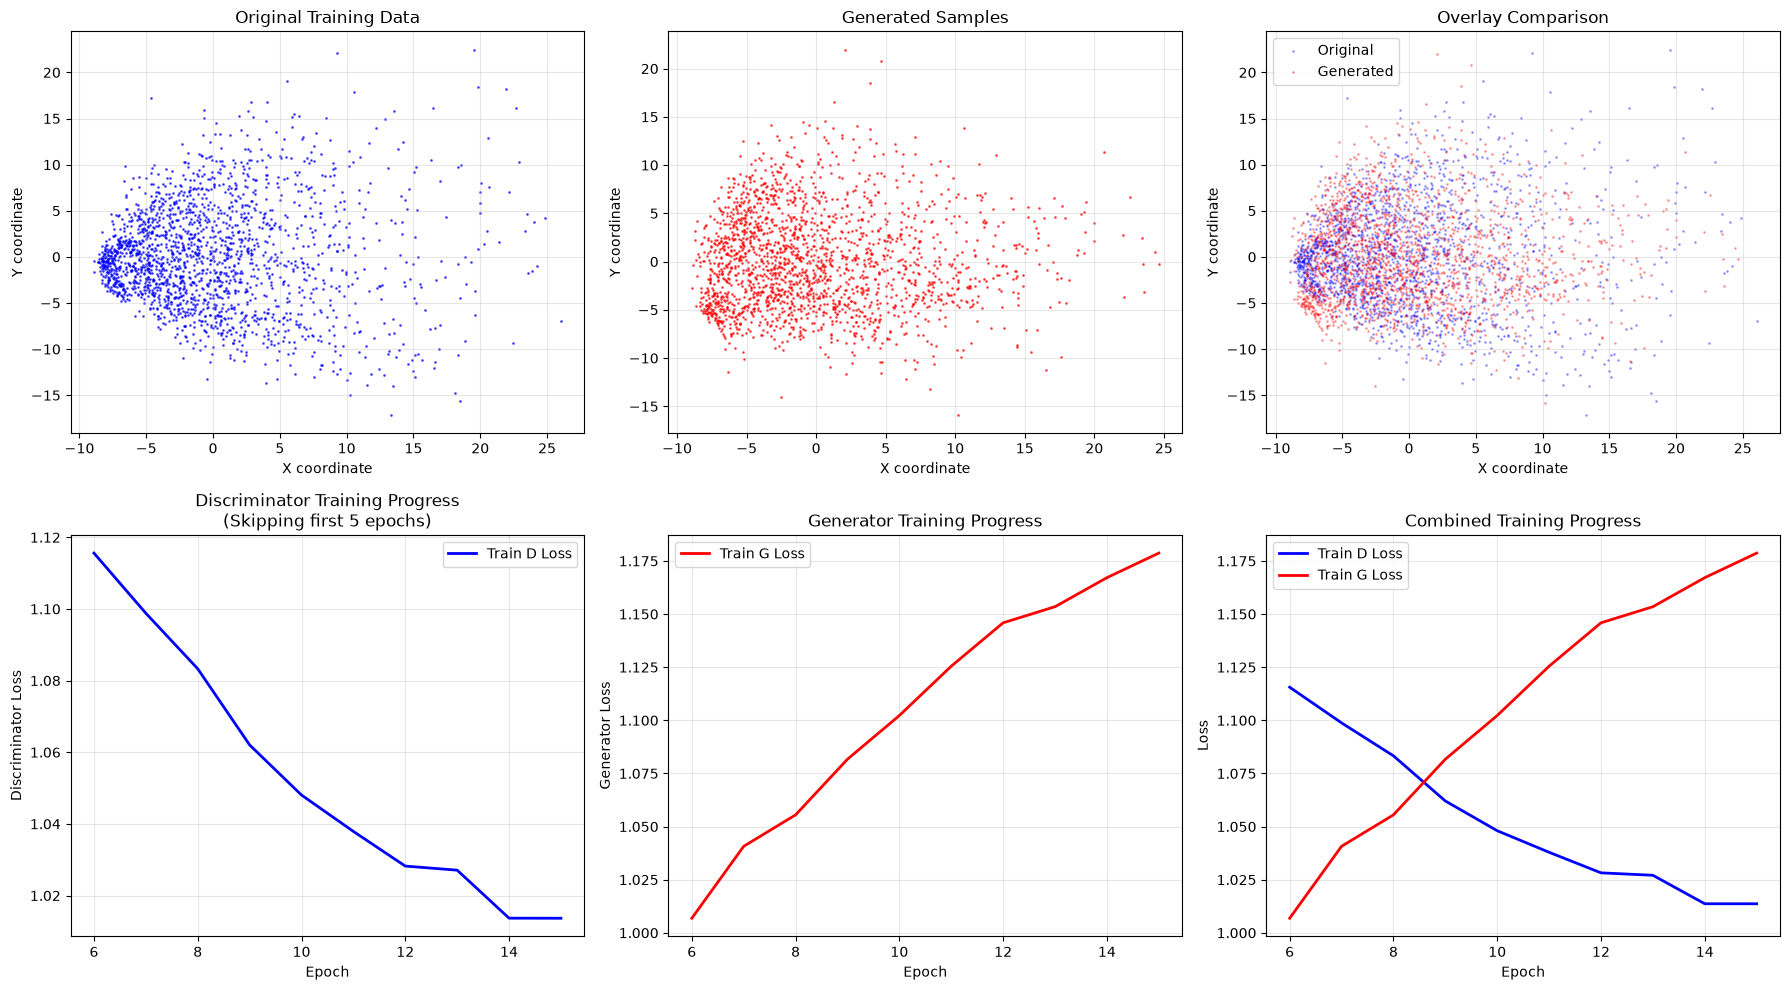

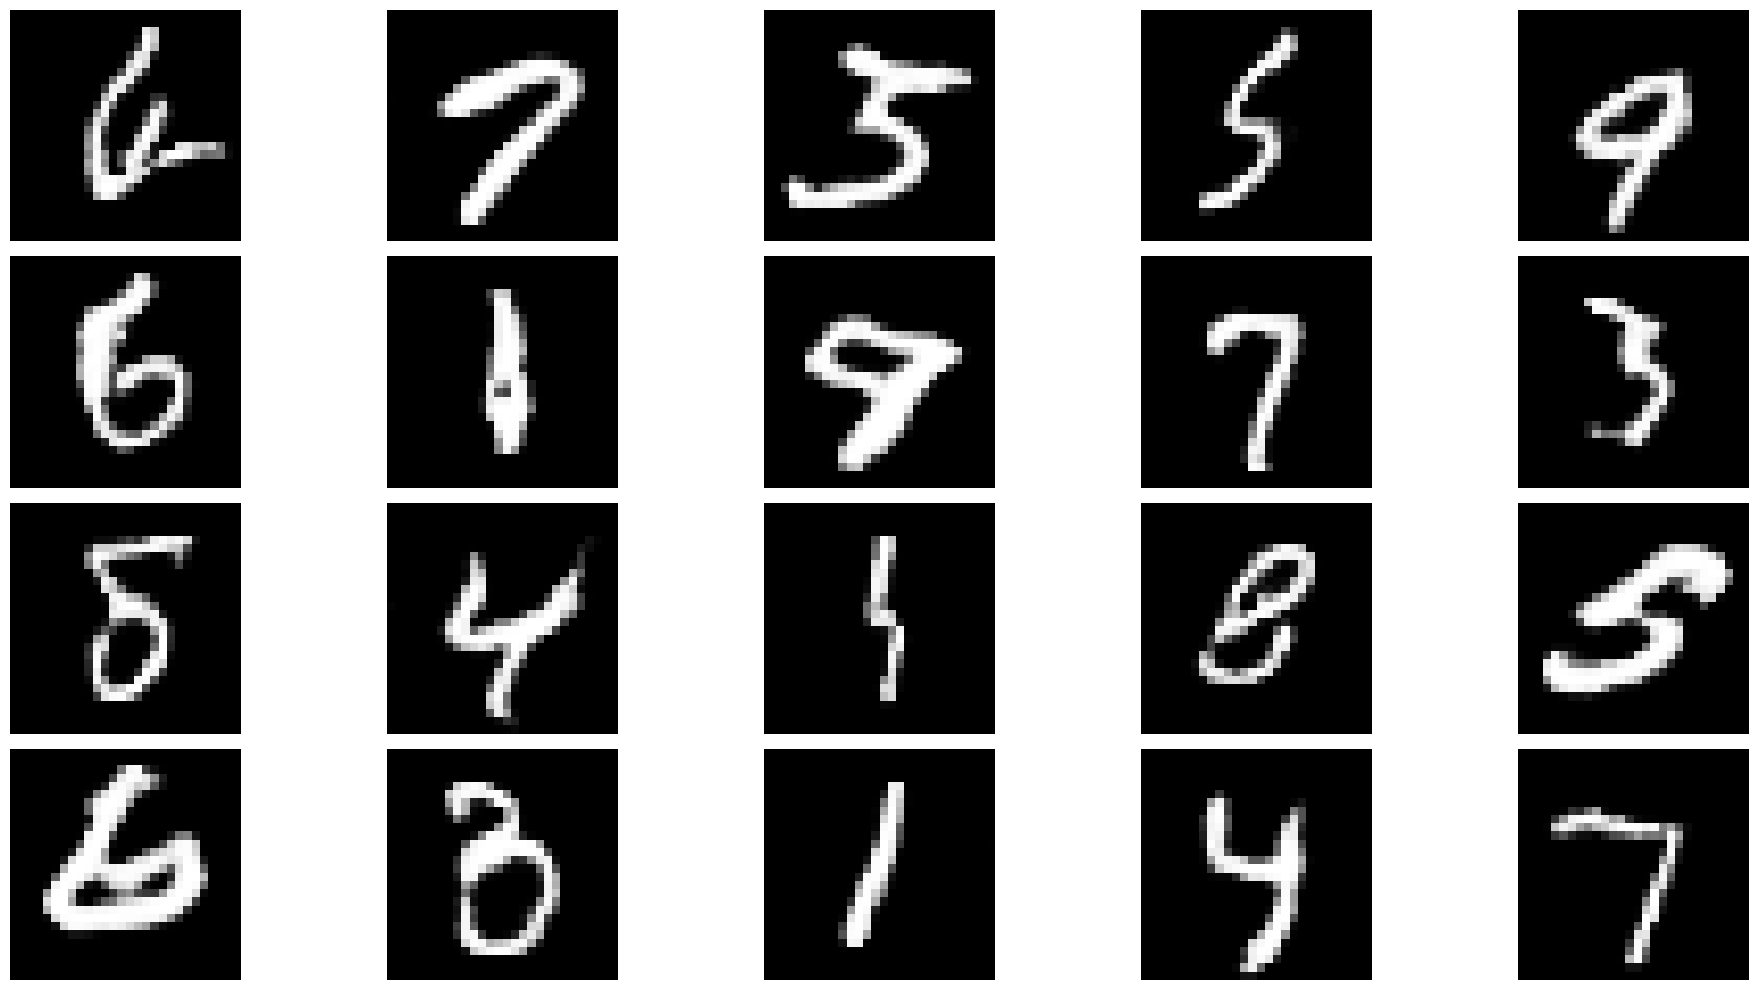

📈 Epoch 15 Summary:
   Train D Loss: 1.0137, Val D Loss: 1.2398
   Train G Loss: 1.1787, Val G Loss: 1.4359

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.931719	G_loss: 1.194371
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.968560	G_loss: 1.128782
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.991765	G_loss: 1.481808
Epoch: 16 [19200/60000 (32%)]	D_loss: 1.019105	G_loss: 1.514585
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.933414	G_loss: 0.834118
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.982487	G_loss: 0.876648
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.945801	G_loss: 1.413783
Epoch: 16 [44800/60000 (75%)]	D_loss: 1.030644	G_loss: 1.751363
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.915527	G_loss: 1.351319
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.013304	G_loss: 0.768496
====> Epoch: 16 Train D_loss: 1.0078, Train G_loss: 1.1891
====> Epoch: 16 Val D_loss: 1.4735, Val G_loss: 1.9545
📈 Epoch 16 Summary:
   Train D Loss: 1.0078, Val D Loss: 1.4735
   Train G Loss: 1.1891

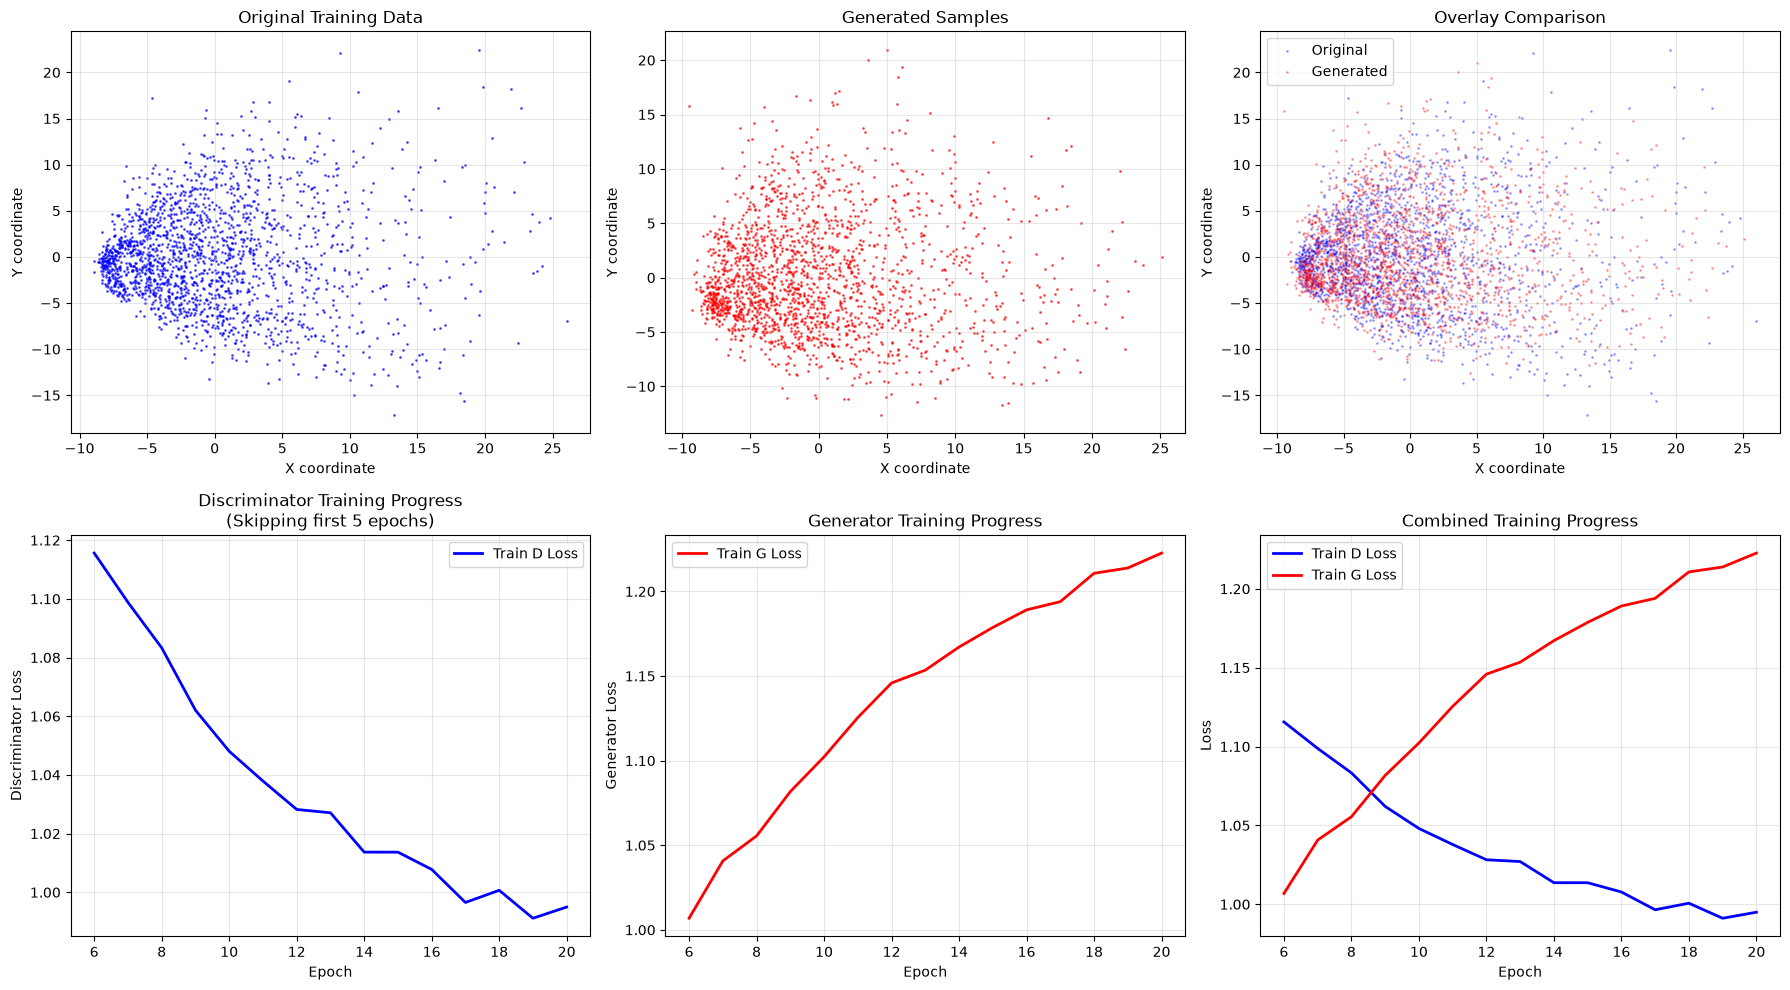

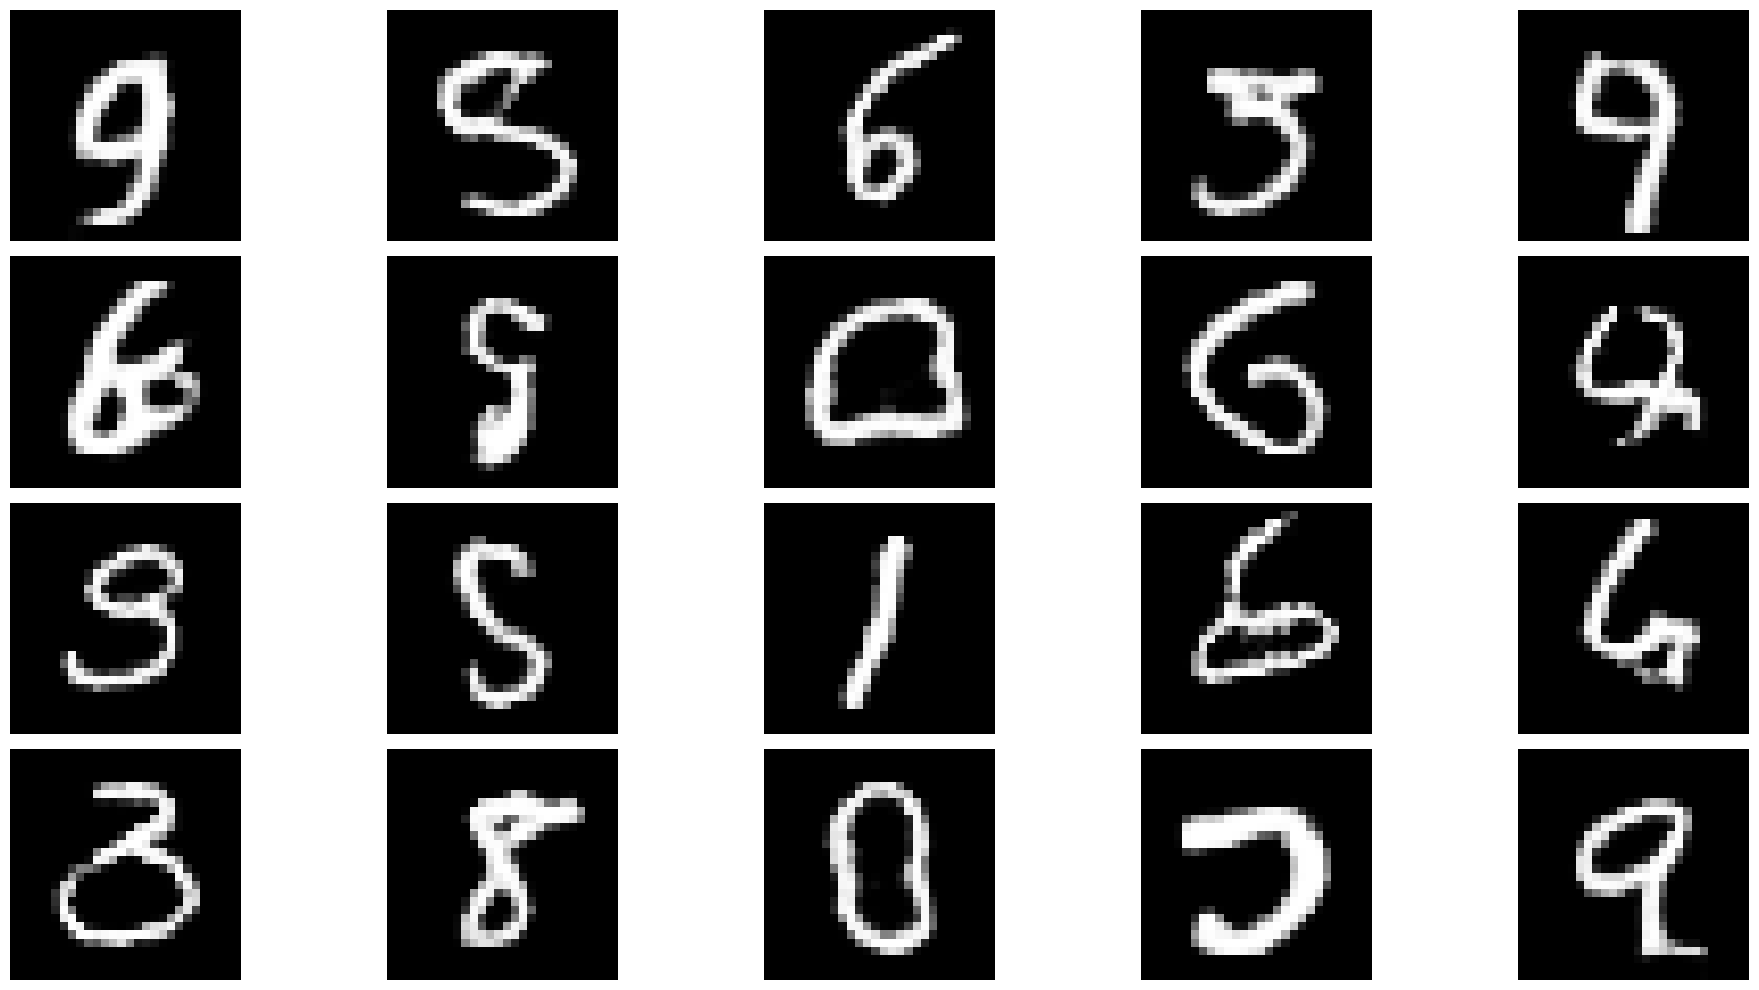

📈 Epoch 20 Summary:
   Train D Loss: 0.9950, Val D Loss: 1.1214
   Train G Loss: 1.2226, Val G Loss: 0.9243

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.918734	G_loss: 1.126749
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.928027	G_loss: 1.117172
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.904569	G_loss: 1.081370
Epoch: 21 [19200/60000 (32%)]	D_loss: 1.027207	G_loss: 0.835546
Epoch: 21 [25600/60000 (43%)]	D_loss: 1.184874	G_loss: 2.043159
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.926192	G_loss: 1.022269
Epoch: 21 [38400/60000 (64%)]	D_loss: 1.018707	G_loss: 0.990155
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.841028	G_loss: 1.273627
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.973163	G_loss: 0.646297
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.945723	G_loss: 1.443209
====> Epoch: 21 Train D_loss: 0.9839, Train G_loss: 1.2323
====> Epoch: 21 Val D_loss: 1.4616, Val G_loss: 1.9566
📈 Epoch 21 Summary:
   Train D Loss: 0.9839, Val D Loss: 1.4616
   Train G Loss: 1.2323

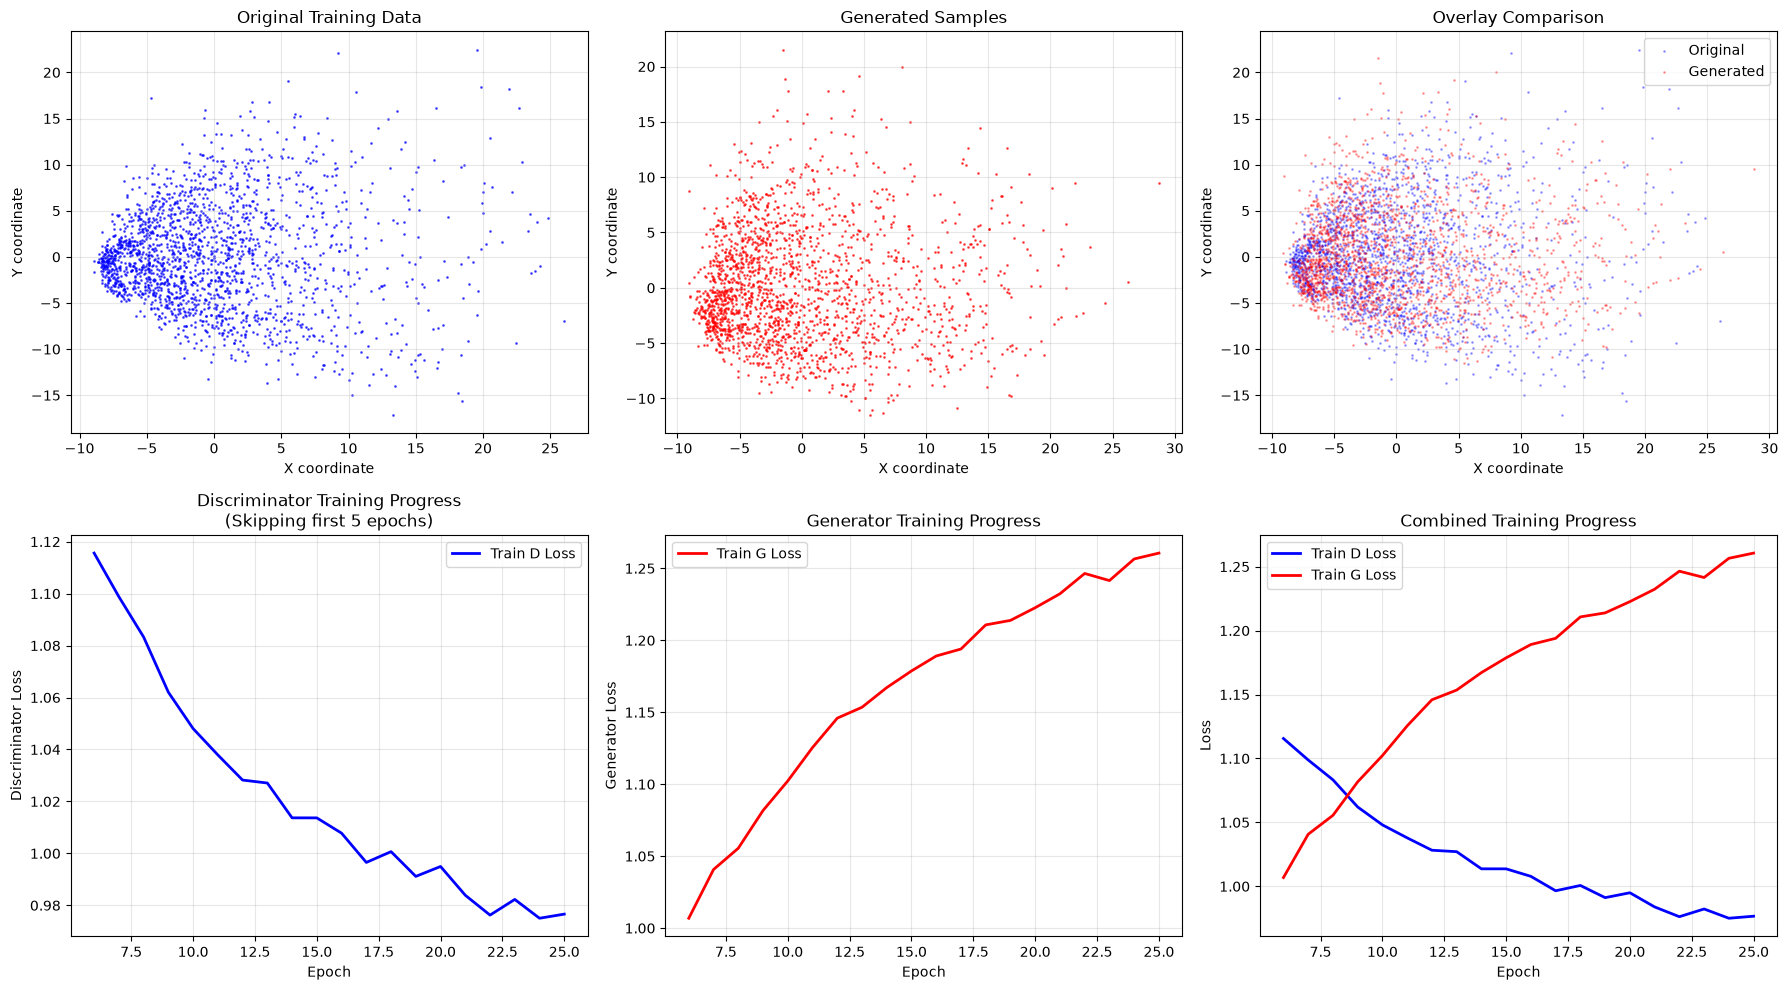

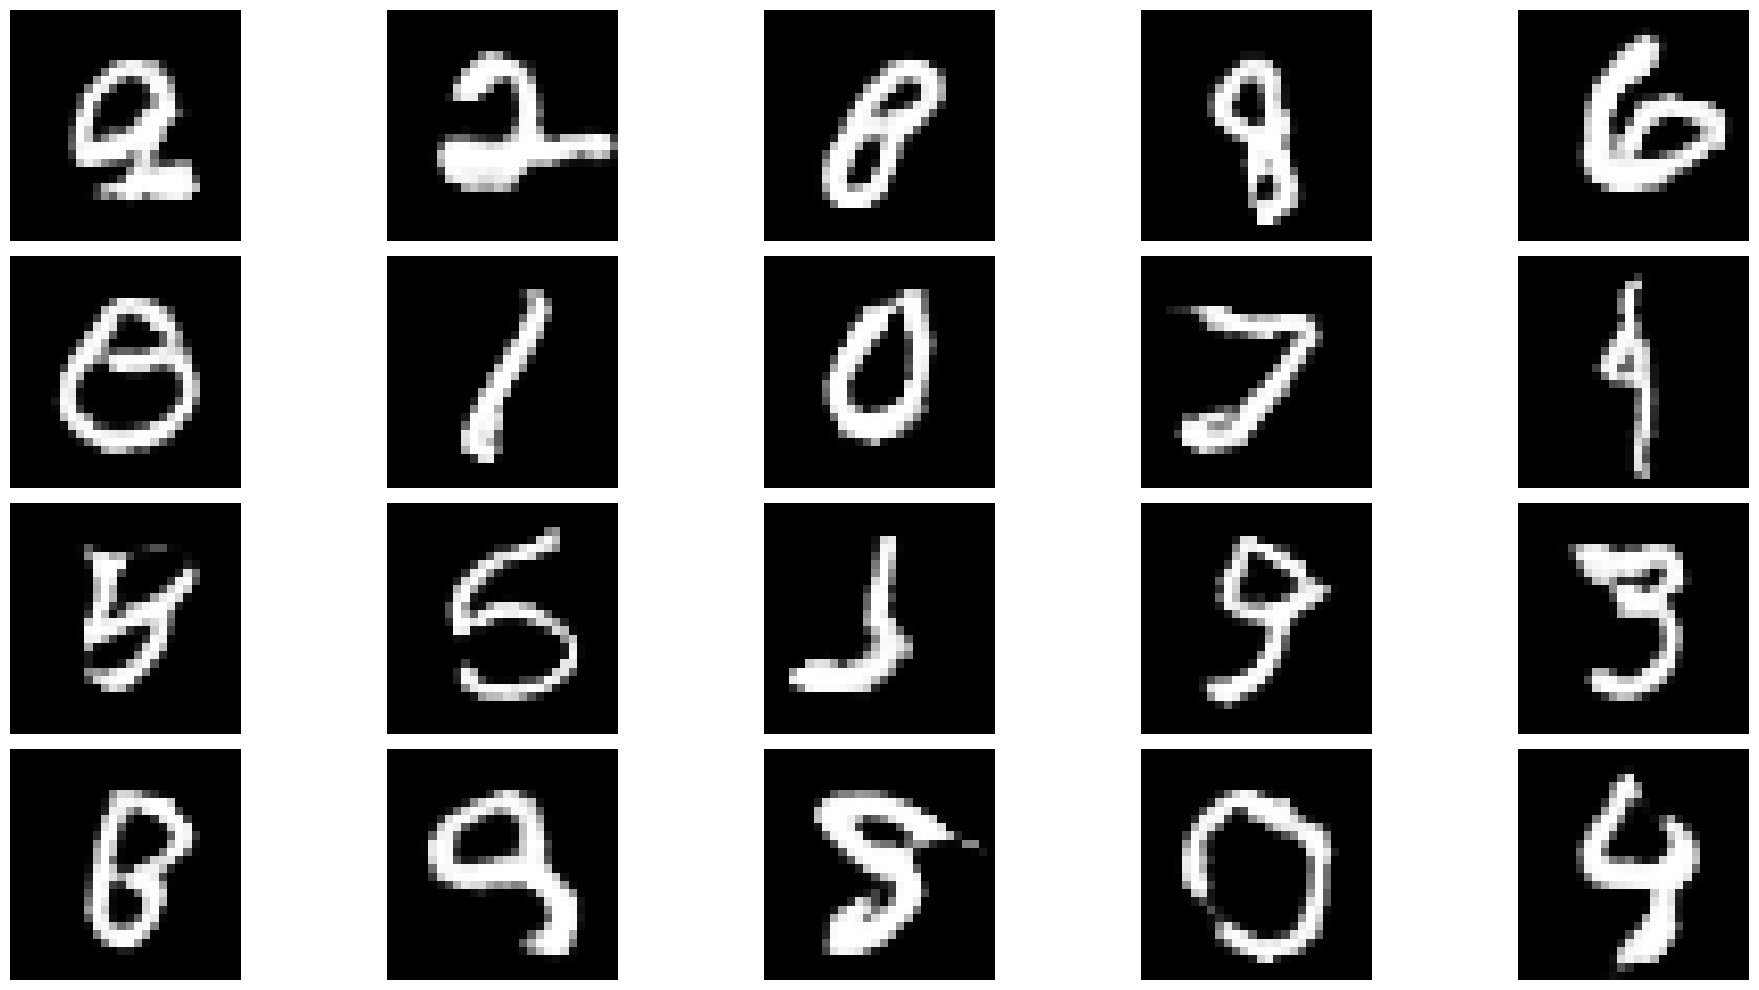

📈 Epoch 25 Summary:
   Train D Loss: 0.9766, Val D Loss: 1.2135
   Train G Loss: 1.2606, Val G Loss: 1.4603

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.922062	G_loss: 1.326887
Epoch: 26 [6400/60000 (11%)]	D_loss: 1.039588	G_loss: 0.656098
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.950640	G_loss: 1.154514
Epoch: 26 [19200/60000 (32%)]	D_loss: 1.026978	G_loss: 1.387695
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.965010	G_loss: 0.655825
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.951827	G_loss: 0.999632
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.930938	G_loss: 1.997248
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.850465	G_loss: 1.136129
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.967836	G_loss: 0.779976
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.981888	G_loss: 1.434798
====> Epoch: 26 Train D_loss: 0.9693, Train G_loss: 1.2727
====> Epoch: 26 Val D_loss: 1.2631, Val G_loss: 1.5819
📈 Epoch 26 Summary:
   Train D Loss: 0.9693, Val D Loss: 1.2631
   Train G Loss: 1.2727

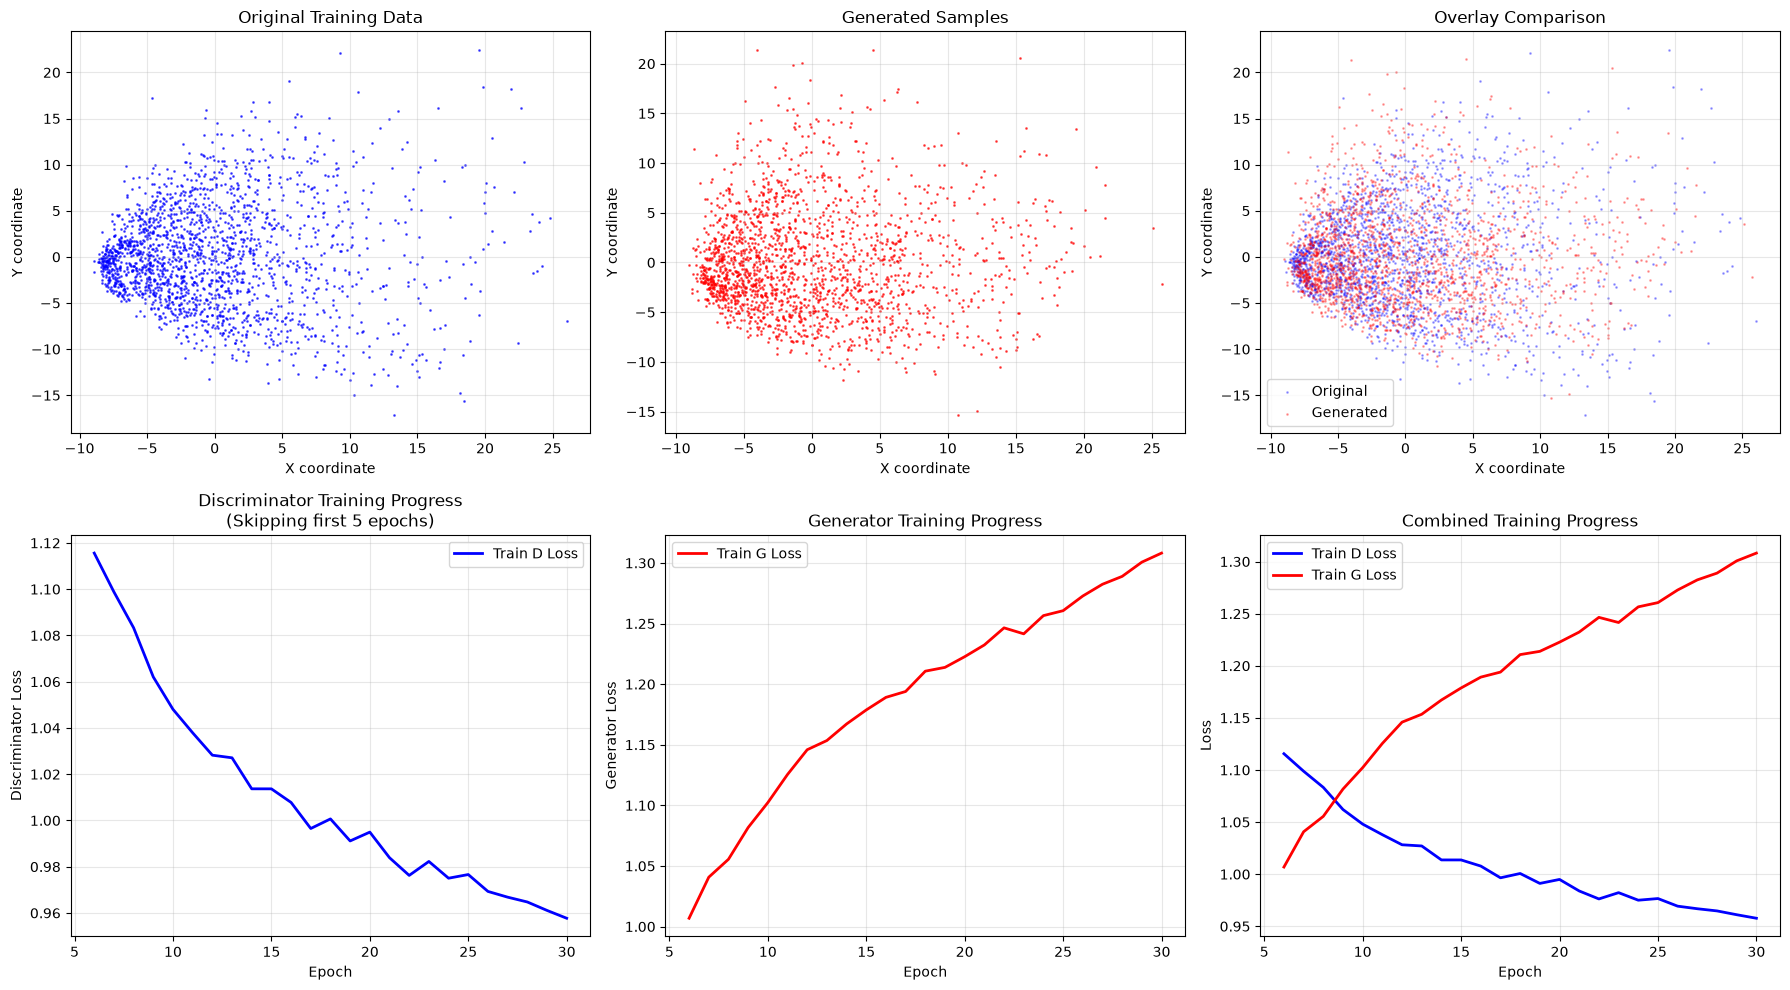

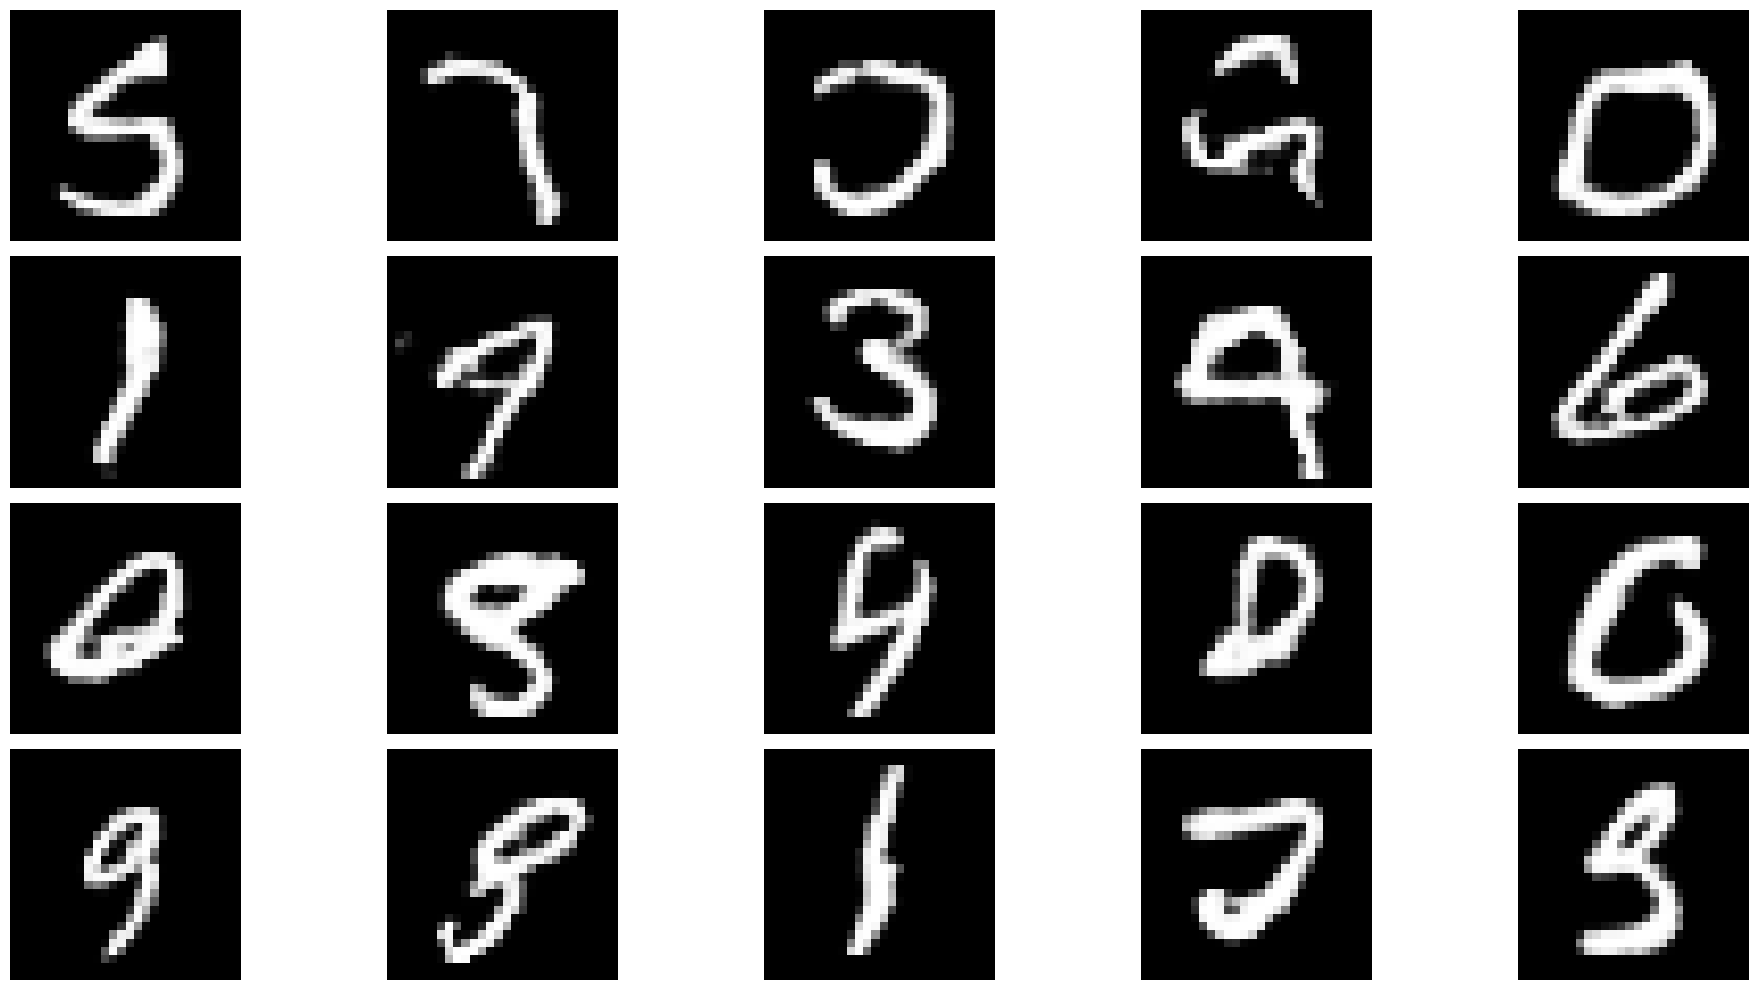

📈 Epoch 30 Summary:
   Train D Loss: 0.9577, Val D Loss: 1.4770
   Train G Loss: 1.3081, Val G Loss: 2.0500

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 1.053507	G_loss: 0.775257
Epoch: 31 [6400/60000 (11%)]	D_loss: 1.277618	G_loss: 2.058006
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.969519	G_loss: 1.220208
Epoch: 31 [19200/60000 (32%)]	D_loss: 1.126411	G_loss: 1.649711
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.958462	G_loss: 1.971334
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.907043	G_loss: 1.164838
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.953561	G_loss: 1.738727
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.005737	G_loss: 1.604171
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.904577	G_loss: 1.192503
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.926556	G_loss: 1.257399
====> Epoch: 31 Train D_loss: 0.9496, Train G_loss: 1.3054
====> Epoch: 31 Val D_loss: 1.1393, Val G_loss: 0.8494
📈 Epoch 31 Summary:
   Train D Loss: 0.9496, Val D Loss: 1.1393
   Train G Loss: 1.3054

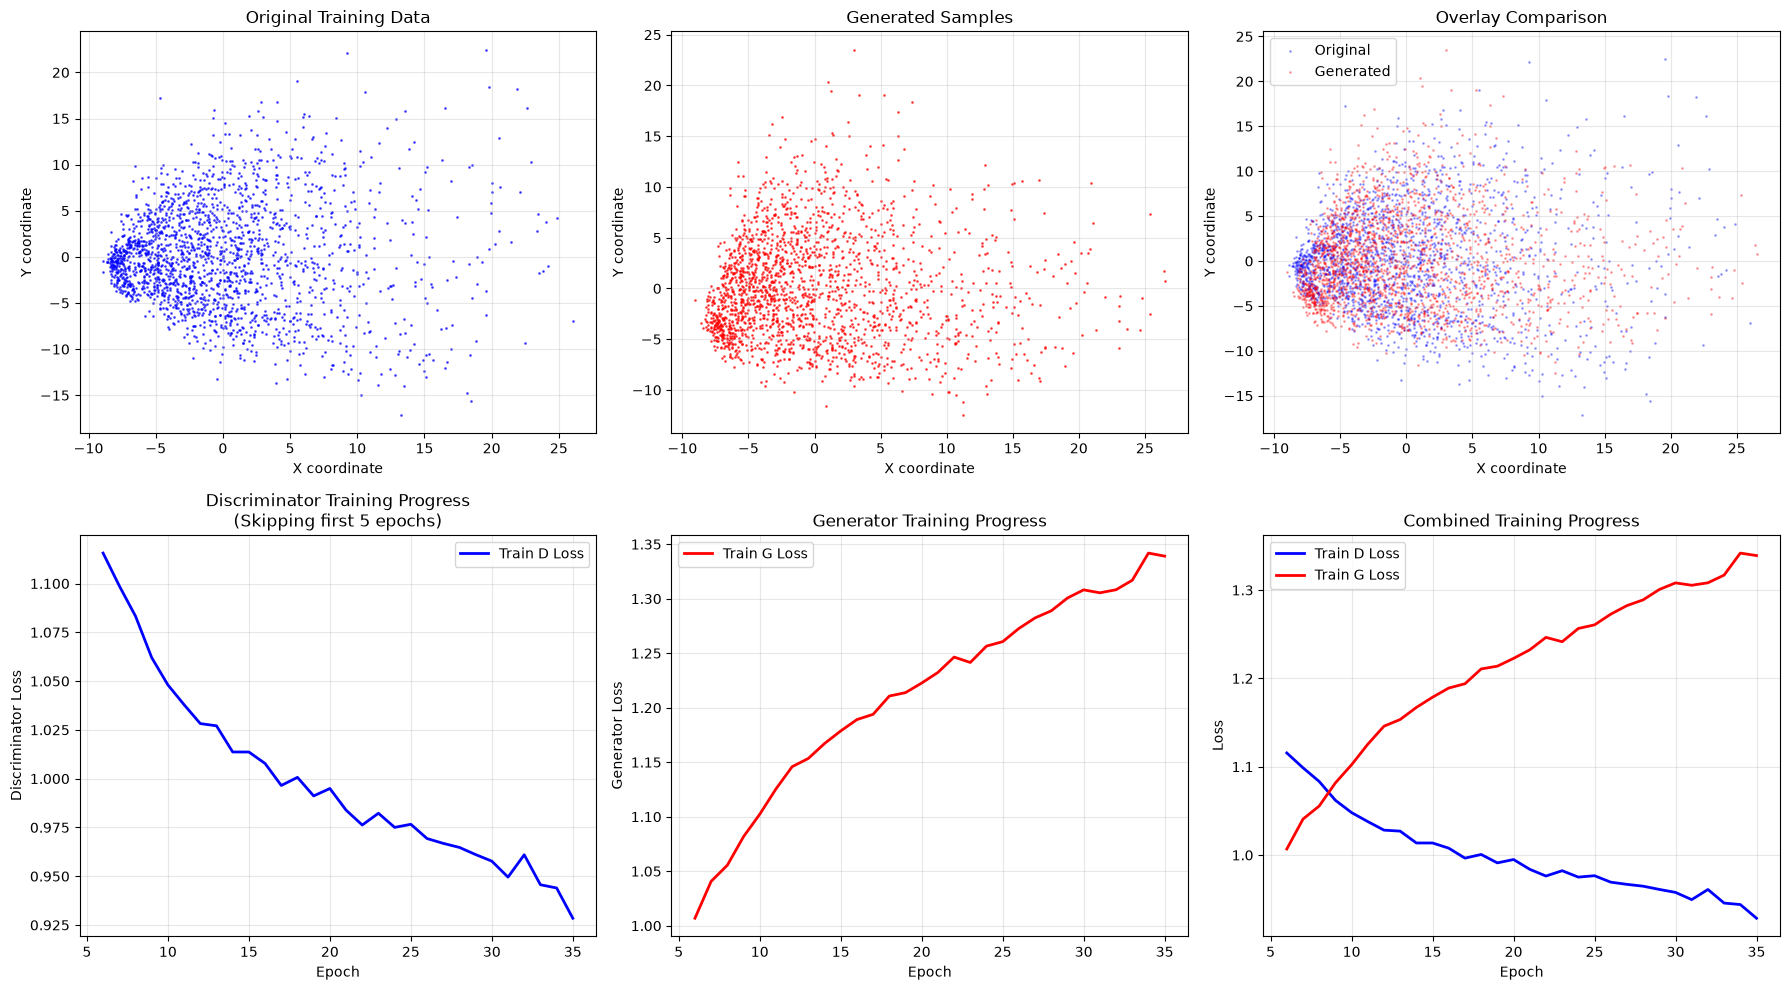

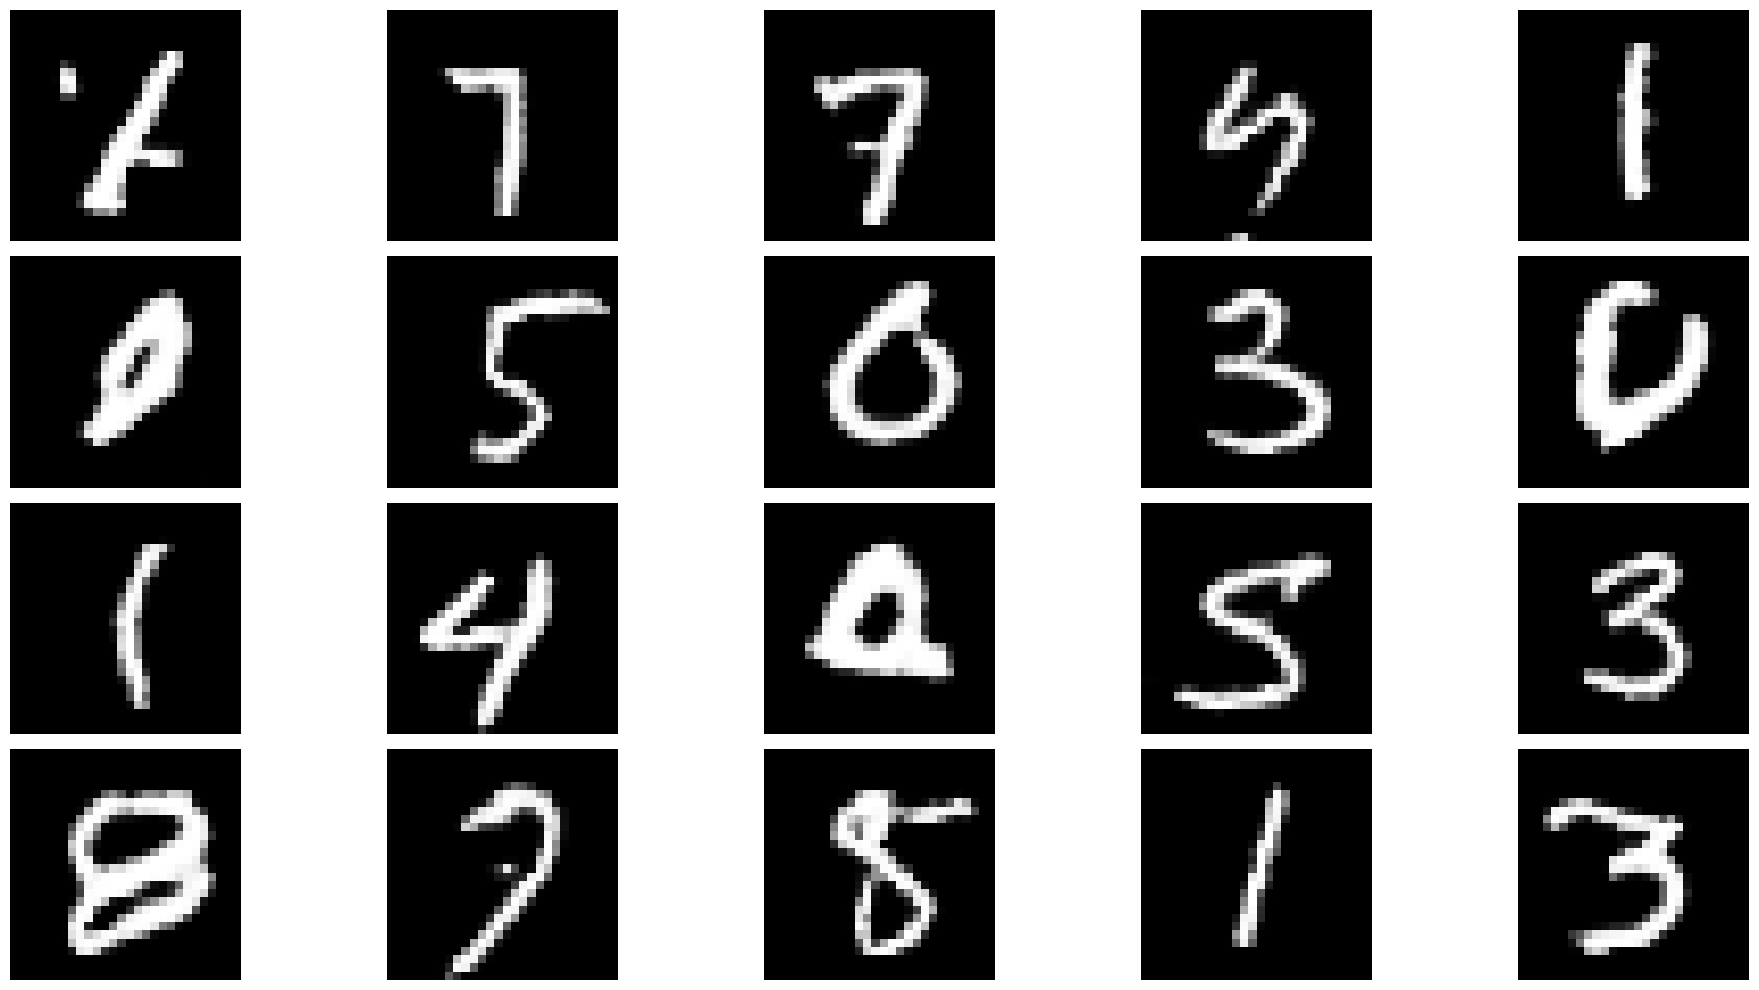

📈 Epoch 35 Summary:
   Train D Loss: 0.9285, Val D Loss: 1.1341
   Train G Loss: 1.3391, Val G Loss: 0.8673

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.915820	G_loss: 1.771533
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.884558	G_loss: 1.181810
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.929886	G_loss: 1.120928
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.808721	G_loss: 0.927586
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.967084	G_loss: 2.246998
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.879610	G_loss: 1.289826
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.037384	G_loss: 1.313370
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.888996	G_loss: 1.711562
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.833031	G_loss: 1.333060
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.951189	G_loss: 2.310864
====> Epoch: 36 Train D_loss: 0.9418, Train G_loss: 1.3470
====> Epoch: 36 Val D_loss: 1.1880, Val G_loss: 0.8018
📈 Epoch 36 Summary:
   Train D Loss: 0.9418, Val D Loss: 1.1880
   Train G Loss: 1.3470

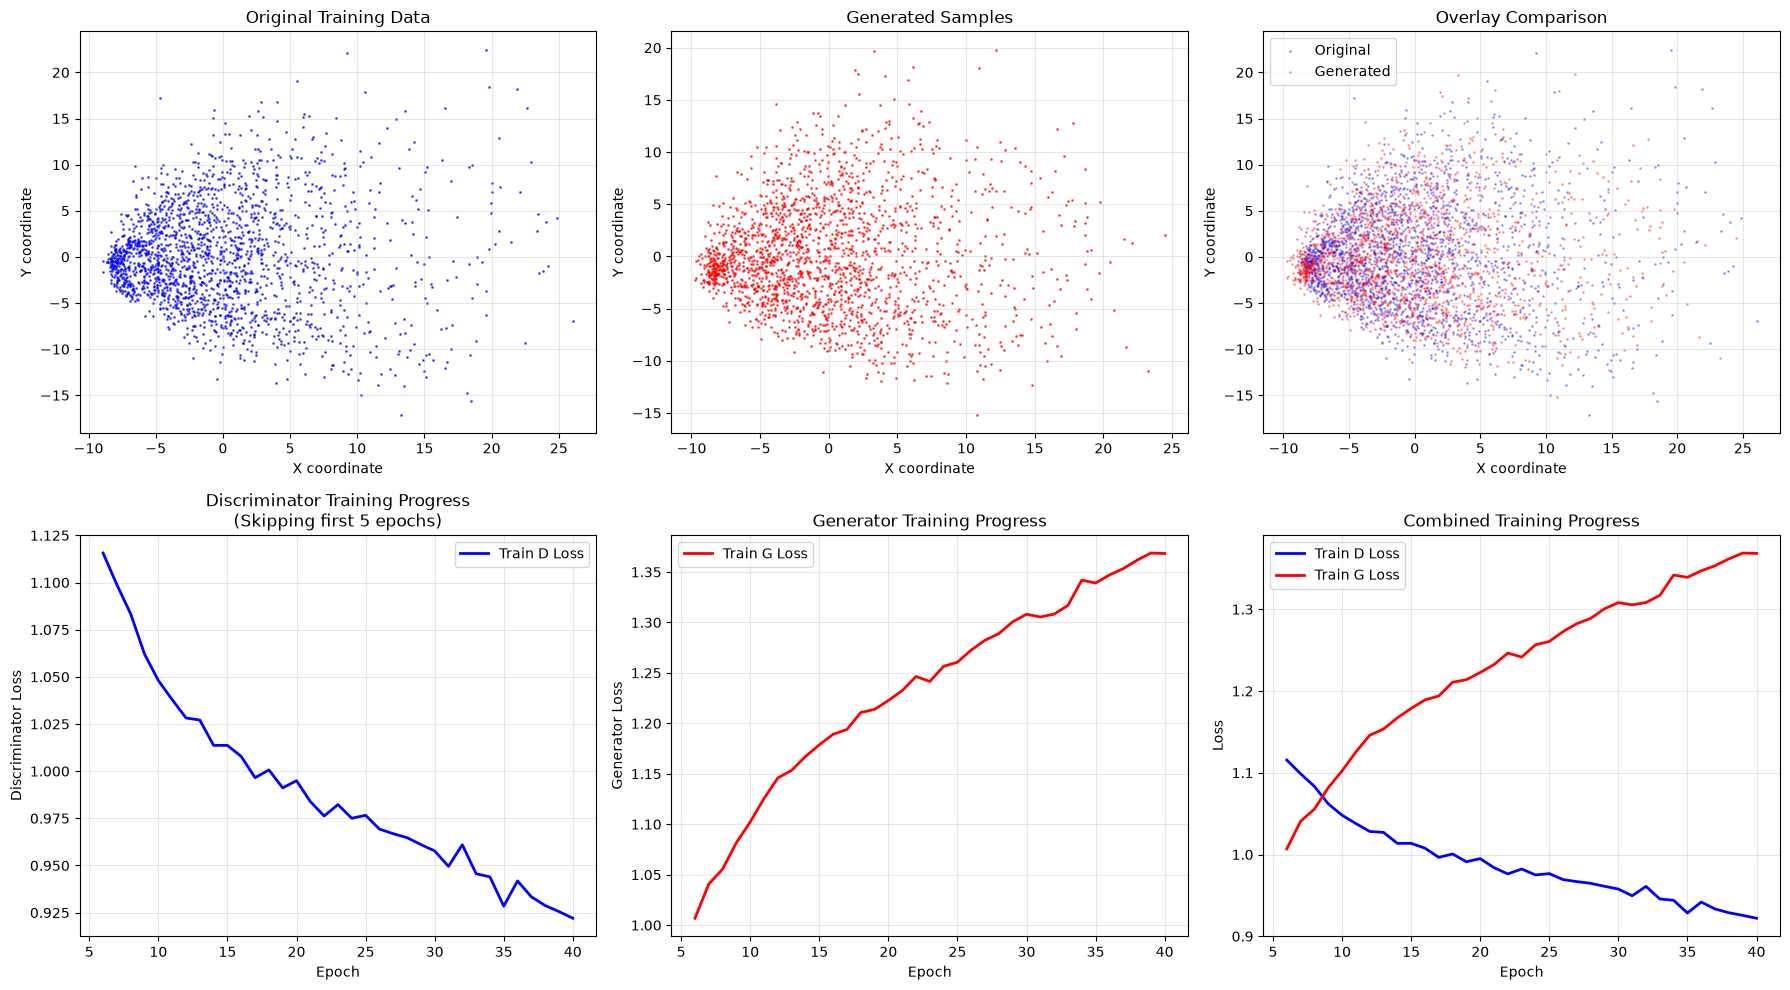

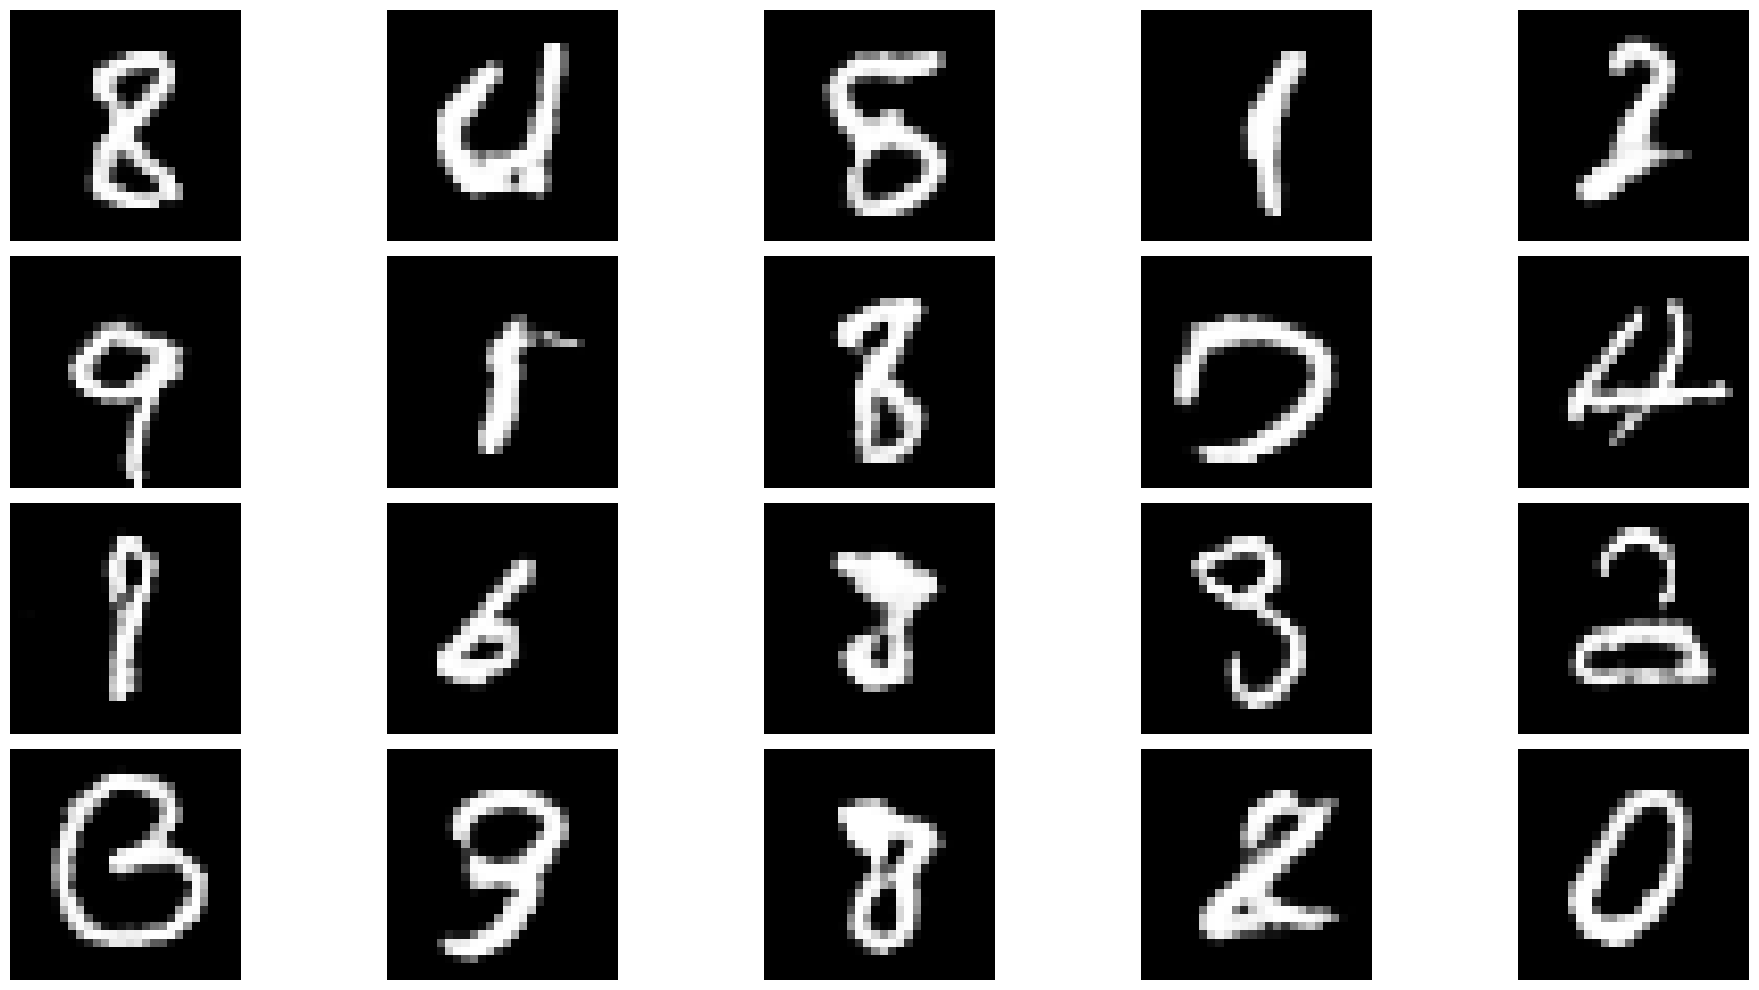

📈 Epoch 40 Summary:
   Train D Loss: 0.9220, Val D Loss: 1.1129
   Train G Loss: 1.3683, Val G Loss: 1.2042

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.809714	G_loss: 1.190088
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.855522	G_loss: 1.527645
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.784369	G_loss: 1.338826
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.944550	G_loss: 1.592573
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.814150	G_loss: 1.743553
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.929443	G_loss: 1.239875
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.889816	G_loss: 1.207097
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.894913	G_loss: 1.321850
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.898974	G_loss: 1.321815
Epoch: 41 [57600/60000 (96%)]	D_loss: 1.014181	G_loss: 1.524627
====> Epoch: 41 Train D_loss: 0.9179, Train G_loss: 1.3785
====> Epoch: 41 Val D_loss: 1.1390, Val G_loss: 0.9150
📈 Epoch 41 Summary:
   Train D Loss: 0.9179, Val D Loss: 1.1390
   Train G Loss: 1.3785

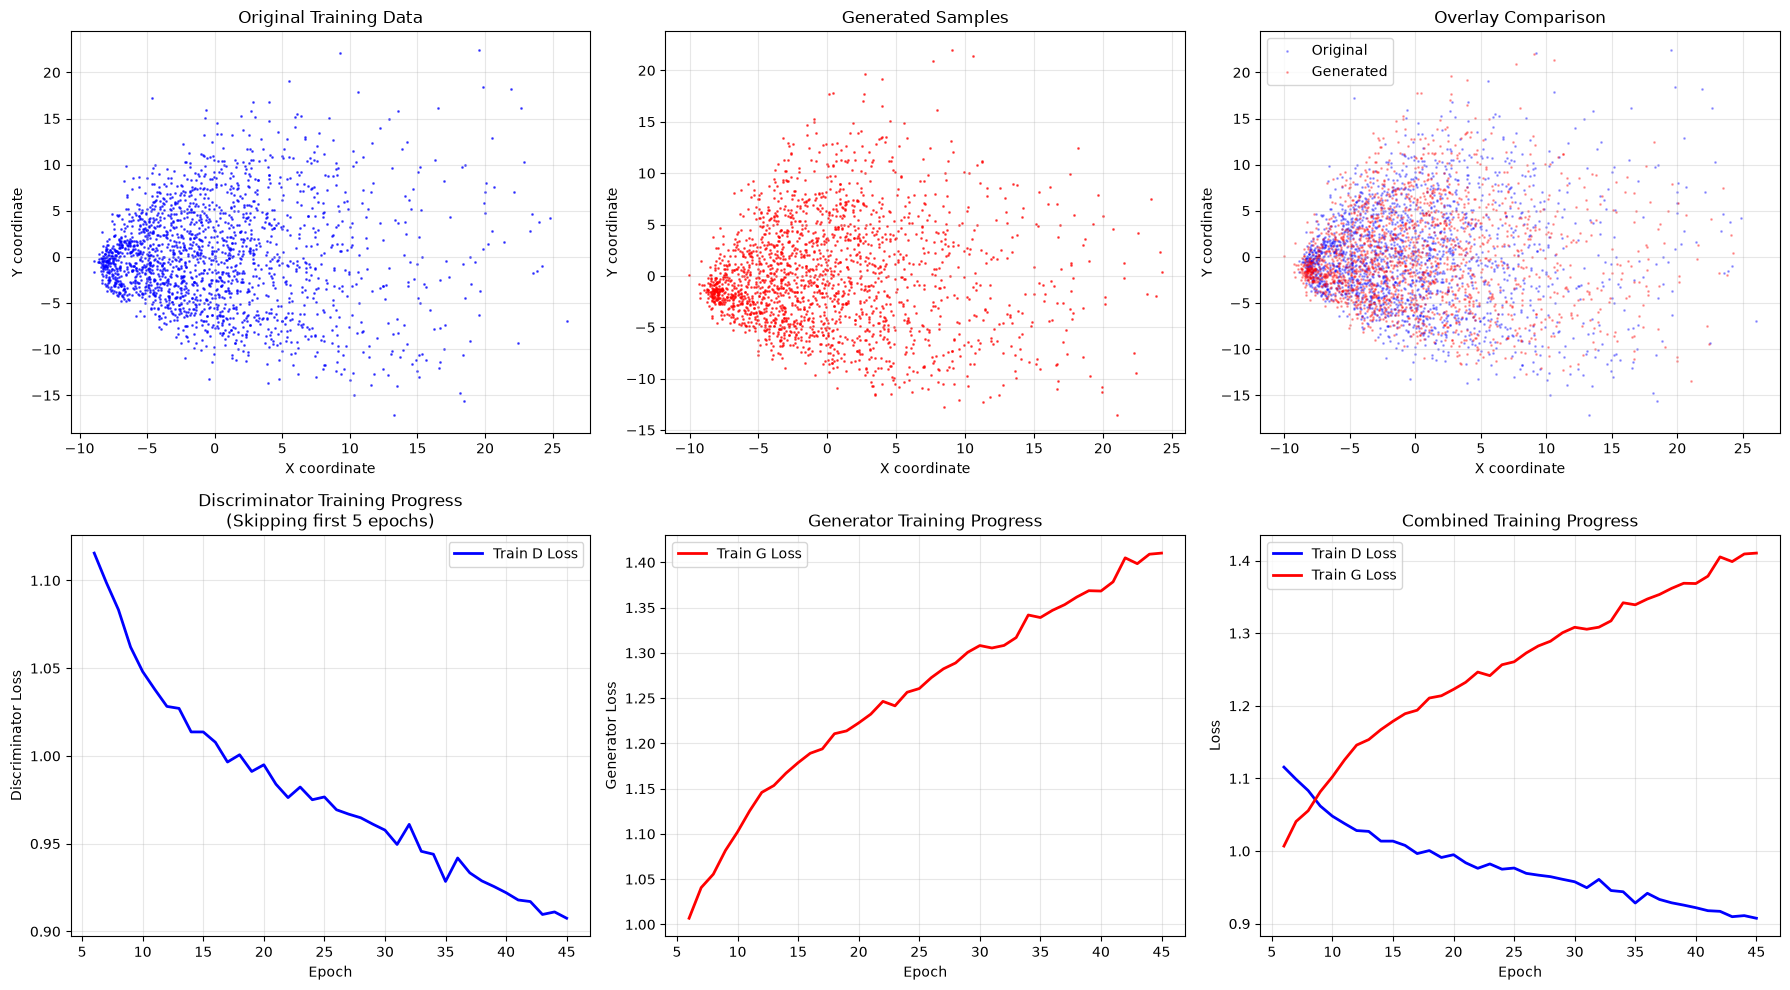

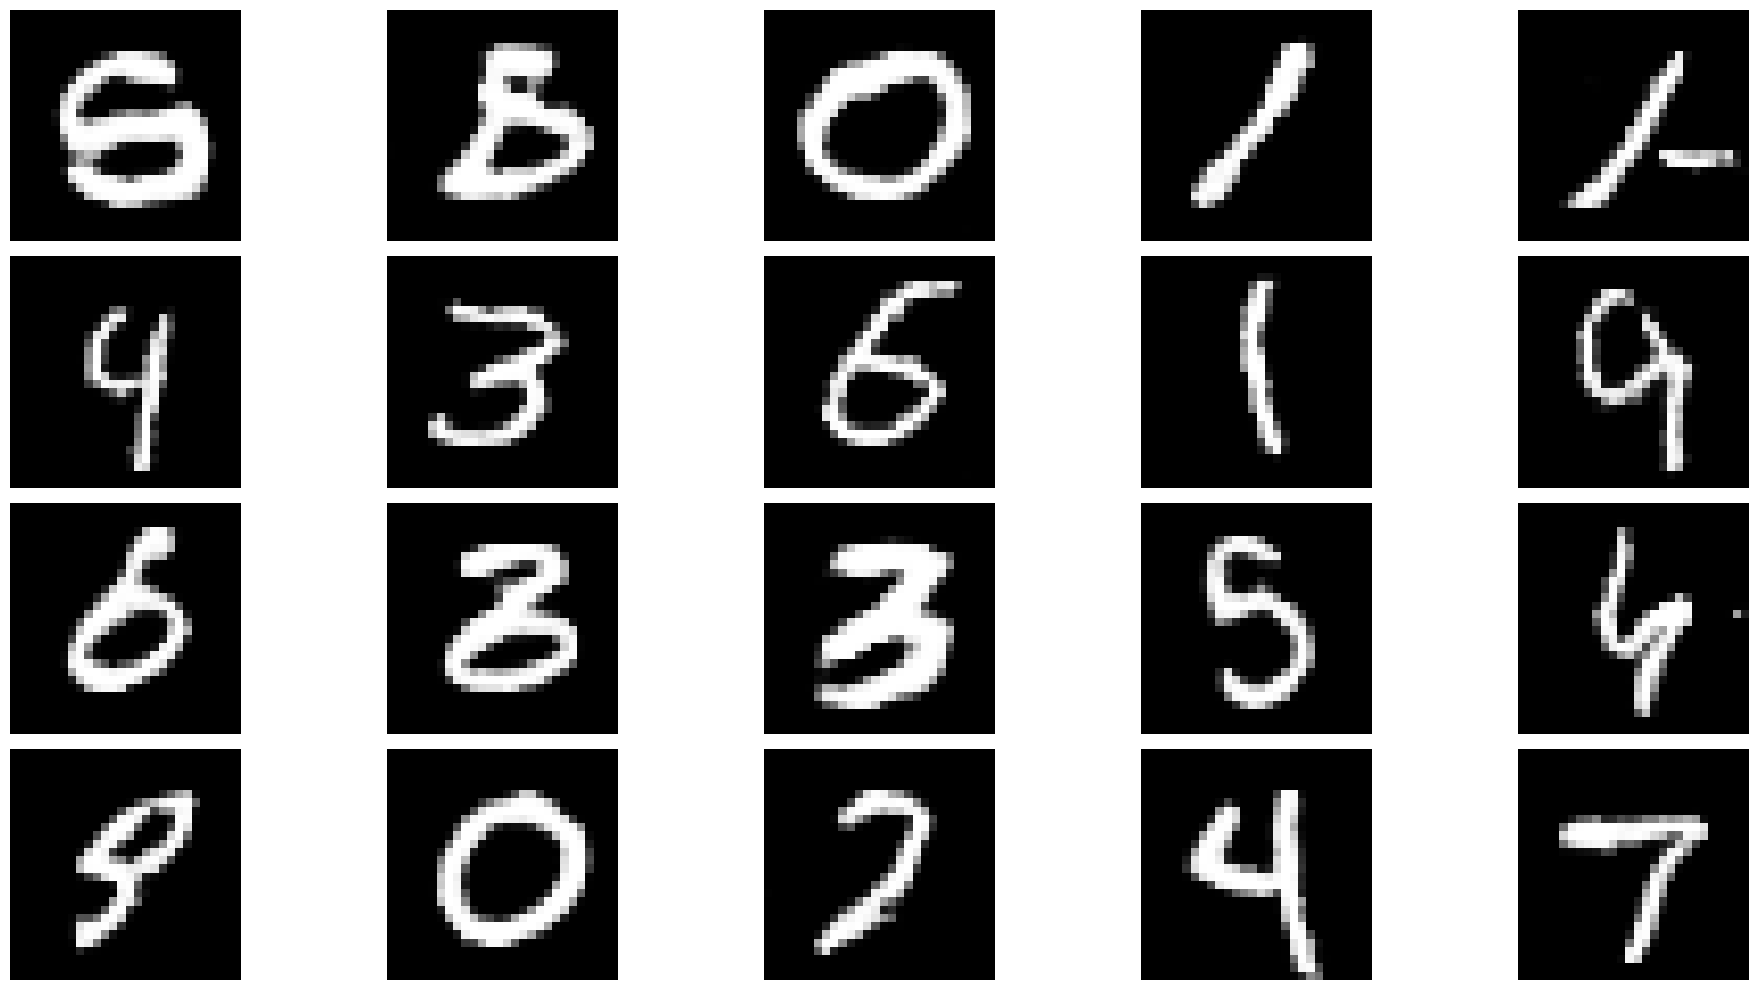

📈 Epoch 45 Summary:
   Train D Loss: 0.9075, Val D Loss: 1.1404
   Train G Loss: 1.4103, Val G Loss: 1.3341

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.800606	G_loss: 1.757110
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.938750	G_loss: 1.138919
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.021558	G_loss: 0.966872
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.938133	G_loss: 1.048733
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.806365	G_loss: 0.997874
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.823634	G_loss: 1.065958
Epoch: 46 [38400/60000 (64%)]	D_loss: 1.078486	G_loss: 2.461711
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.904255	G_loss: 1.562699
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.877824	G_loss: 1.304084
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.869277	G_loss: 0.898426
====> Epoch: 46 Train D_loss: 0.9018, Train G_loss: 1.4277
====> Epoch: 46 Val D_loss: 1.0946, Val G_loss: 1.0850
📈 Epoch 46 Summary:
   Train D Loss: 0.9018, Val D Loss: 1.0946
   Train G Loss: 1.4277

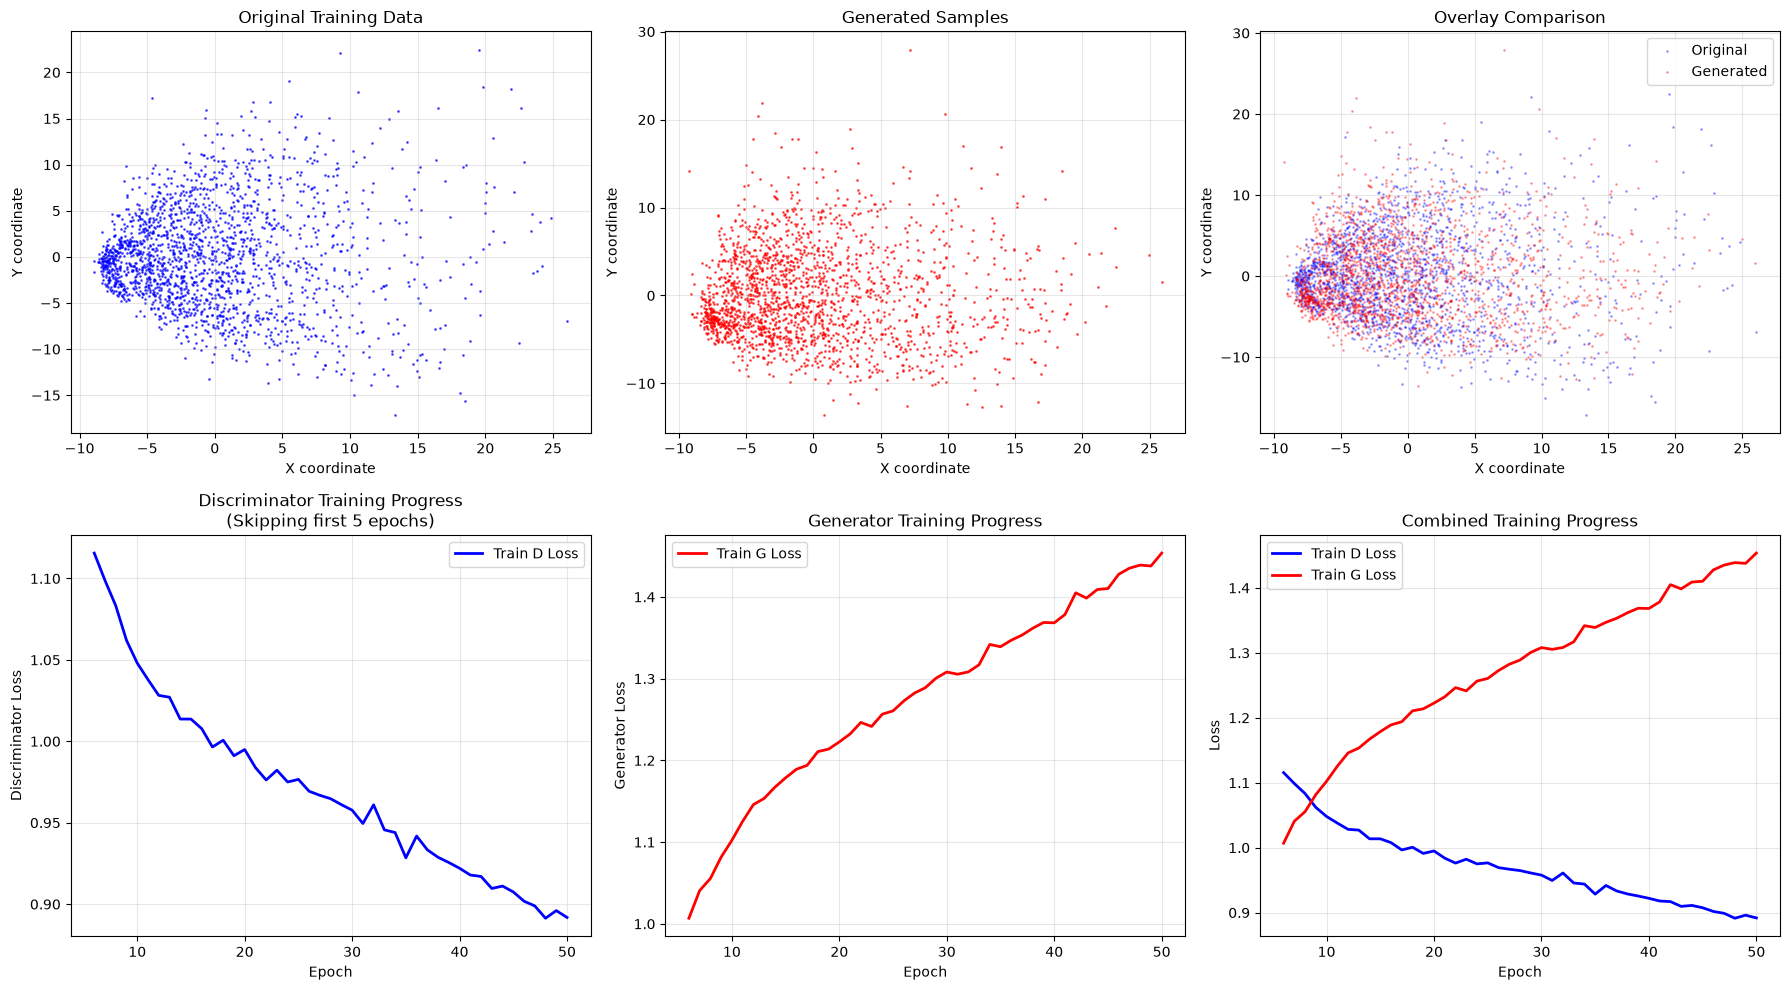

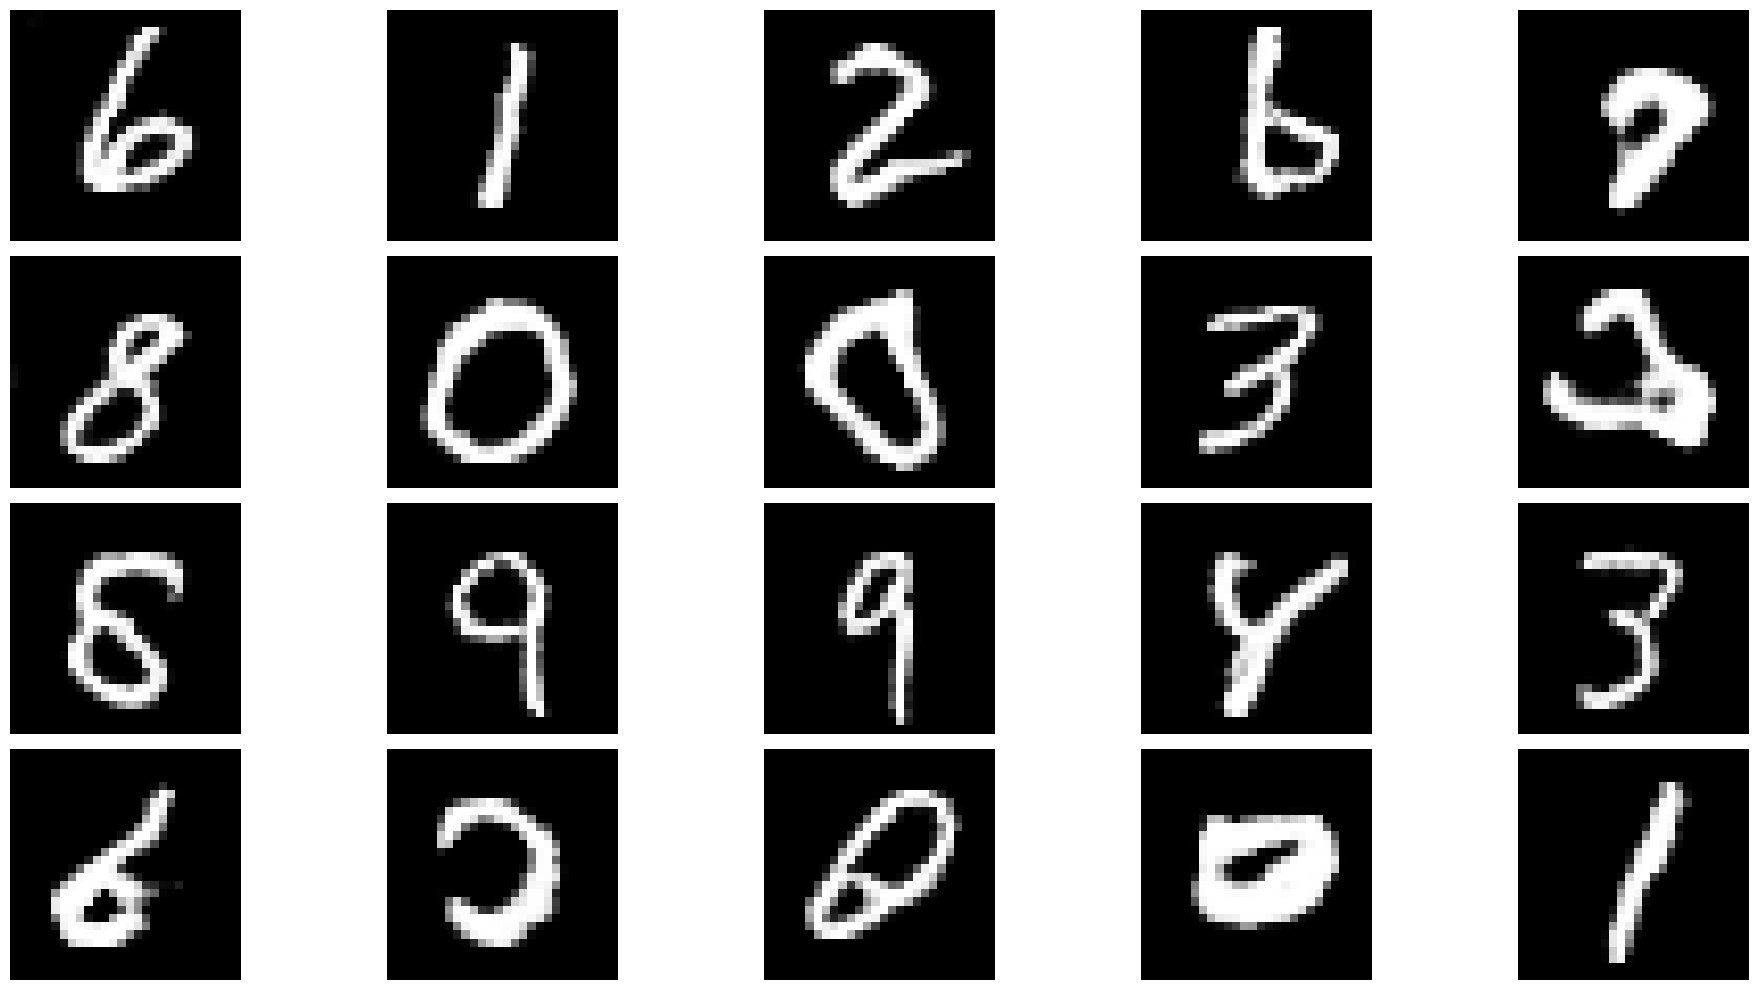

📈 Epoch 50 Summary:
   Train D Loss: 0.8918, Val D Loss: 1.1838
   Train G Loss: 1.4536, Val G Loss: 1.5428

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.866204	G_loss: 0.965508
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.964661	G_loss: 1.939169
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.813883	G_loss: 1.405267
Epoch: 51 [19200/60000 (32%)]	D_loss: 1.009833	G_loss: 1.745088
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.849822	G_loss: 1.605134
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.968729	G_loss: 2.316559
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.805465	G_loss: 1.189322
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.978747	G_loss: 1.116735
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.870769	G_loss: 1.898189
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.874013	G_loss: 1.113172
====> Epoch: 51 Train D_loss: 0.8869, Train G_loss: 1.4633
====> Epoch: 51 Val D_loss: 1.2390, Val G_loss: 1.5929
📈 Epoch 51 Summary:
   Train D Loss: 0.8869, Val D Loss: 1.2390
   Train G Loss: 1.4633

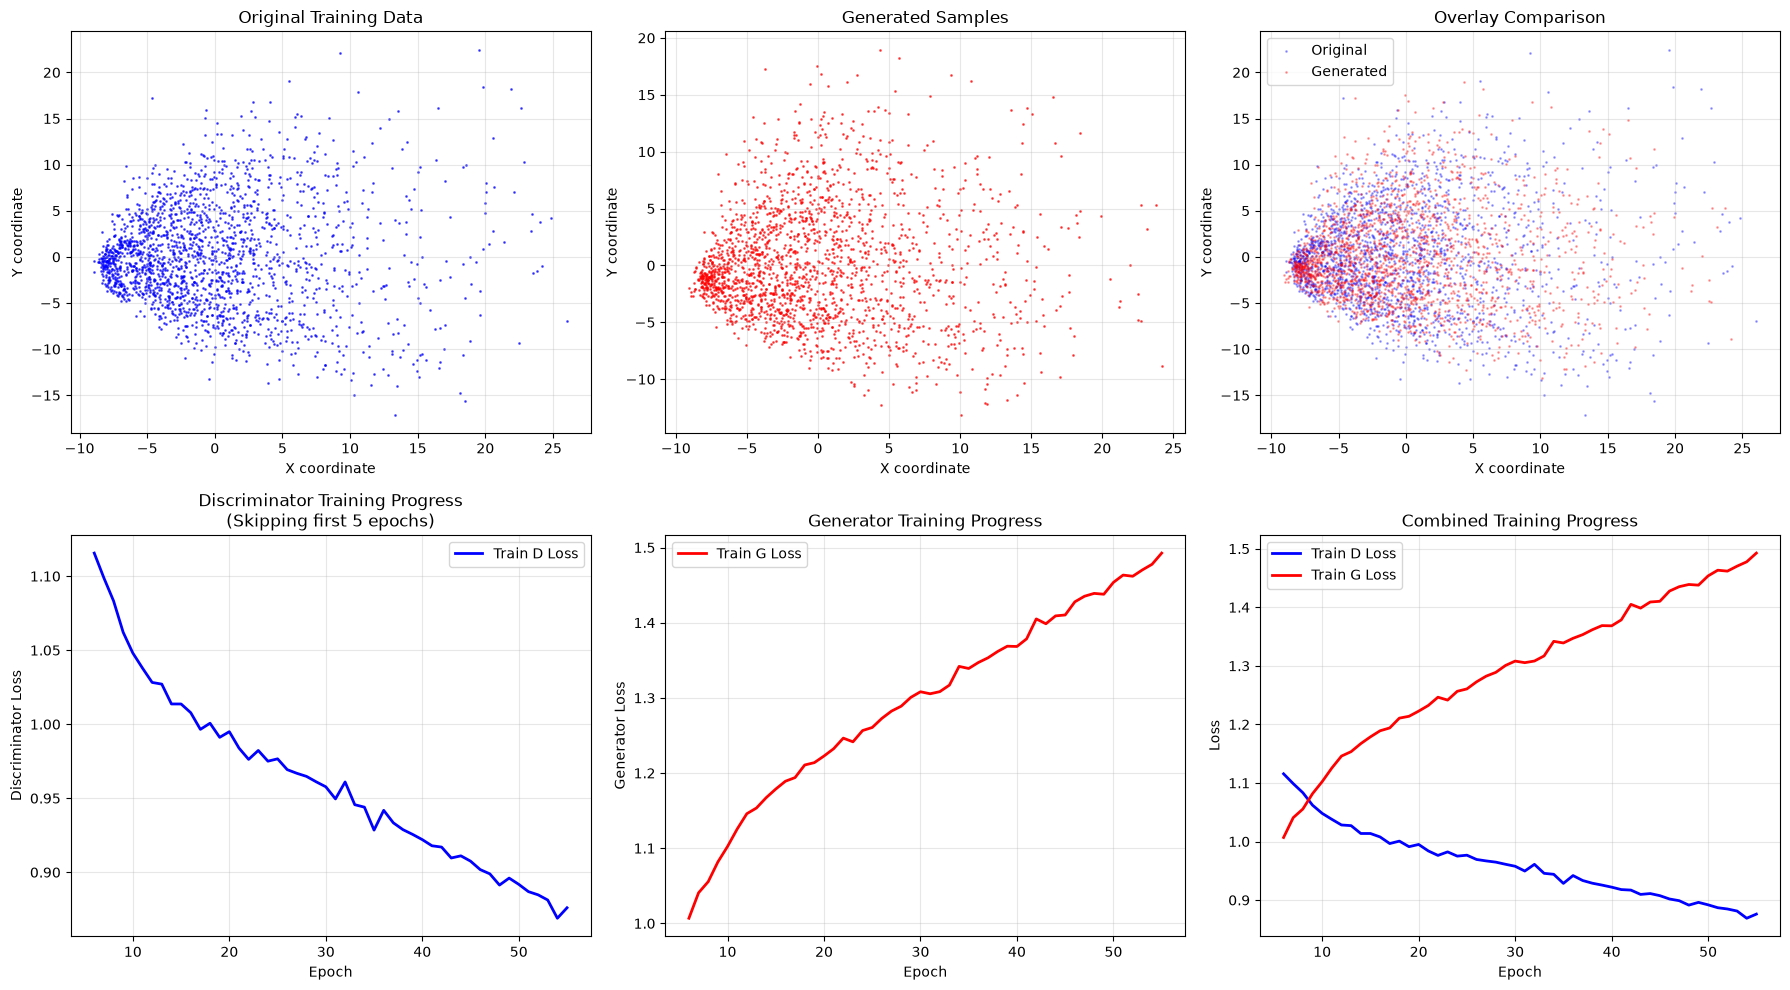

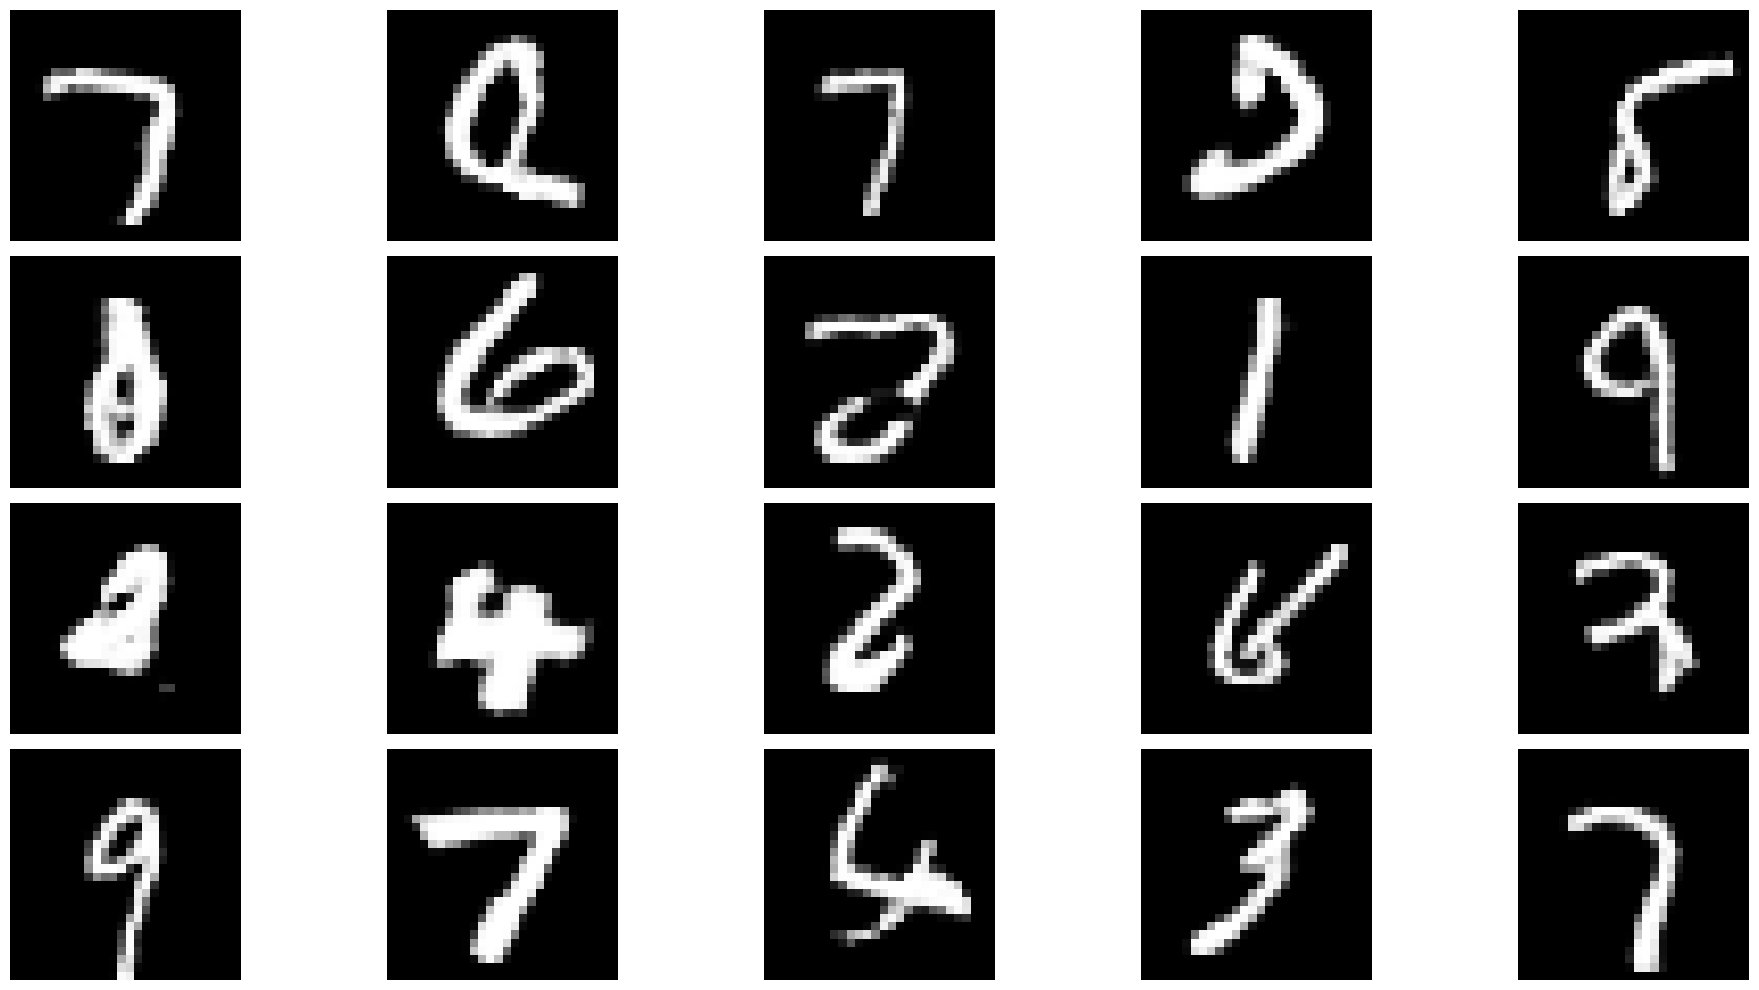

📈 Epoch 55 Summary:
   Train D Loss: 0.8760, Val D Loss: 1.2355
   Train G Loss: 1.4926, Val G Loss: 1.7276

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.791813	G_loss: 0.909667
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.795391	G_loss: 0.883574
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.744767	G_loss: 1.521843
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.768996	G_loss: 1.288544
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.984444	G_loss: 0.744761
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.792882	G_loss: 1.100006
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.804729	G_loss: 1.689935
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.914989	G_loss: 1.150941
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.844042	G_loss: 2.060907
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.874229	G_loss: 1.790794
====> Epoch: 56 Train D_loss: 0.8715, Train G_loss: 1.4959
====> Epoch: 56 Val D_loss: 1.1388, Val G_loss: 1.3884
📈 Epoch 56 Summary:
   Train D Loss: 0.8715, Val D Loss: 1.1388
   Train G Loss: 1.4959

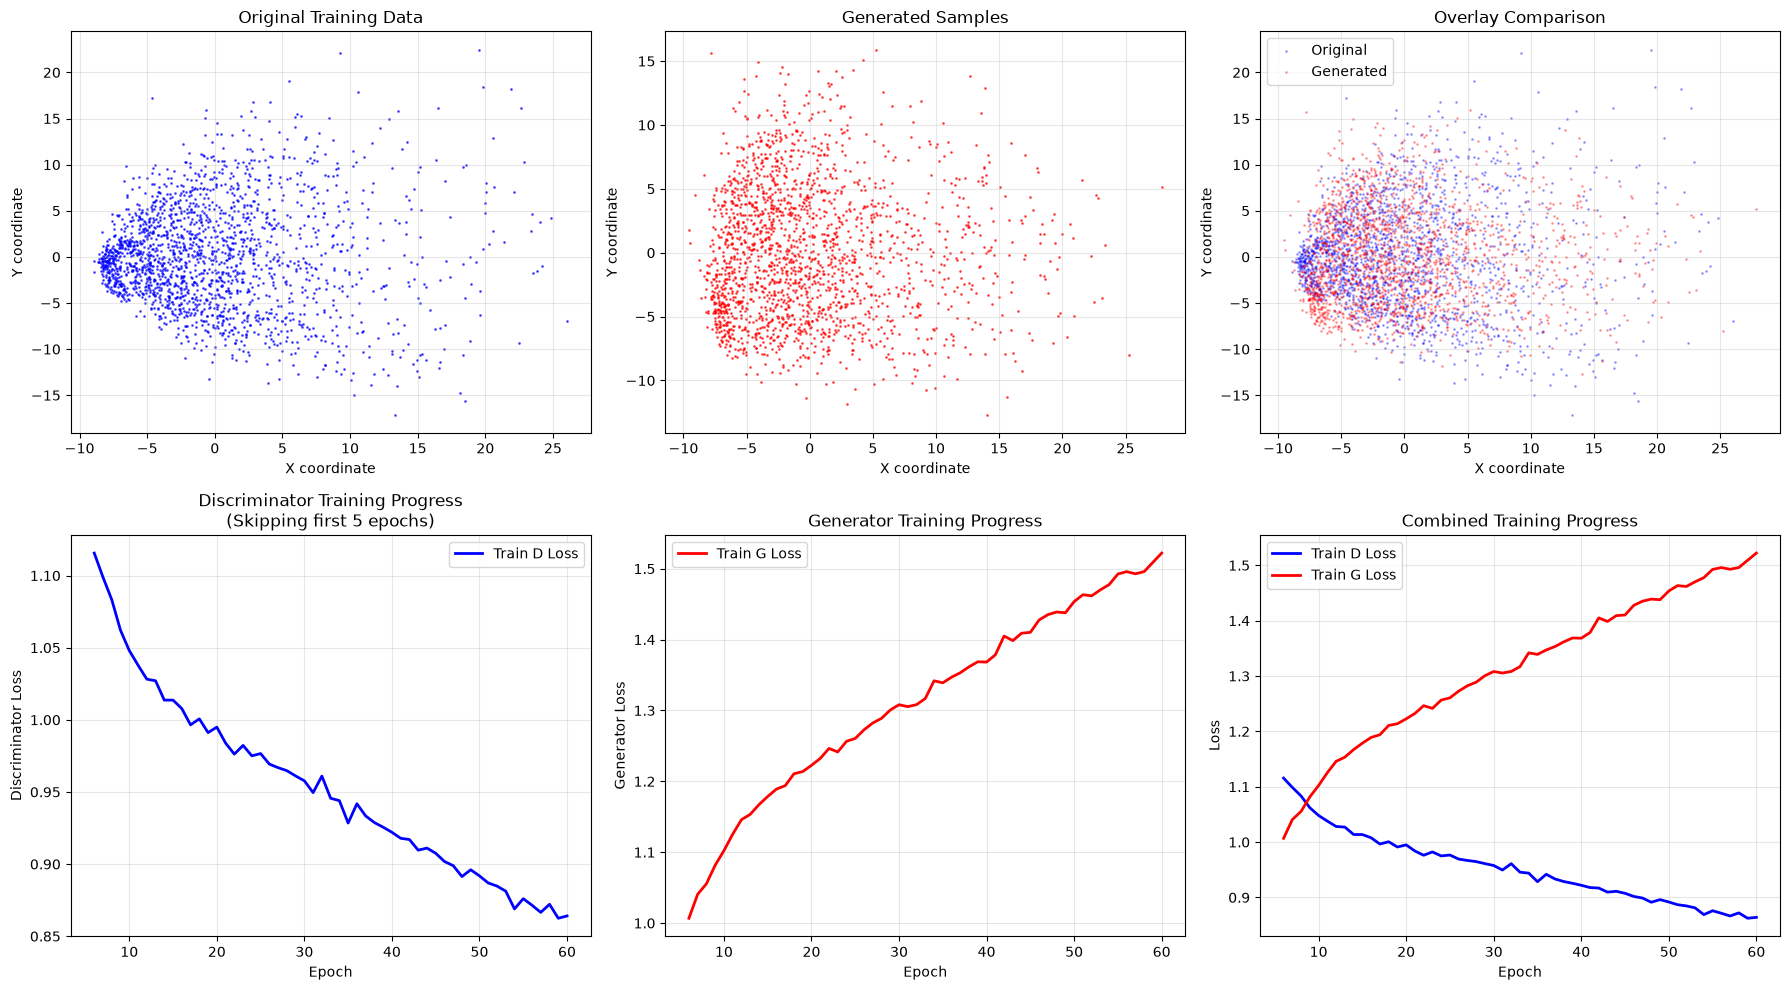

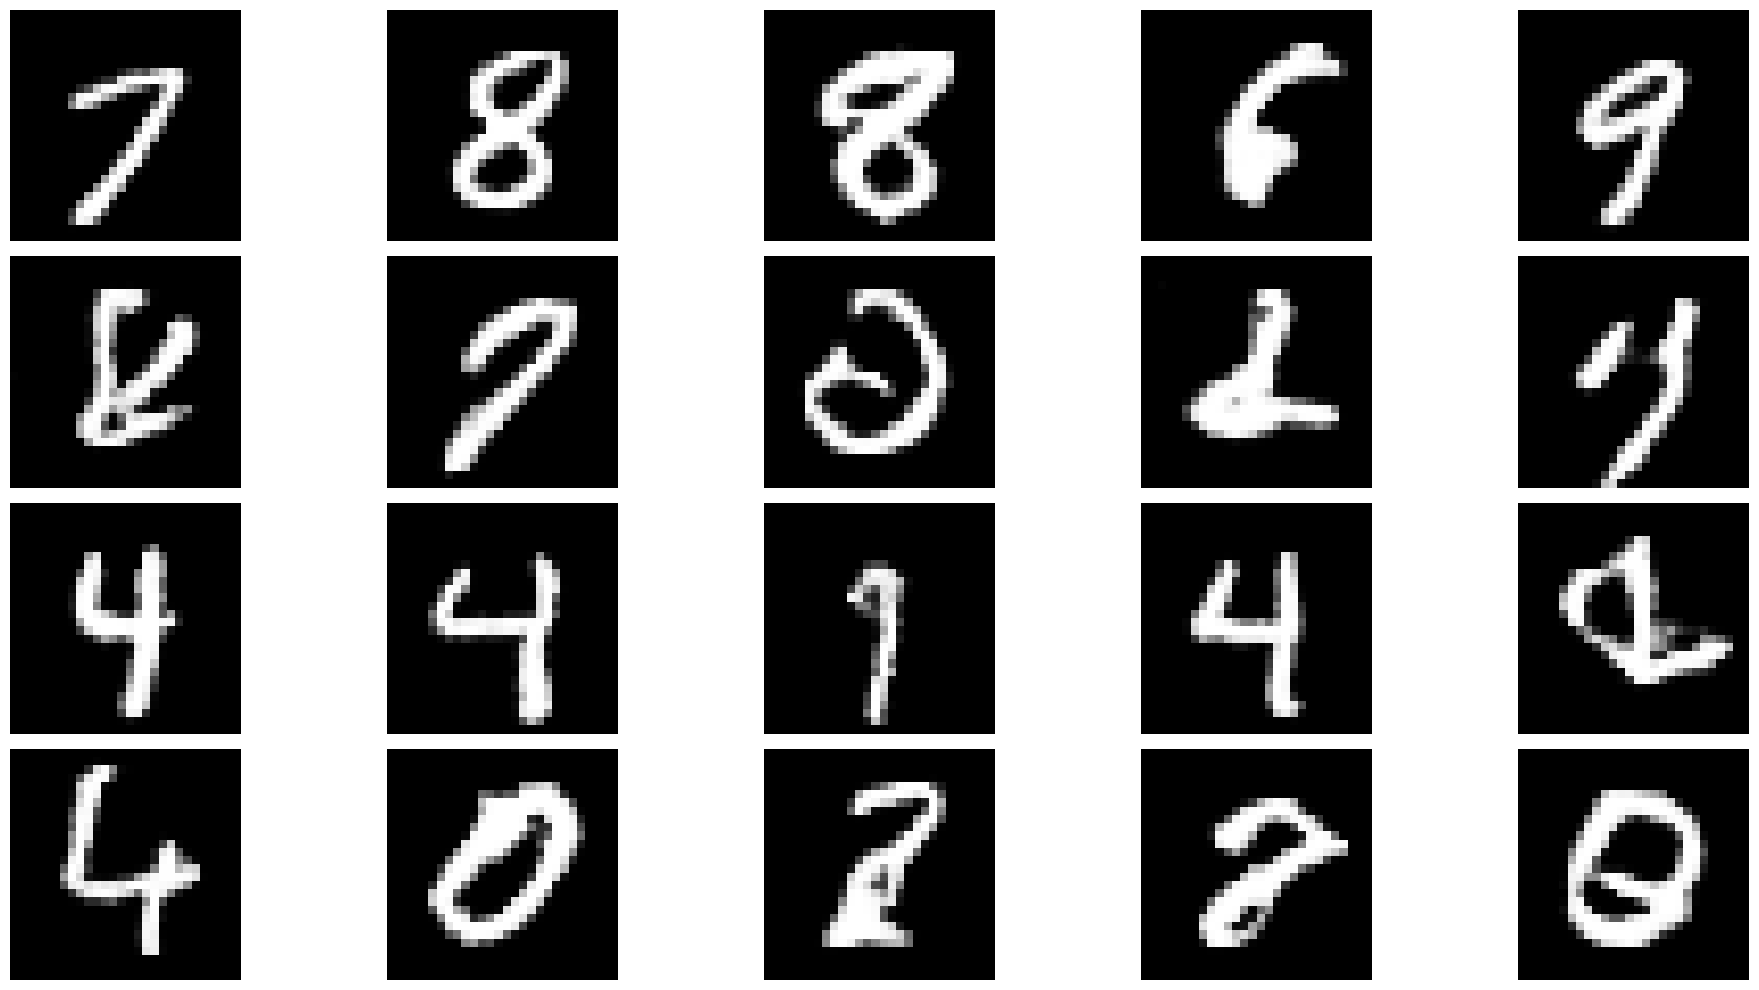

📈 Epoch 60 Summary:
   Train D Loss: 0.8640, Val D Loss: 1.1344
   Train G Loss: 1.5221, Val G Loss: 1.4576

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.805704	G_loss: 1.740471
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.803889	G_loss: 1.786647
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.845388	G_loss: 1.357357
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.763068	G_loss: 1.969032
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.866806	G_loss: 1.583958
Epoch: 61 [32000/60000 (53%)]	D_loss: 1.031809	G_loss: 1.742204
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.903343	G_loss: 1.072241
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.927781	G_loss: 1.696149
Epoch: 61 [51200/60000 (85%)]	D_loss: 1.049474	G_loss: 1.008271
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.834932	G_loss: 0.979519
====> Epoch: 61 Train D_loss: 0.8524, Train G_loss: 1.5259
====> Epoch: 61 Val D_loss: 1.0897, Val G_loss: 1.0955
📈 Epoch 61 Summary:
   Train D Loss: 0.8524, Val D Loss: 1.0897
   Train G Loss: 1.5259

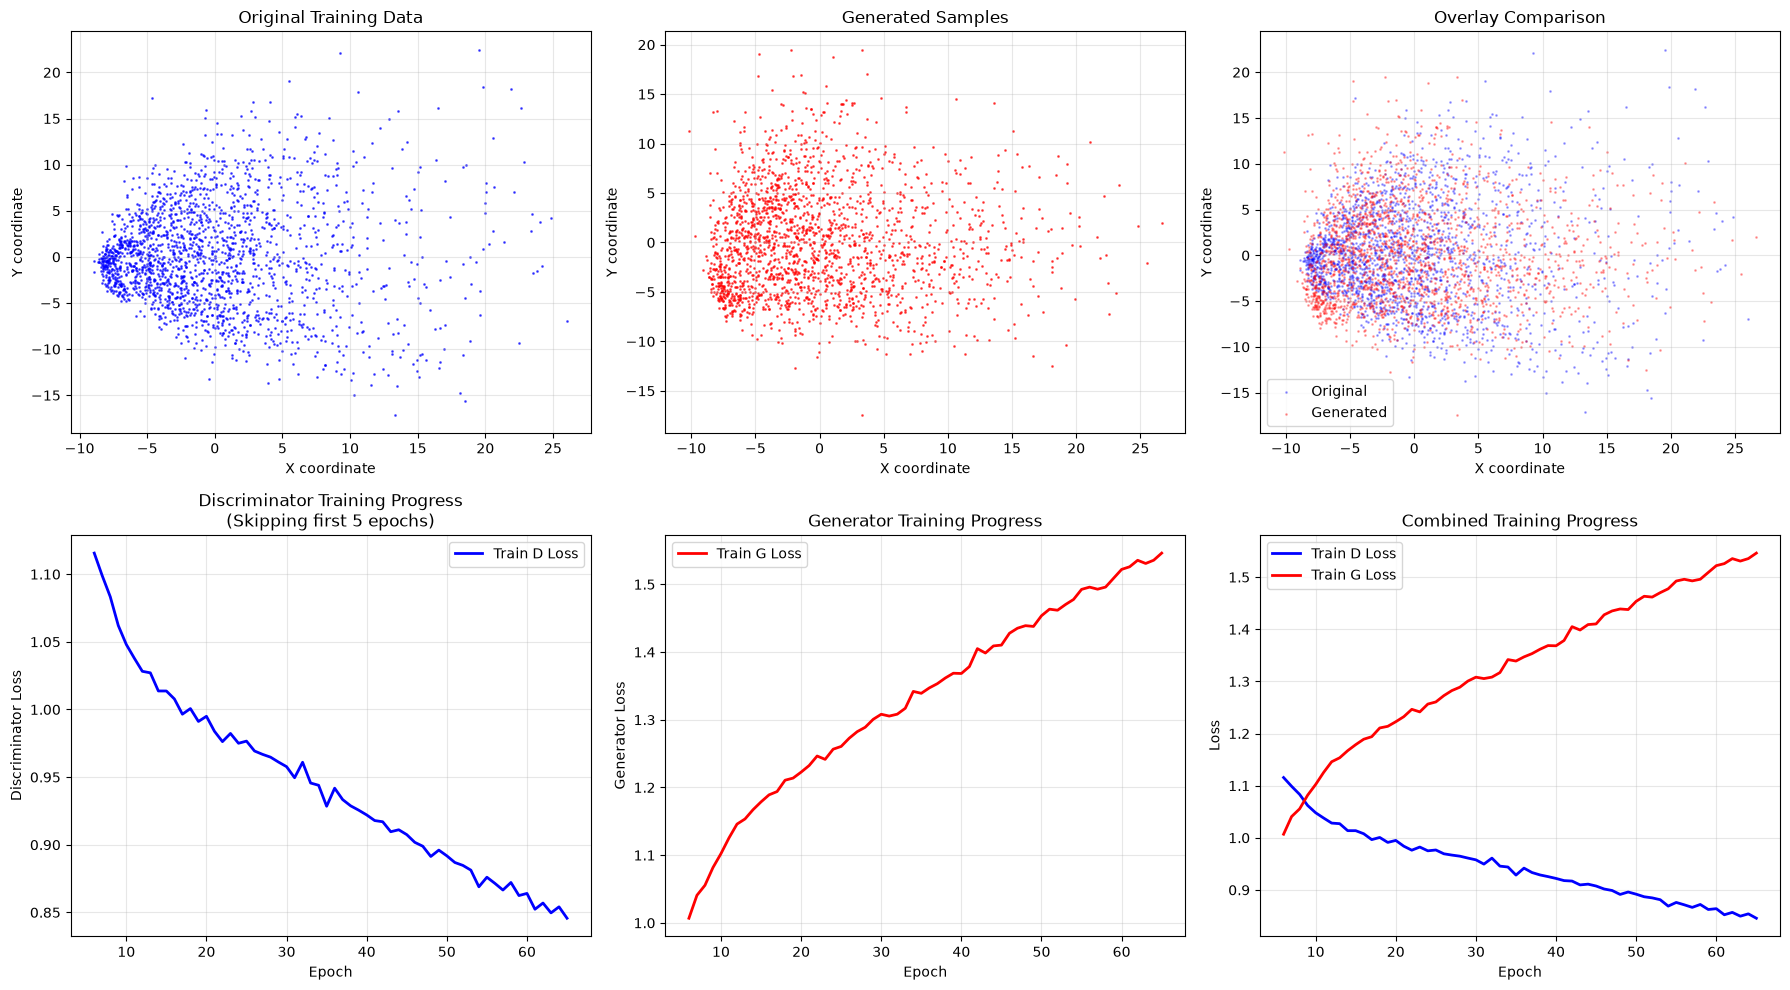

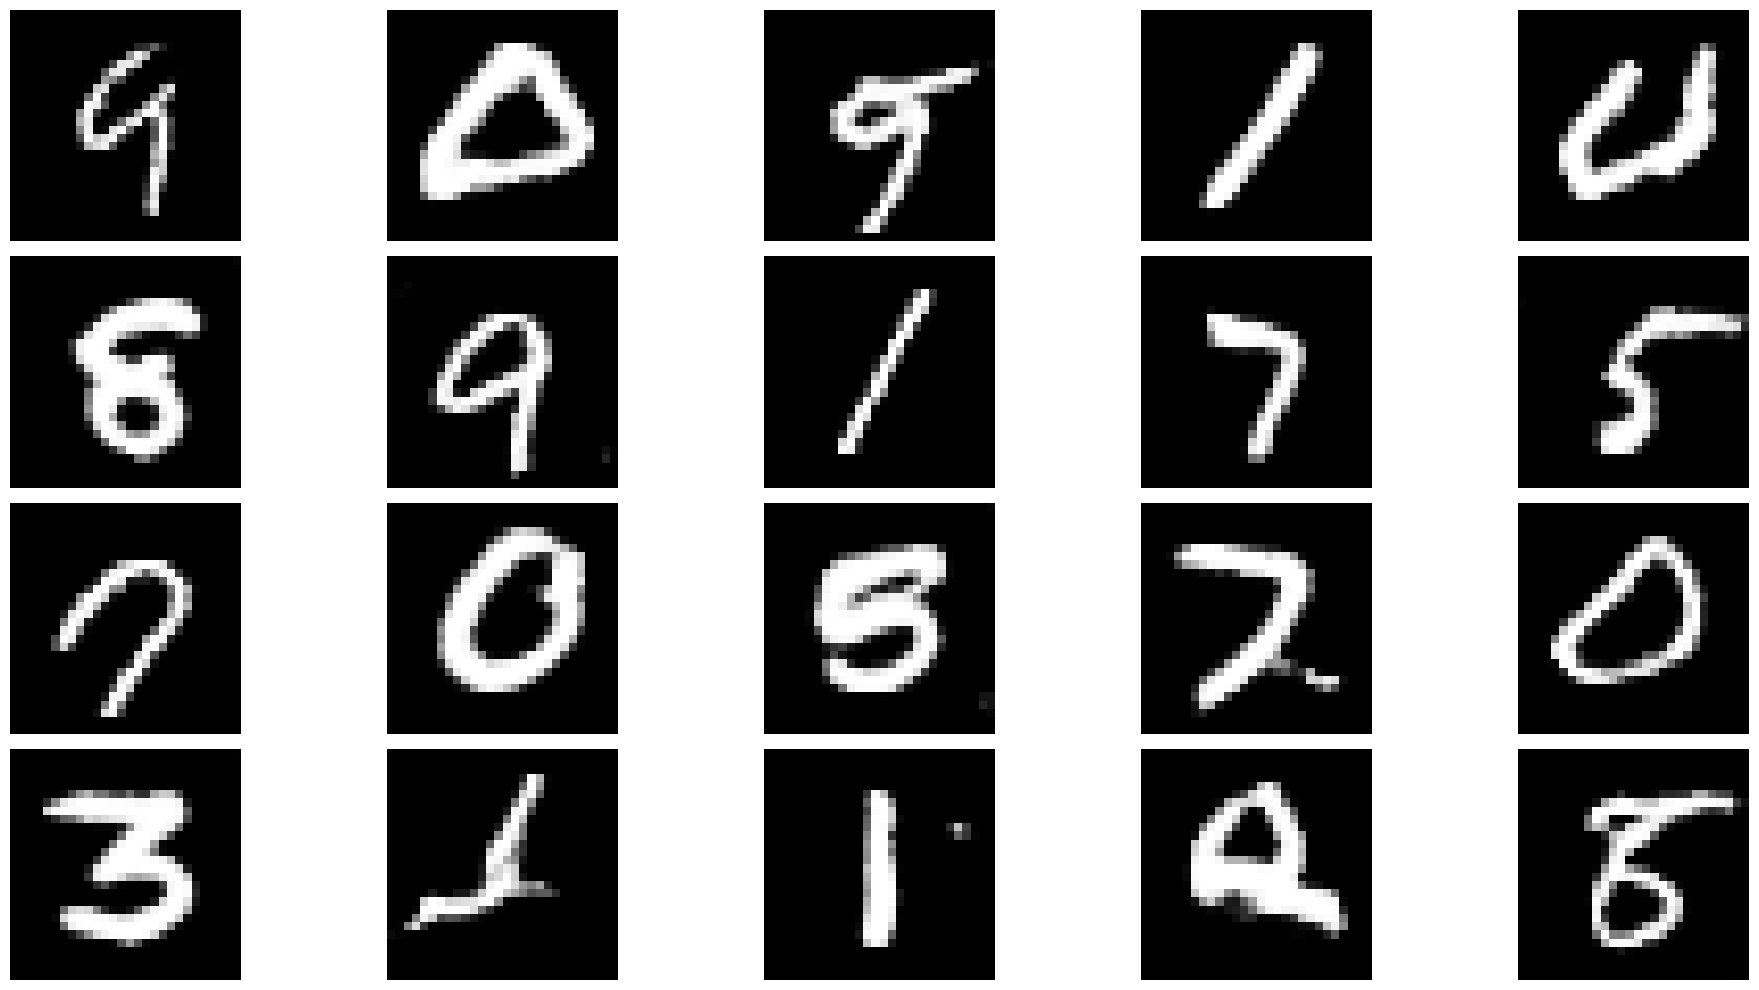

📈 Epoch 65 Summary:
   Train D Loss: 0.8457, Val D Loss: 1.5942
   Train G Loss: 1.5461, Val G Loss: 0.4218

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 1.114973	G_loss: 1.934317
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.838869	G_loss: 1.671793
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.804325	G_loss: 2.397861
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.789748	G_loss: 1.626531
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.745412	G_loss: 1.725140
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.801652	G_loss: 1.336007
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.844515	G_loss: 2.018537
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.825316	G_loss: 0.946356
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.688857	G_loss: 1.334829
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.679774	G_loss: 1.287787
====> Epoch: 66 Train D_loss: 0.8339, Train G_loss: 1.5582
====> Epoch: 66 Val D_loss: 1.1239, Val G_loss: 1.4909
📈 Epoch 66 Summary:
   Train D Loss: 0.8339, Val D Loss: 1.1239
   Train G Loss: 1.5582

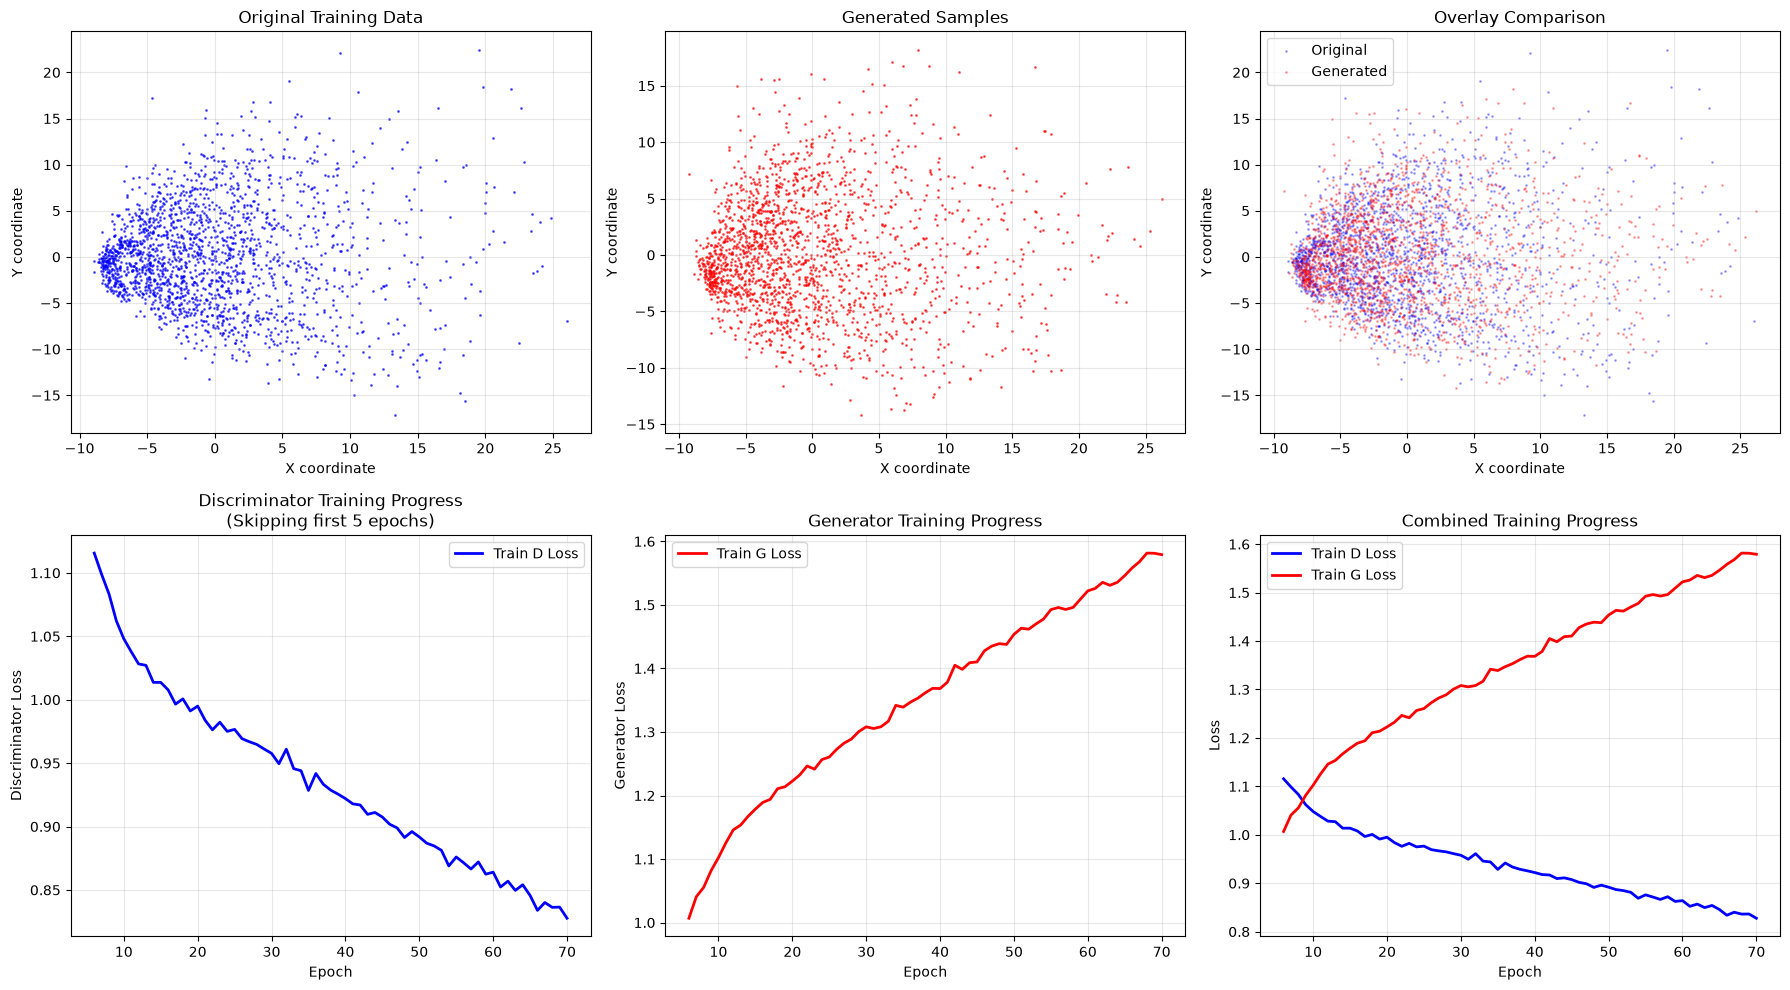

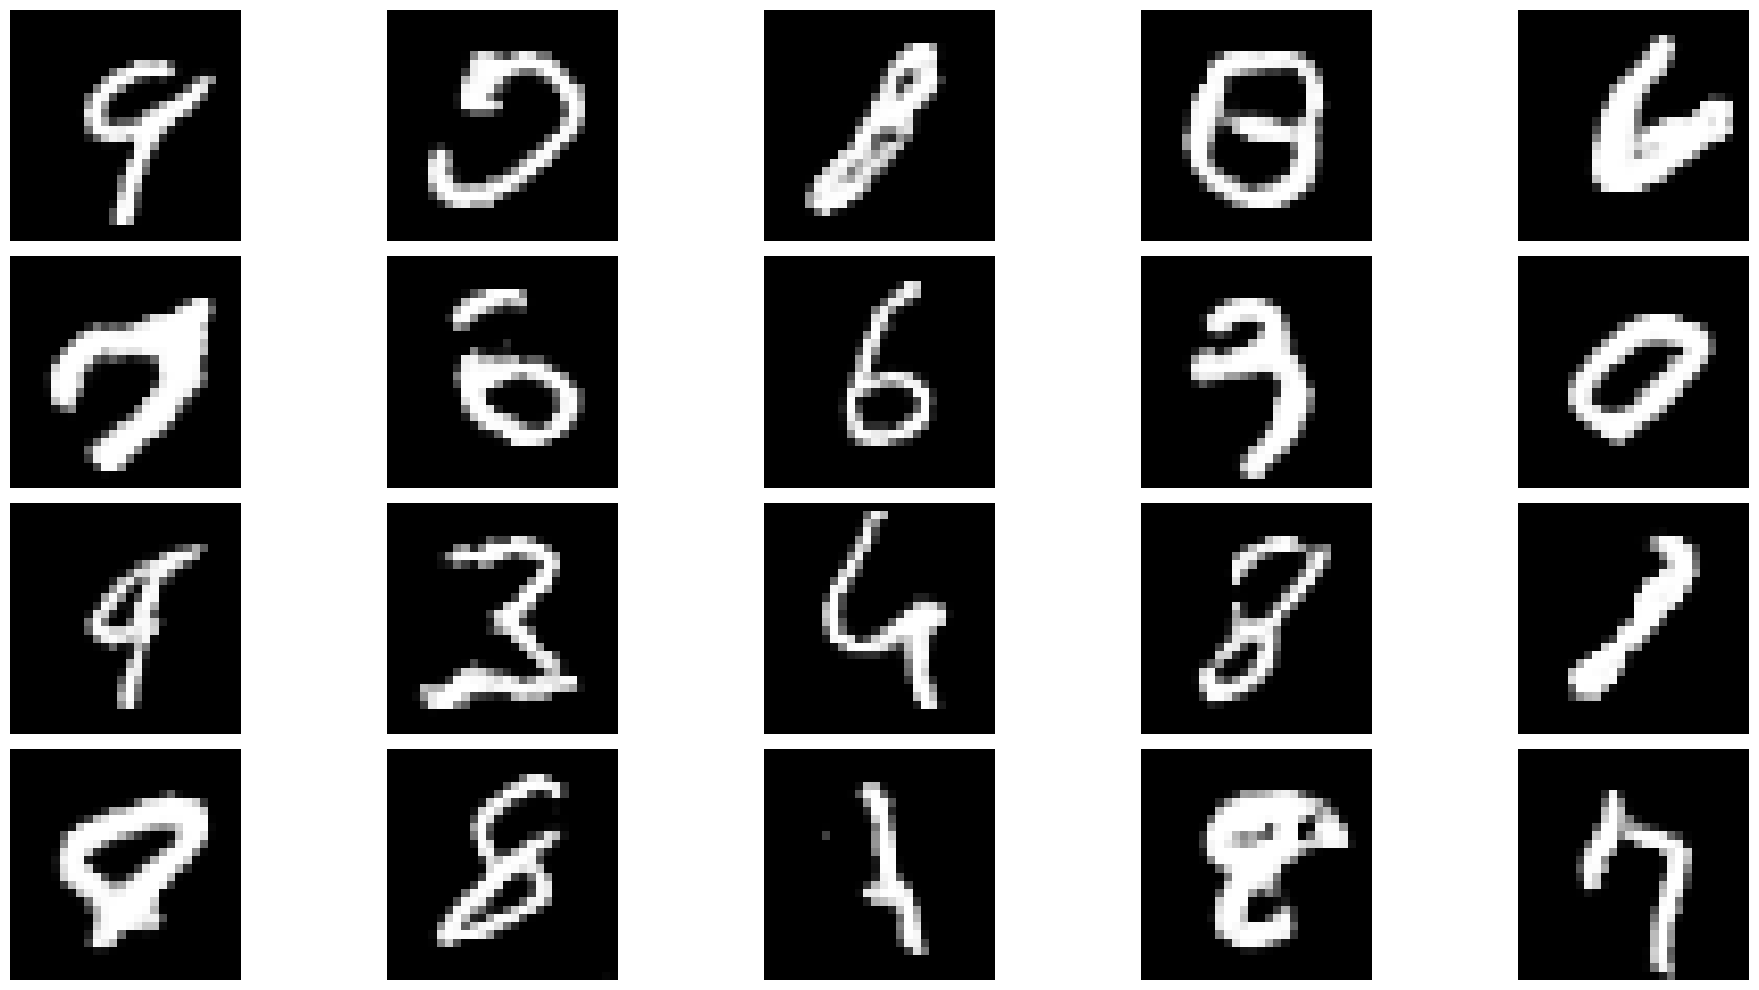

📈 Epoch 70 Summary:
   Train D Loss: 0.8277, Val D Loss: 1.1129
   Train G Loss: 1.5791, Val G Loss: 1.1861

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.770084	G_loss: 1.574386
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.799247	G_loss: 1.595353
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.971553	G_loss: 2.069674
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.842638	G_loss: 1.266964
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.918232	G_loss: 1.187530
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.755213	G_loss: 1.364396
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.905145	G_loss: 1.533892
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.951976	G_loss: 1.914530
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.894563	G_loss: 1.873536
Epoch: 71 [57600/60000 (96%)]	D_loss: 1.095790	G_loss: 0.726468
====> Epoch: 71 Train D_loss: 0.8271, Train G_loss: 1.5829
====> Epoch: 71 Val D_loss: 1.6205, Val G_loss: 2.5103
📈 Epoch 71 Summary:
   Train D Loss: 0.8271, Val D Loss: 1.6205
   Train G Loss: 1.5829

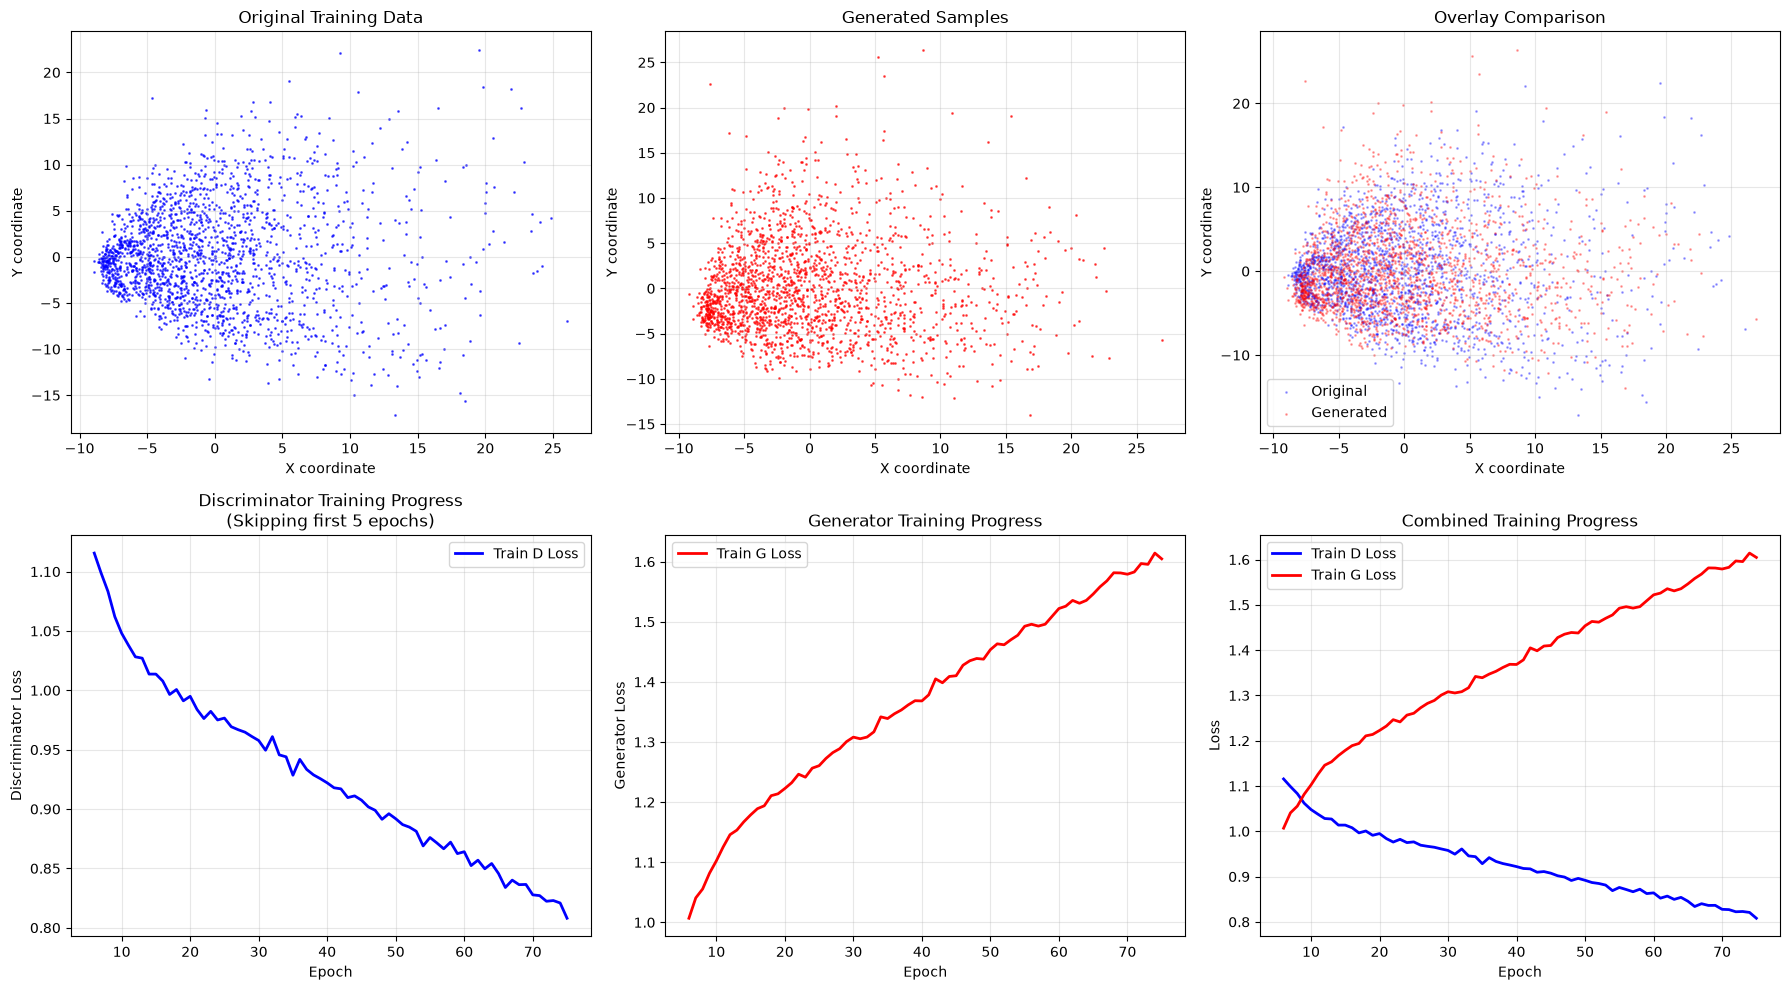

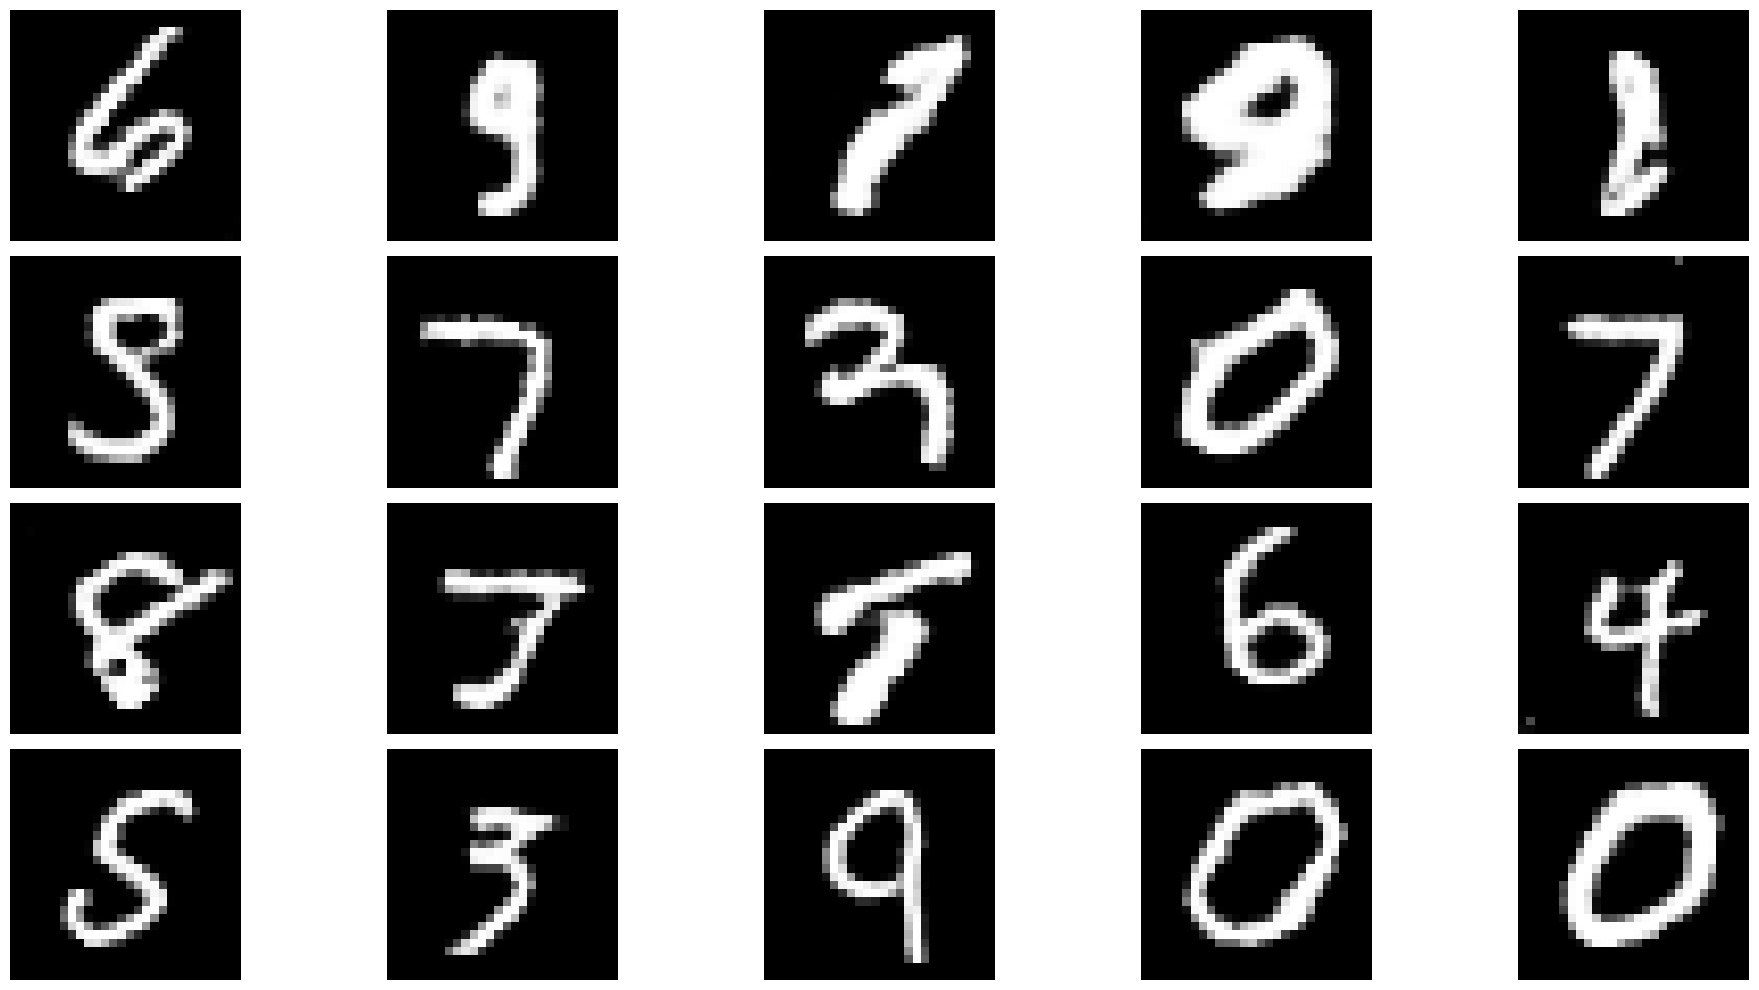

📈 Epoch 75 Summary:
   Train D Loss: 0.8080, Val D Loss: 1.0994
   Train G Loss: 1.6047, Val G Loss: 1.1754

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.847967	G_loss: 2.185452
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.933446	G_loss: 0.928304
Epoch: 76 [12800/60000 (21%)]	D_loss: 1.234516	G_loss: 2.943178
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.917597	G_loss: 0.952286
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.719717	G_loss: 1.677080
Epoch: 76 [32000/60000 (53%)]	D_loss: 1.012717	G_loss: 2.354277
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.706182	G_loss: 1.758221
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.714816	G_loss: 1.819025
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.695713	G_loss: 1.517699
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.746872	G_loss: 1.915374
====> Epoch: 76 Train D_loss: 0.8179, Train G_loss: 1.6378
====> Epoch: 76 Val D_loss: 1.1411, Val G_loss: 0.9172
📈 Epoch 76 Summary:
   Train D Loss: 0.8179, Val D Loss: 1.1411
   Train G Loss: 1.6378

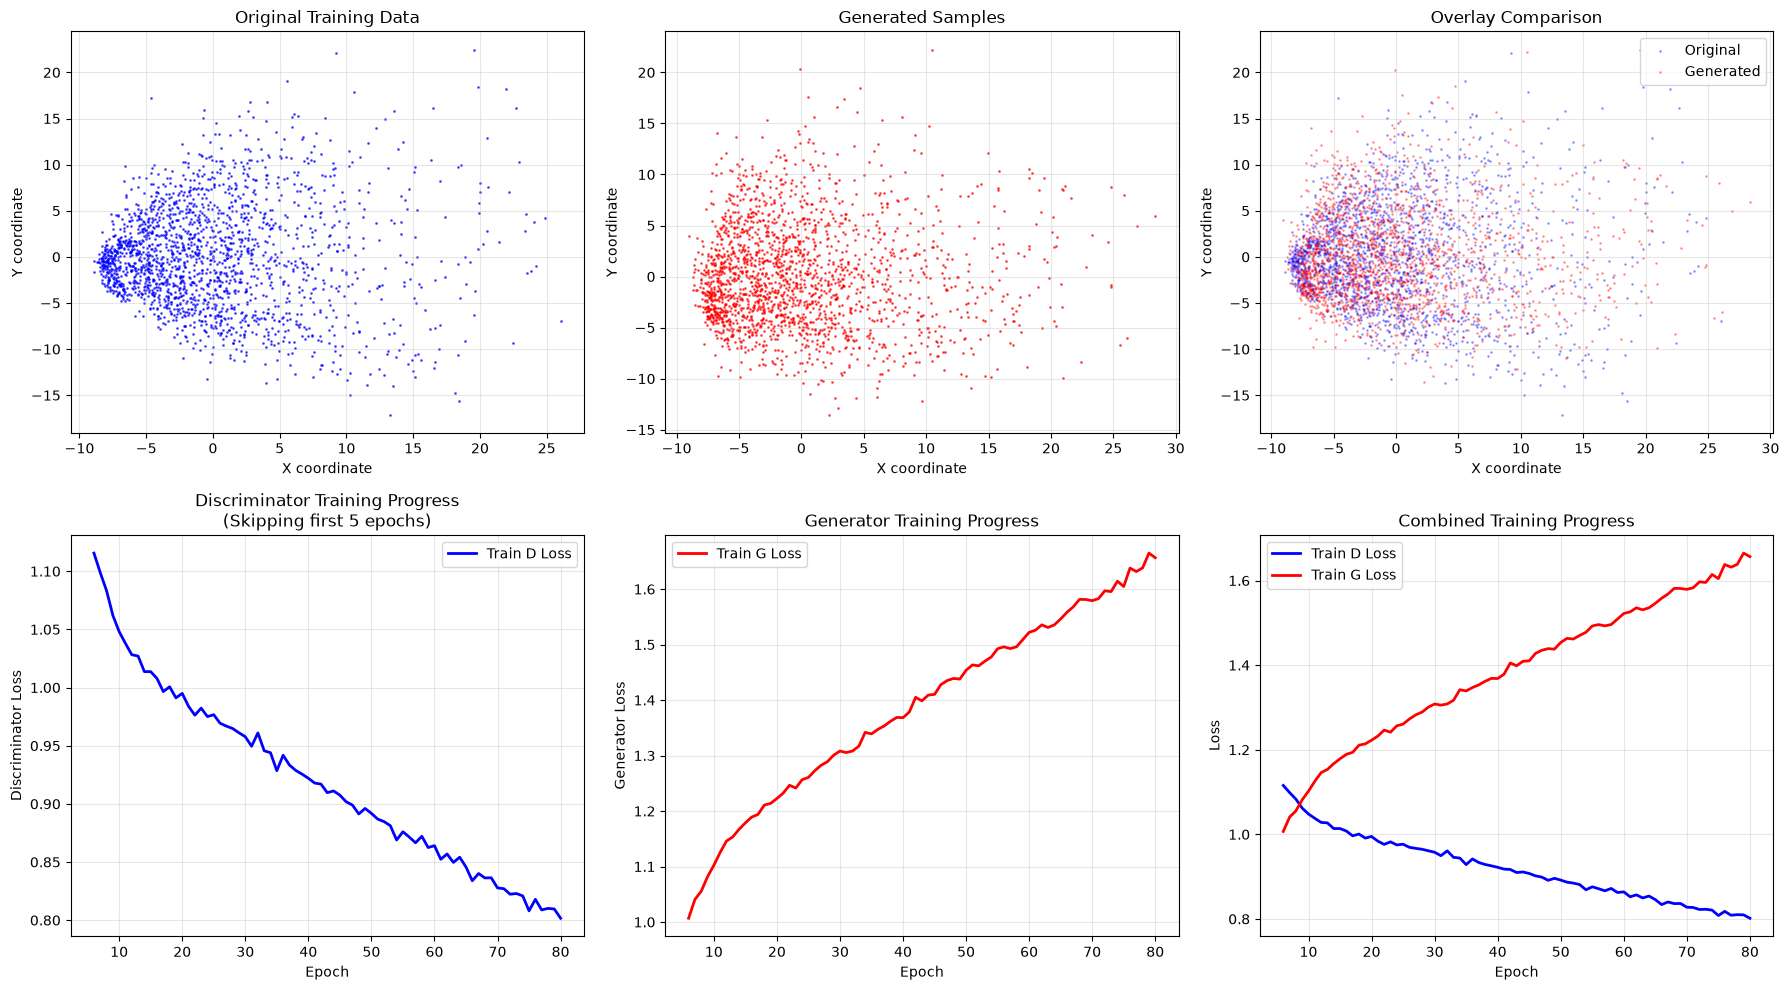

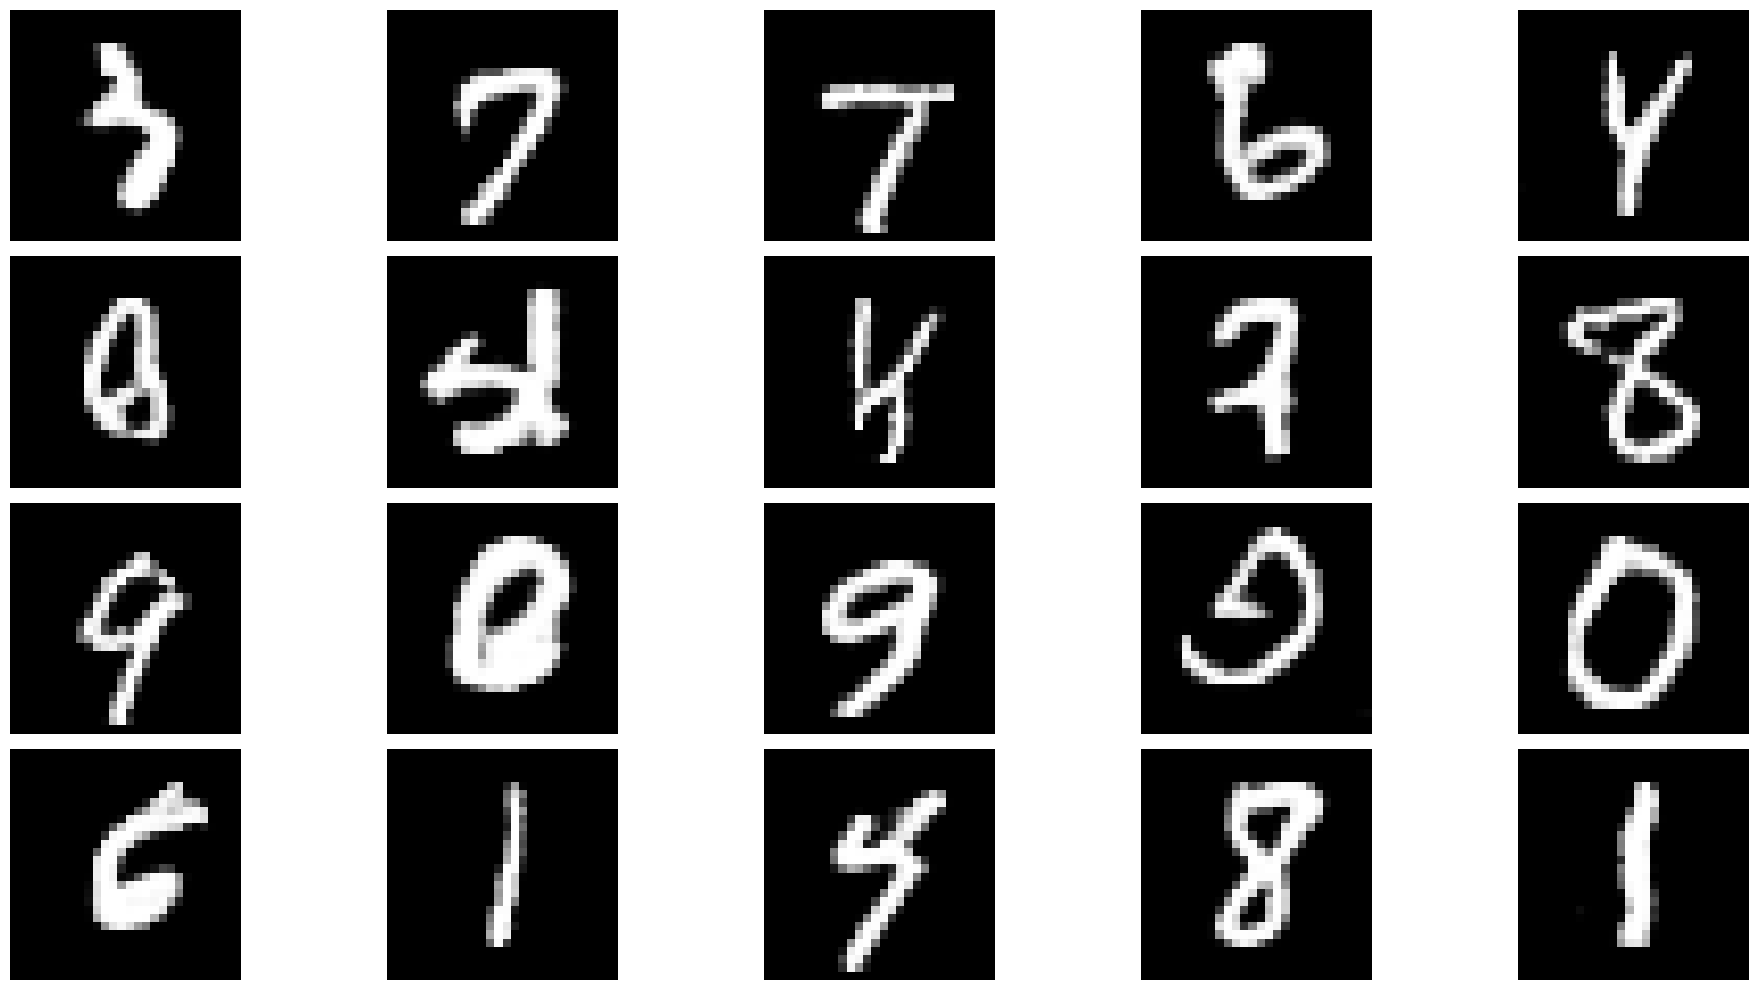

📈 Epoch 80 Summary:
   Train D Loss: 0.8017, Val D Loss: 1.4023
   Train G Loss: 1.6565, Val G Loss: 2.1889

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.934580	G_loss: 0.959011
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.981984	G_loss: 0.915382
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.740812	G_loss: 2.025857
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.617085	G_loss: 1.819239
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.888376	G_loss: 2.054894
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.770753	G_loss: 1.835362
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.971971	G_loss: 1.109849
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.734965	G_loss: 1.494107
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.606340	G_loss: 1.730863
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.786755	G_loss: 0.878542
====> Epoch: 81 Train D_loss: 0.7973, Train G_loss: 1.6498
====> Epoch: 81 Val D_loss: 1.9974, Val G_loss: 0.2924
📈 Epoch 81 Summary:
   Train D Loss: 0.7973, Val D Loss: 1.9974
   Train G Loss: 1.6498

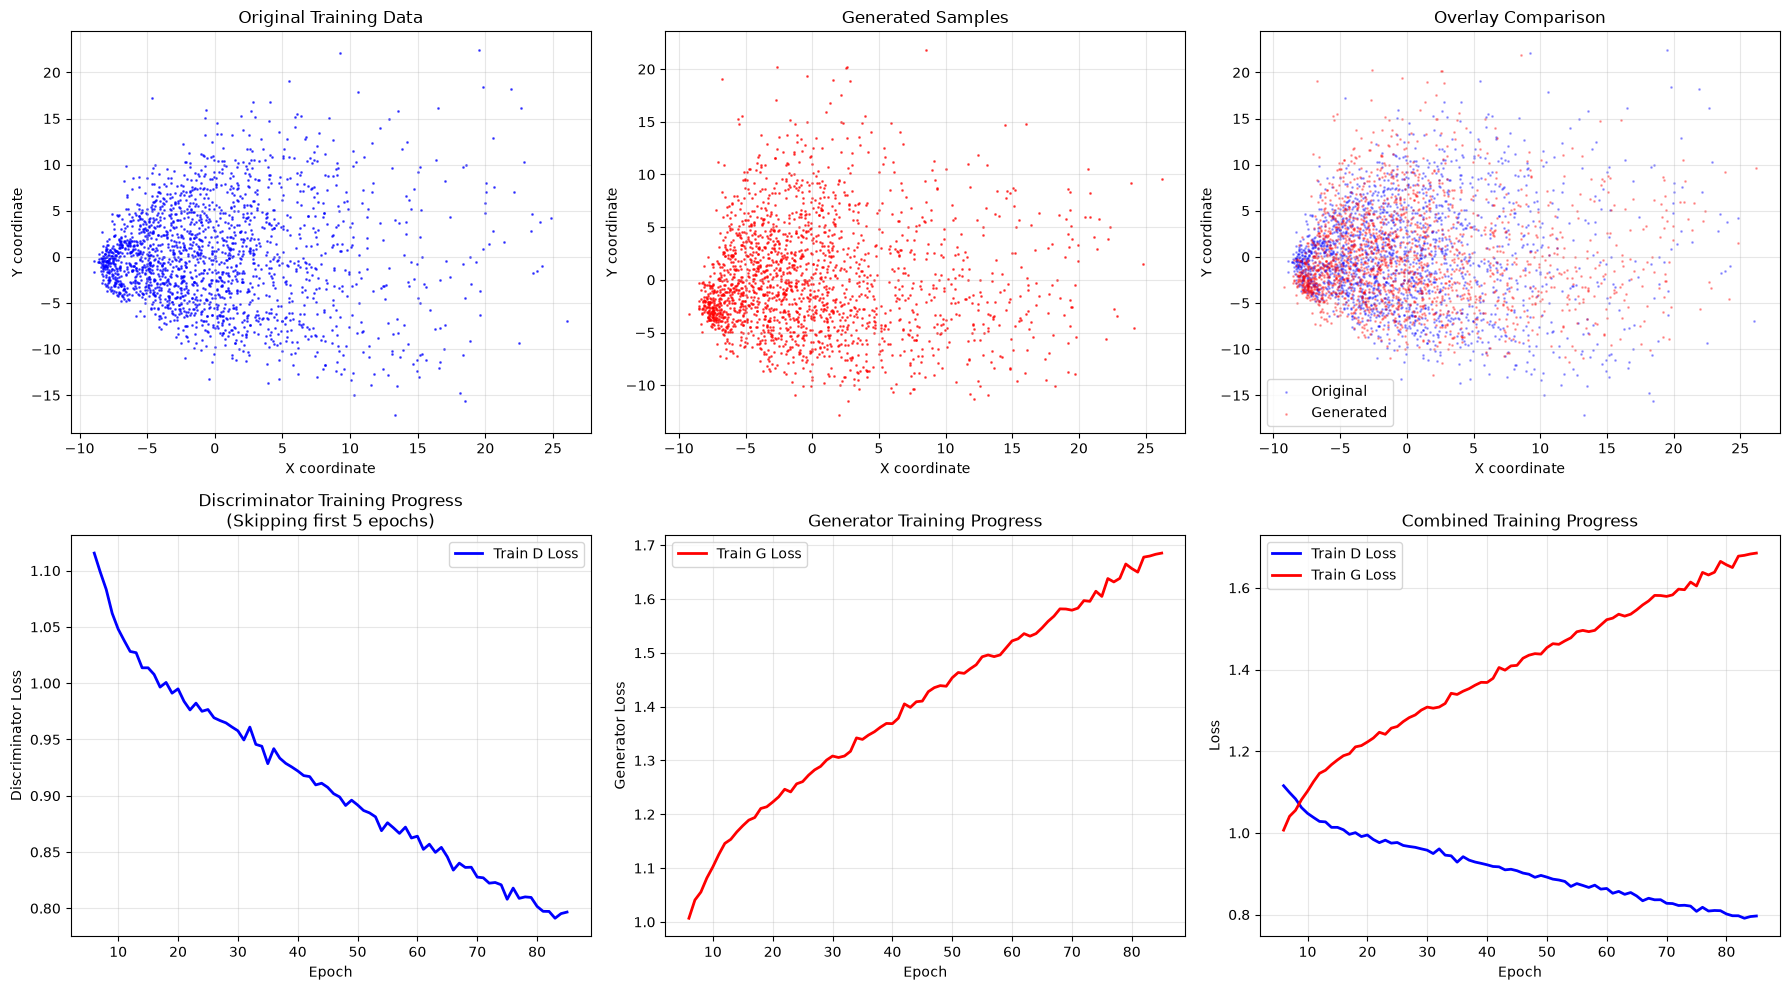

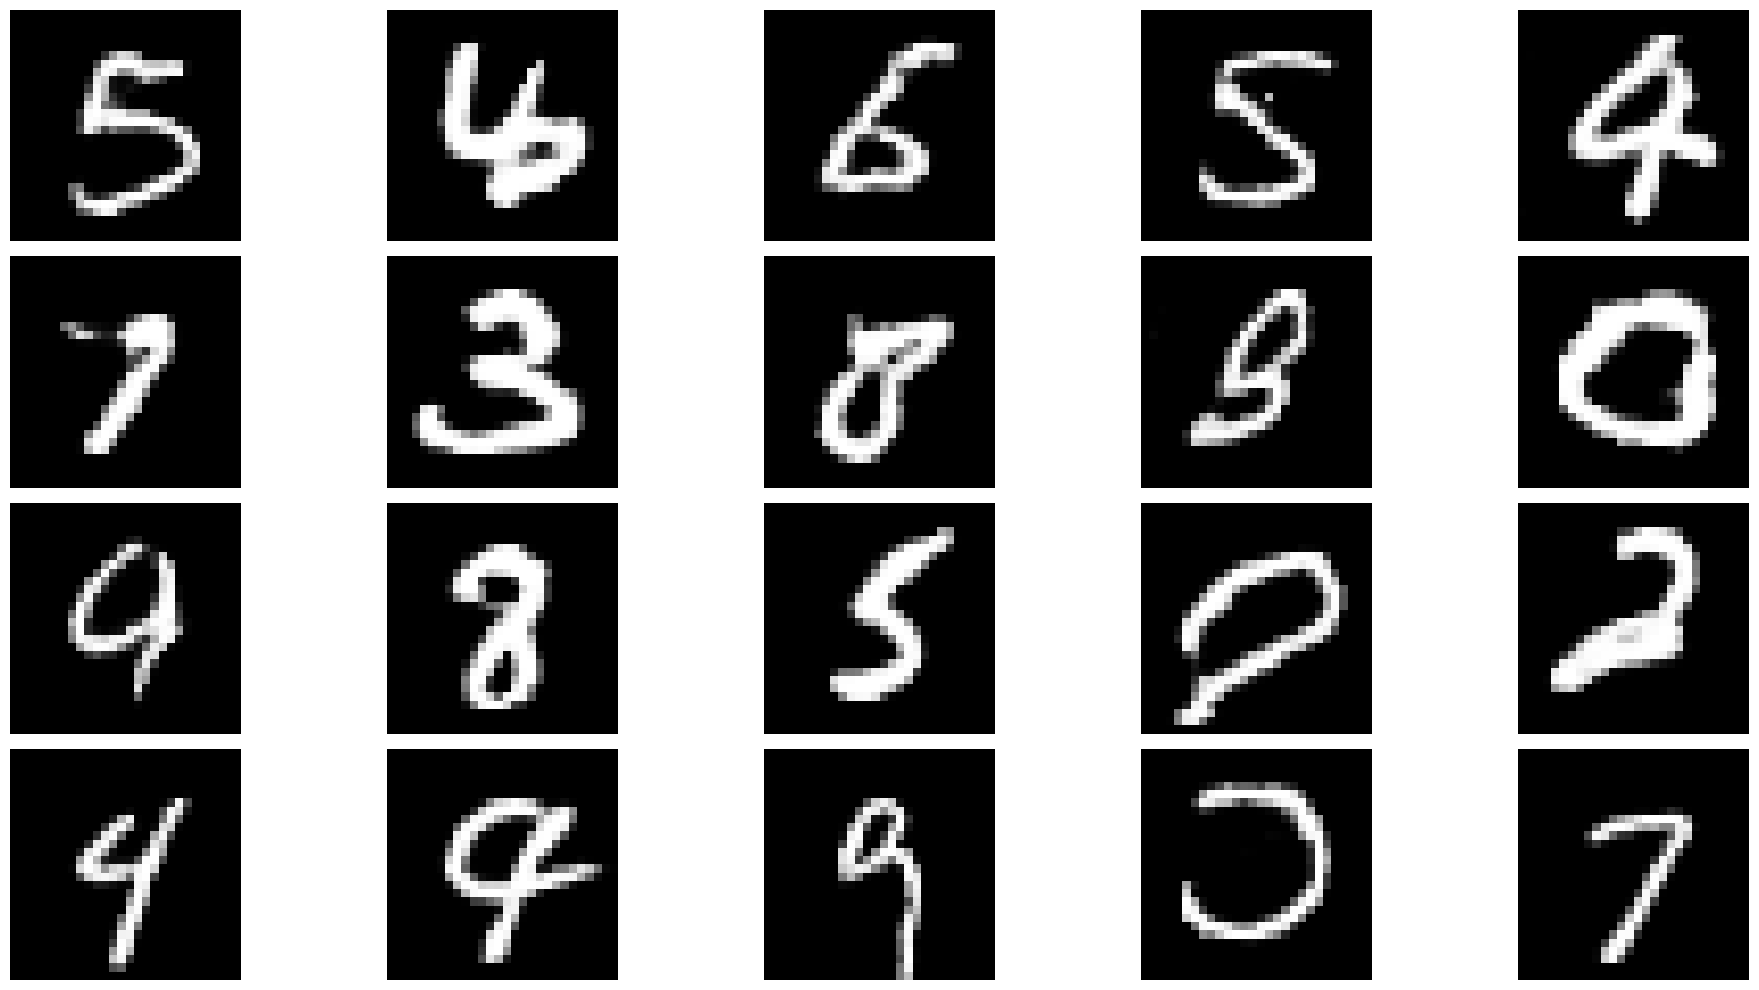

📈 Epoch 85 Summary:
   Train D Loss: 0.7966, Val D Loss: 1.1475
   Train G Loss: 1.6851, Val G Loss: 1.5912

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.711554	G_loss: 2.130759
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.855379	G_loss: 1.262856
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.536186	G_loss: 1.900395
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.651055	G_loss: 1.124163
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.876095	G_loss: 1.071427
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.695094	G_loss: 1.348135
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.866615	G_loss: 1.690003
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.787644	G_loss: 1.573855
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.817162	G_loss: 1.965463
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.978115	G_loss: 2.289200
====> Epoch: 86 Train D_loss: 0.7796, Train G_loss: 1.6908
====> Epoch: 86 Val D_loss: 1.1349, Val G_loss: 1.5808
📈 Epoch 86 Summary:
   Train D Loss: 0.7796, Val D Loss: 1.1349
   Train G Loss: 1.6908

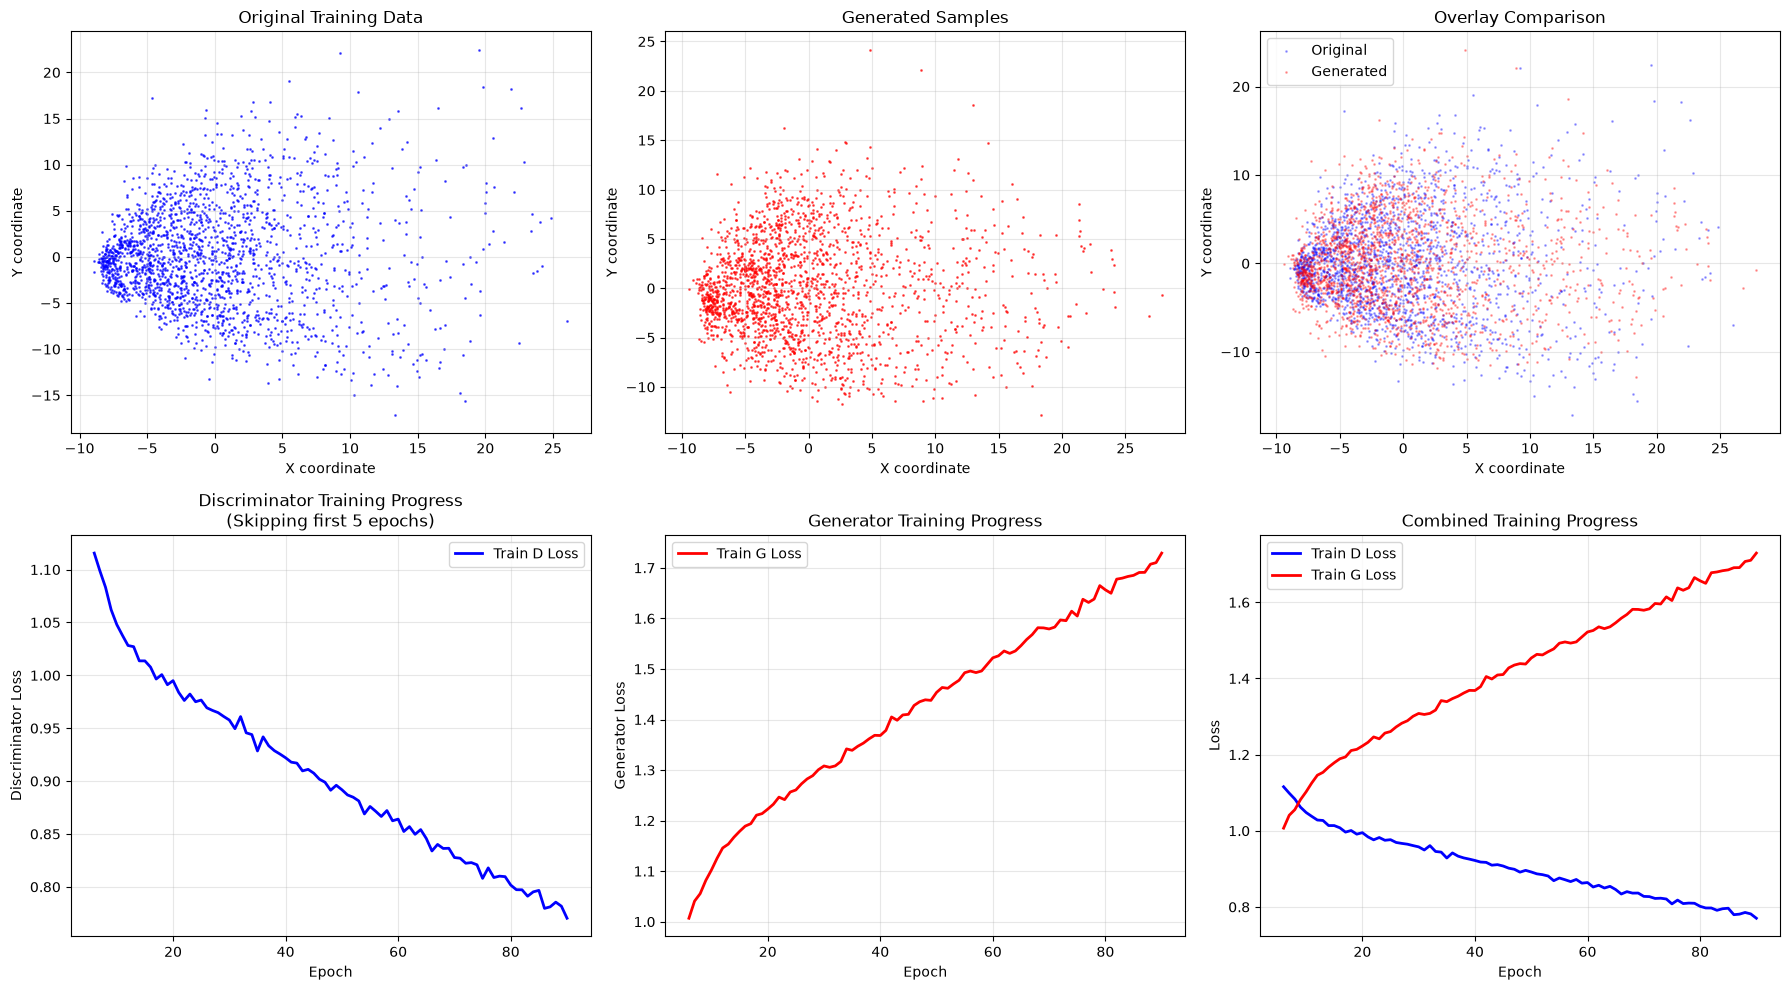

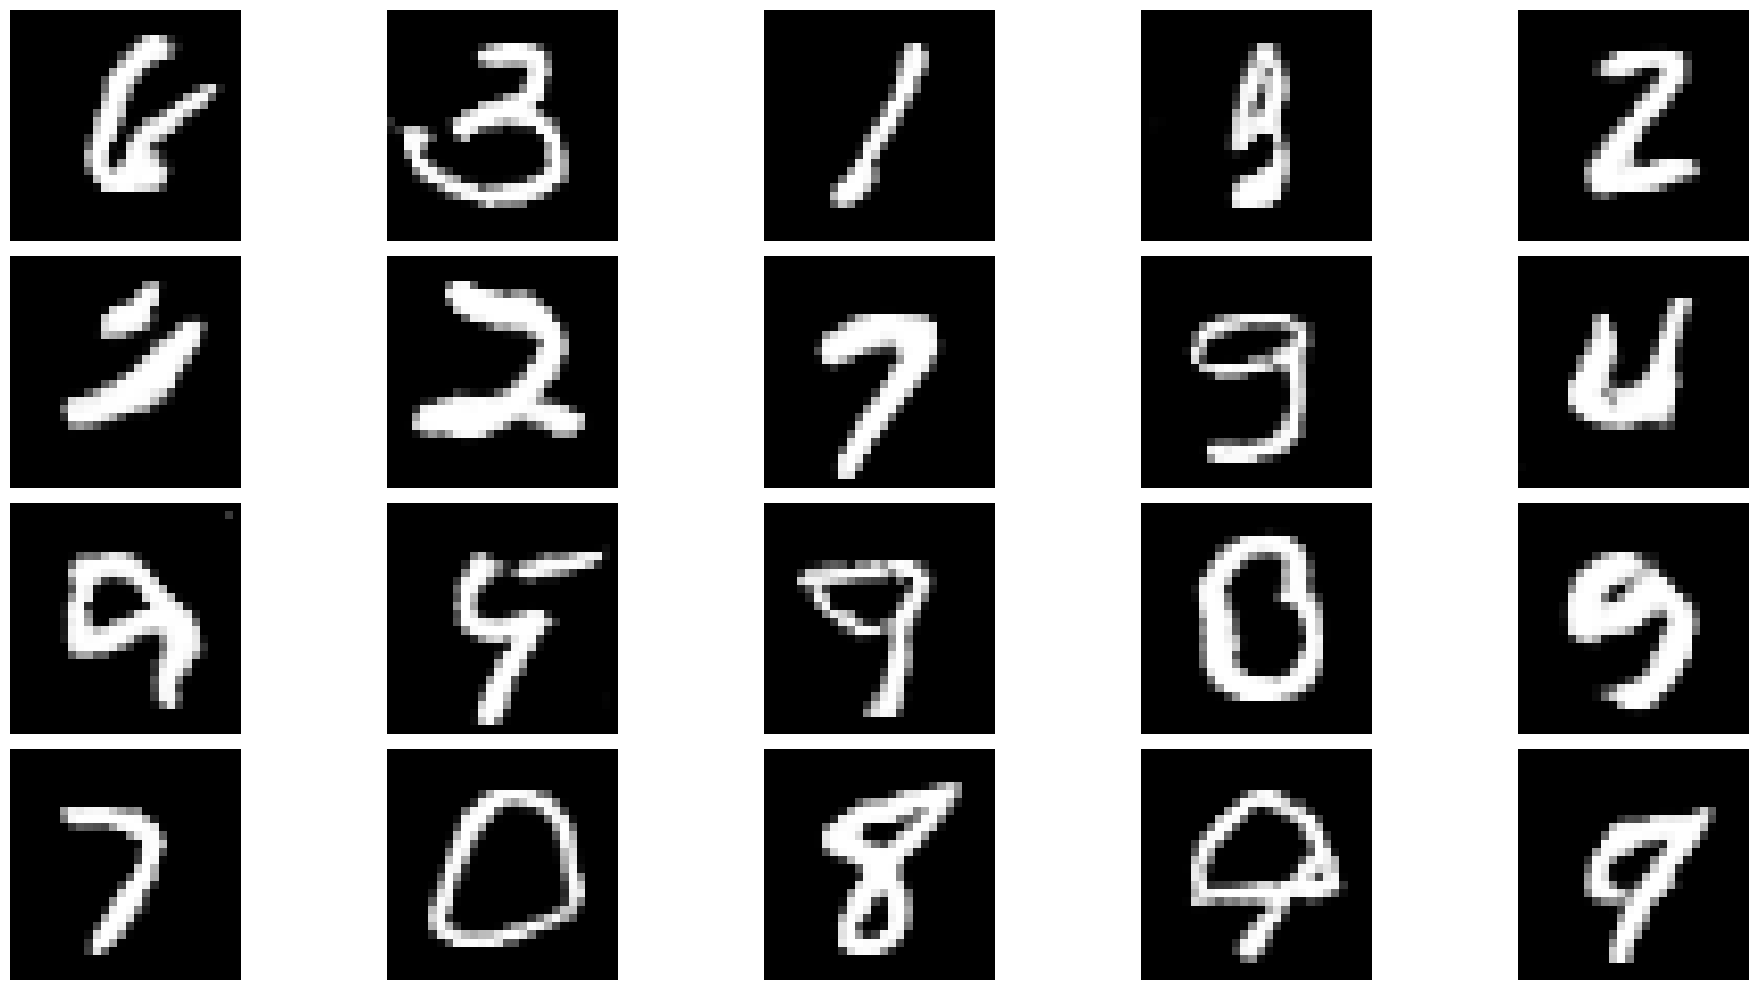

📈 Epoch 90 Summary:
   Train D Loss: 0.7703, Val D Loss: 1.0980
   Train G Loss: 1.7292, Val G Loss: 1.2205

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.698615	G_loss: 2.554278
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.800009	G_loss: 1.656293
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.710833	G_loss: 1.449068
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.763719	G_loss: 1.584170
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.707124	G_loss: 1.606512
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.902672	G_loss: 2.427264
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.560083	G_loss: 0.865958
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.624766	G_loss: 1.657902
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.073348	G_loss: 2.681827
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.663206	G_loss: 1.956729
====> Epoch: 91 Train D_loss: 0.7671, Train G_loss: 1.7217
====> Epoch: 91 Val D_loss: 1.1816, Val G_loss: 1.6744
📈 Epoch 91 Summary:
   Train D Loss: 0.7671, Val D Loss: 1.1816
   Train G Loss: 1.7217

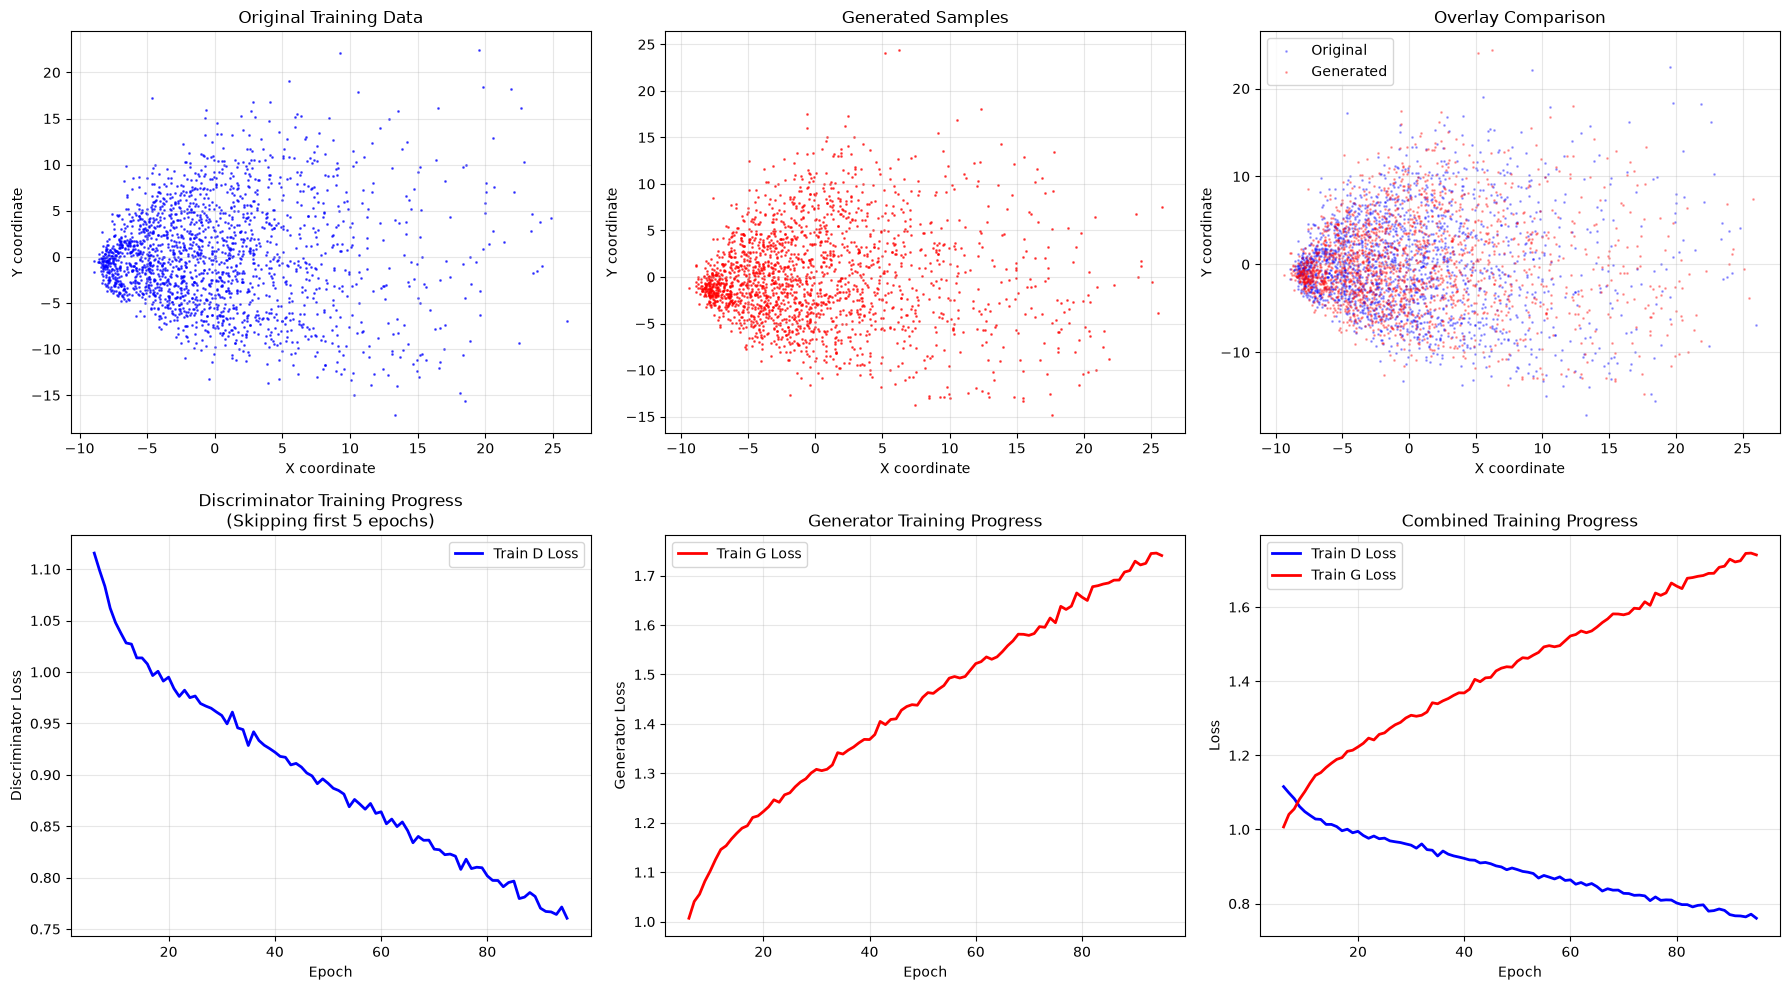

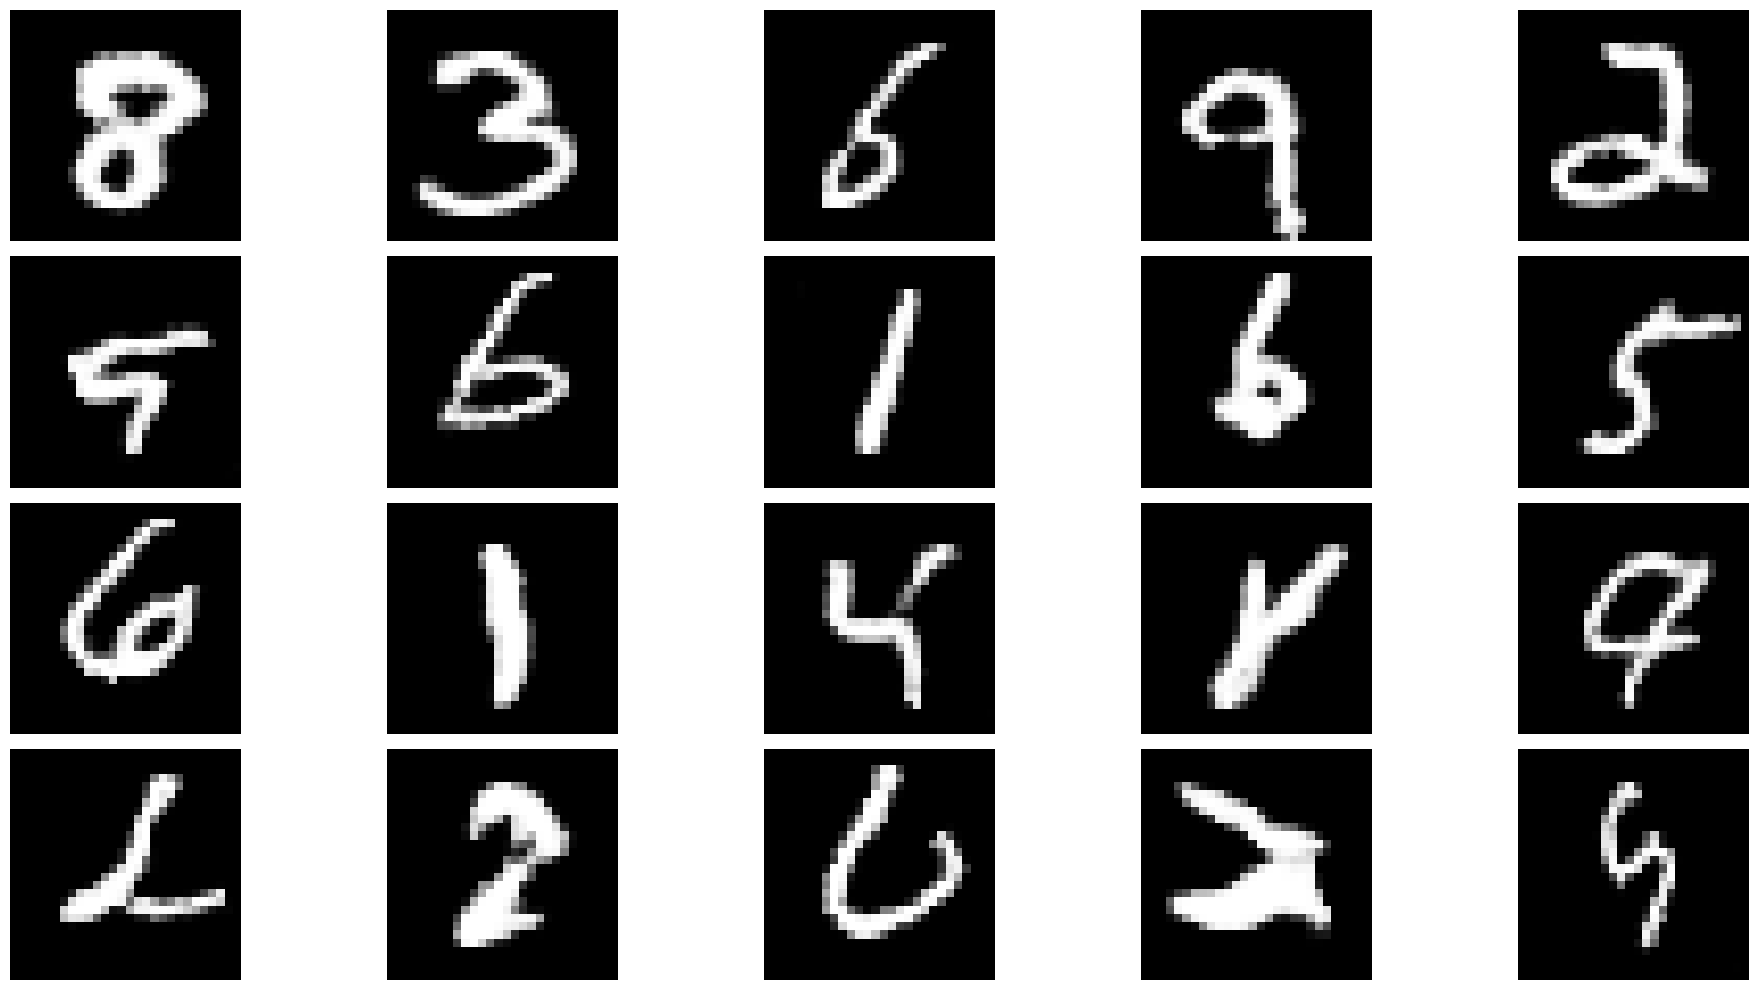

📈 Epoch 95 Summary:
   Train D Loss: 0.7605, Val D Loss: 1.1859
   Train G Loss: 1.7407, Val G Loss: 1.7292

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.752571	G_loss: 1.475137
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.671234	G_loss: 1.504810
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.861599	G_loss: 1.874033
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.758325	G_loss: 1.888679
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.646136	G_loss: 1.889272
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.700049	G_loss: 1.752139
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.645832	G_loss: 1.416814
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.660369	G_loss: 2.243607
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.789077	G_loss: 1.083494
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.656608	G_loss: 1.507298
====> Epoch: 96 Train D_loss: 0.7525, Train G_loss: 1.7560
====> Epoch: 96 Val D_loss: 1.1564, Val G_loss: 1.7089
📈 Epoch 96 Summary:
   Train D Loss: 0.7525, Val D Loss: 1.1564
   Train G Loss: 1.7560

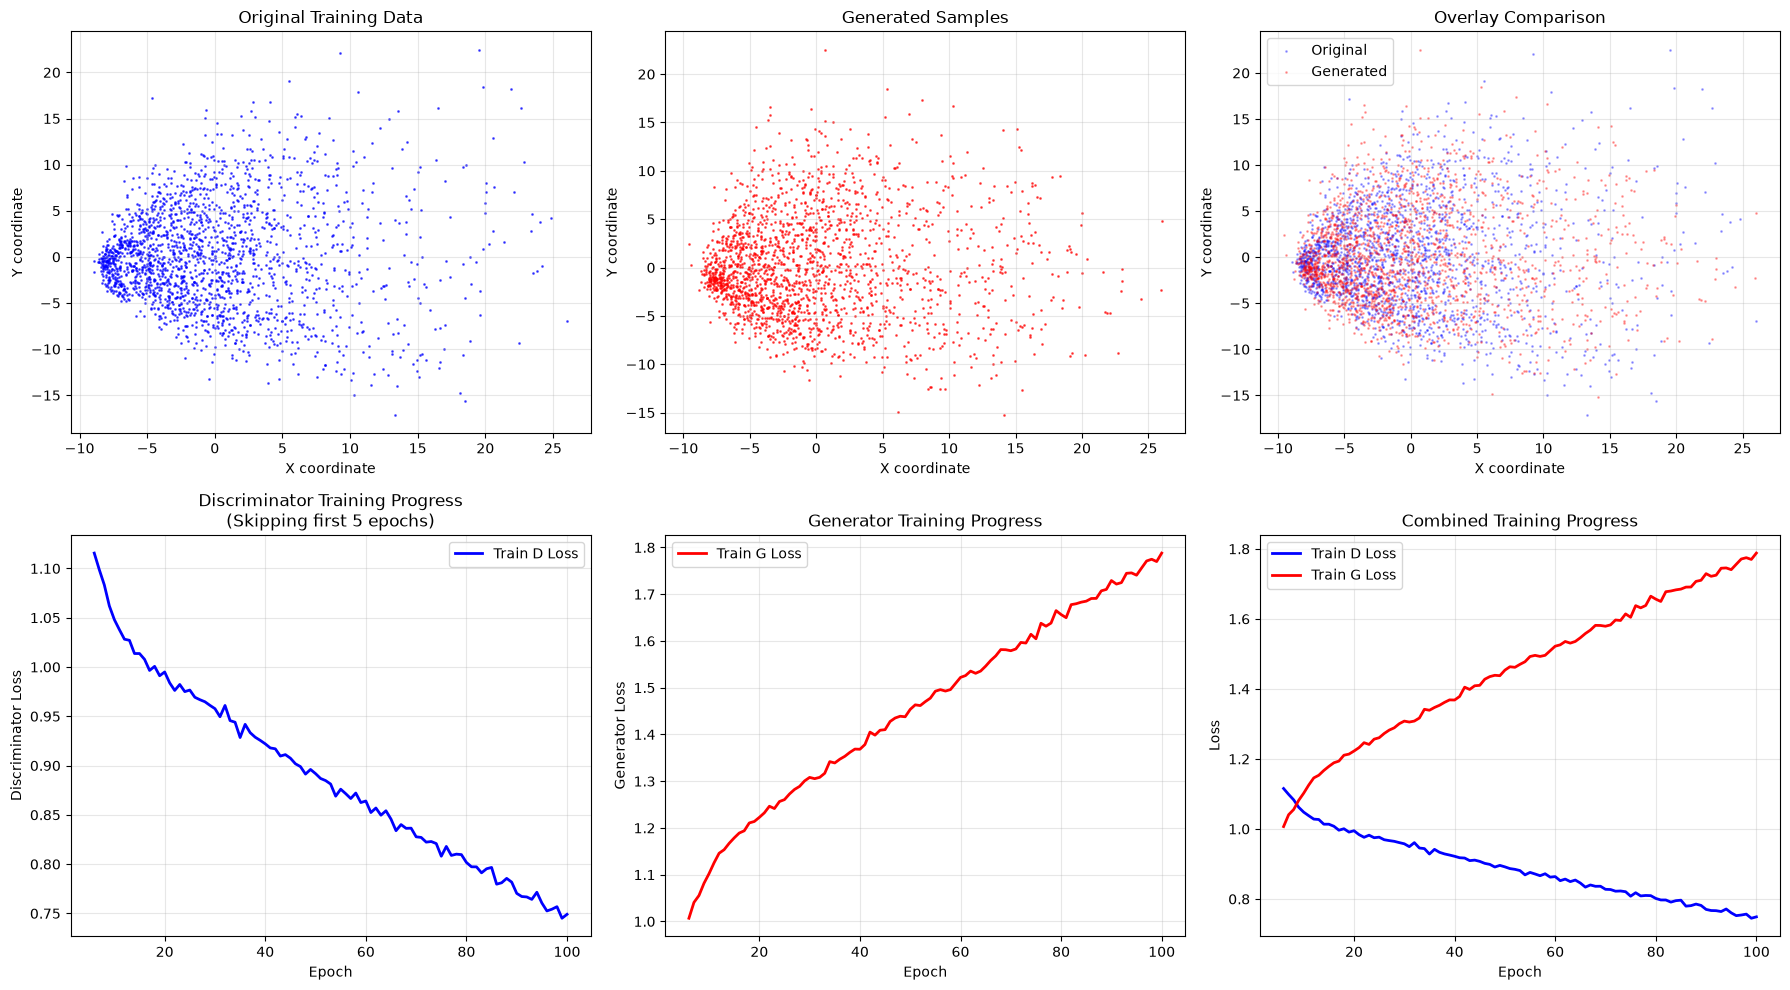

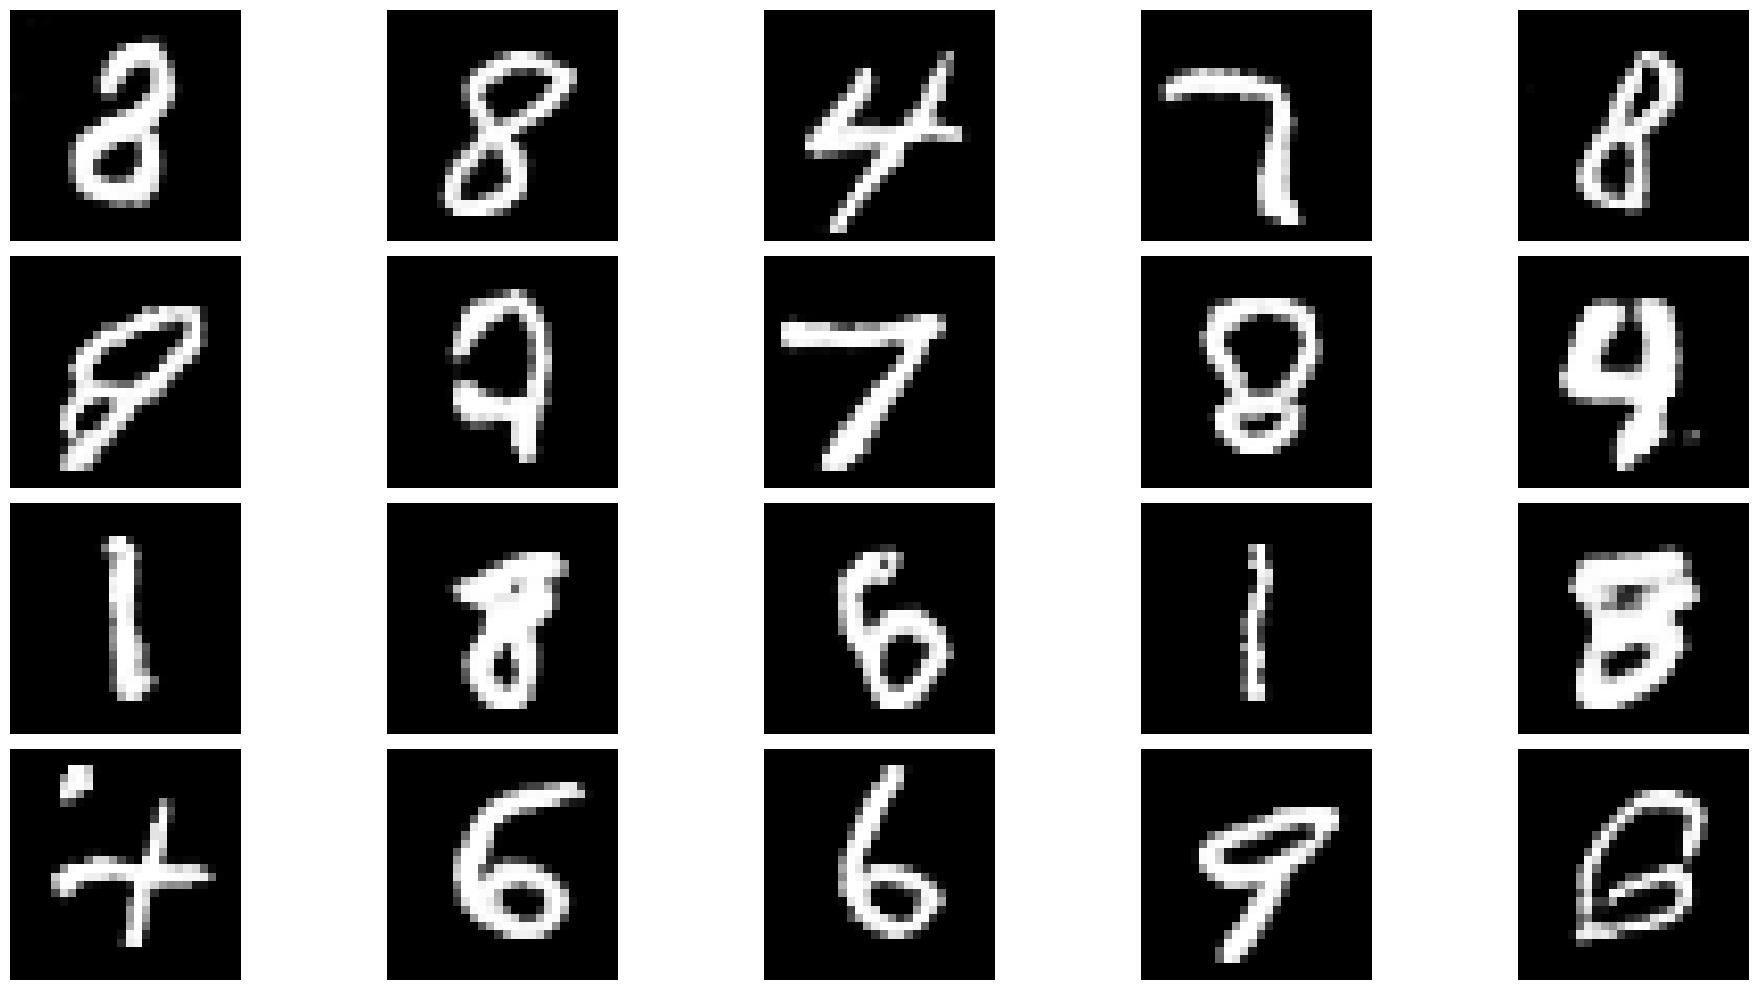

📈 Epoch 100 Summary:
   Train D Loss: 0.7490, Val D Loss: 1.2567
   Train G Loss: 1.7880, Val G Loss: 1.9500

🎉 Training completed!

🎨 Final comprehensive visualization:


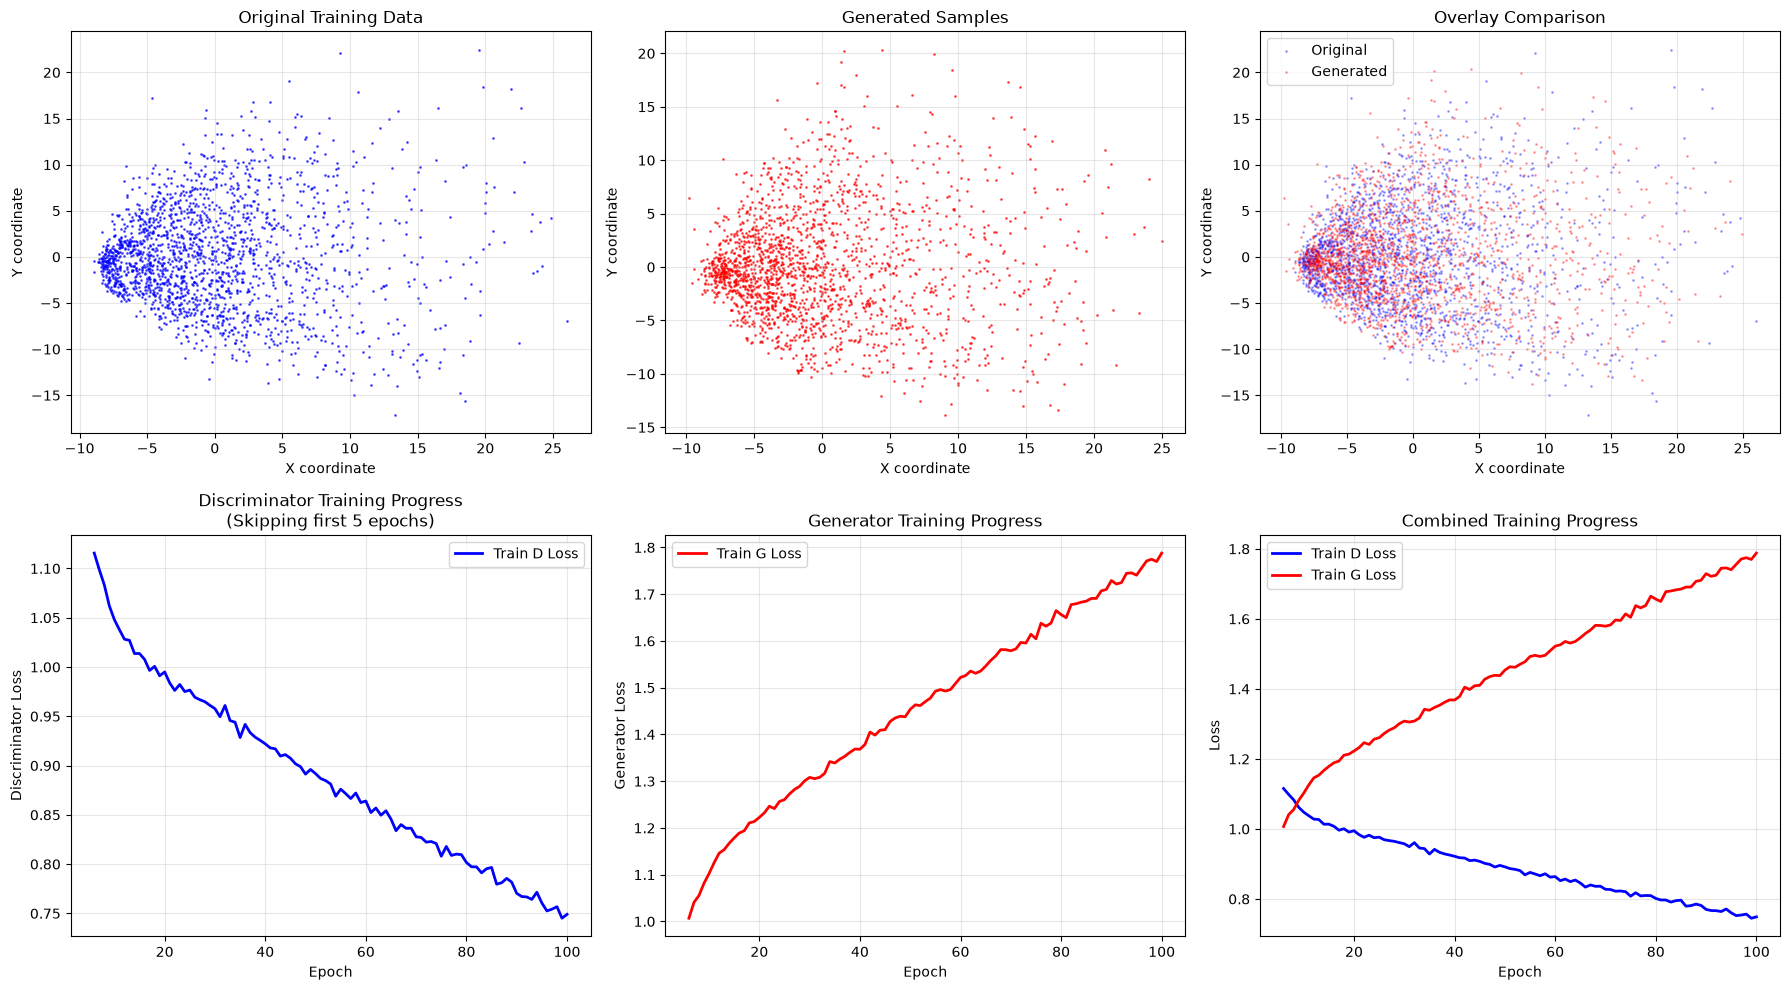

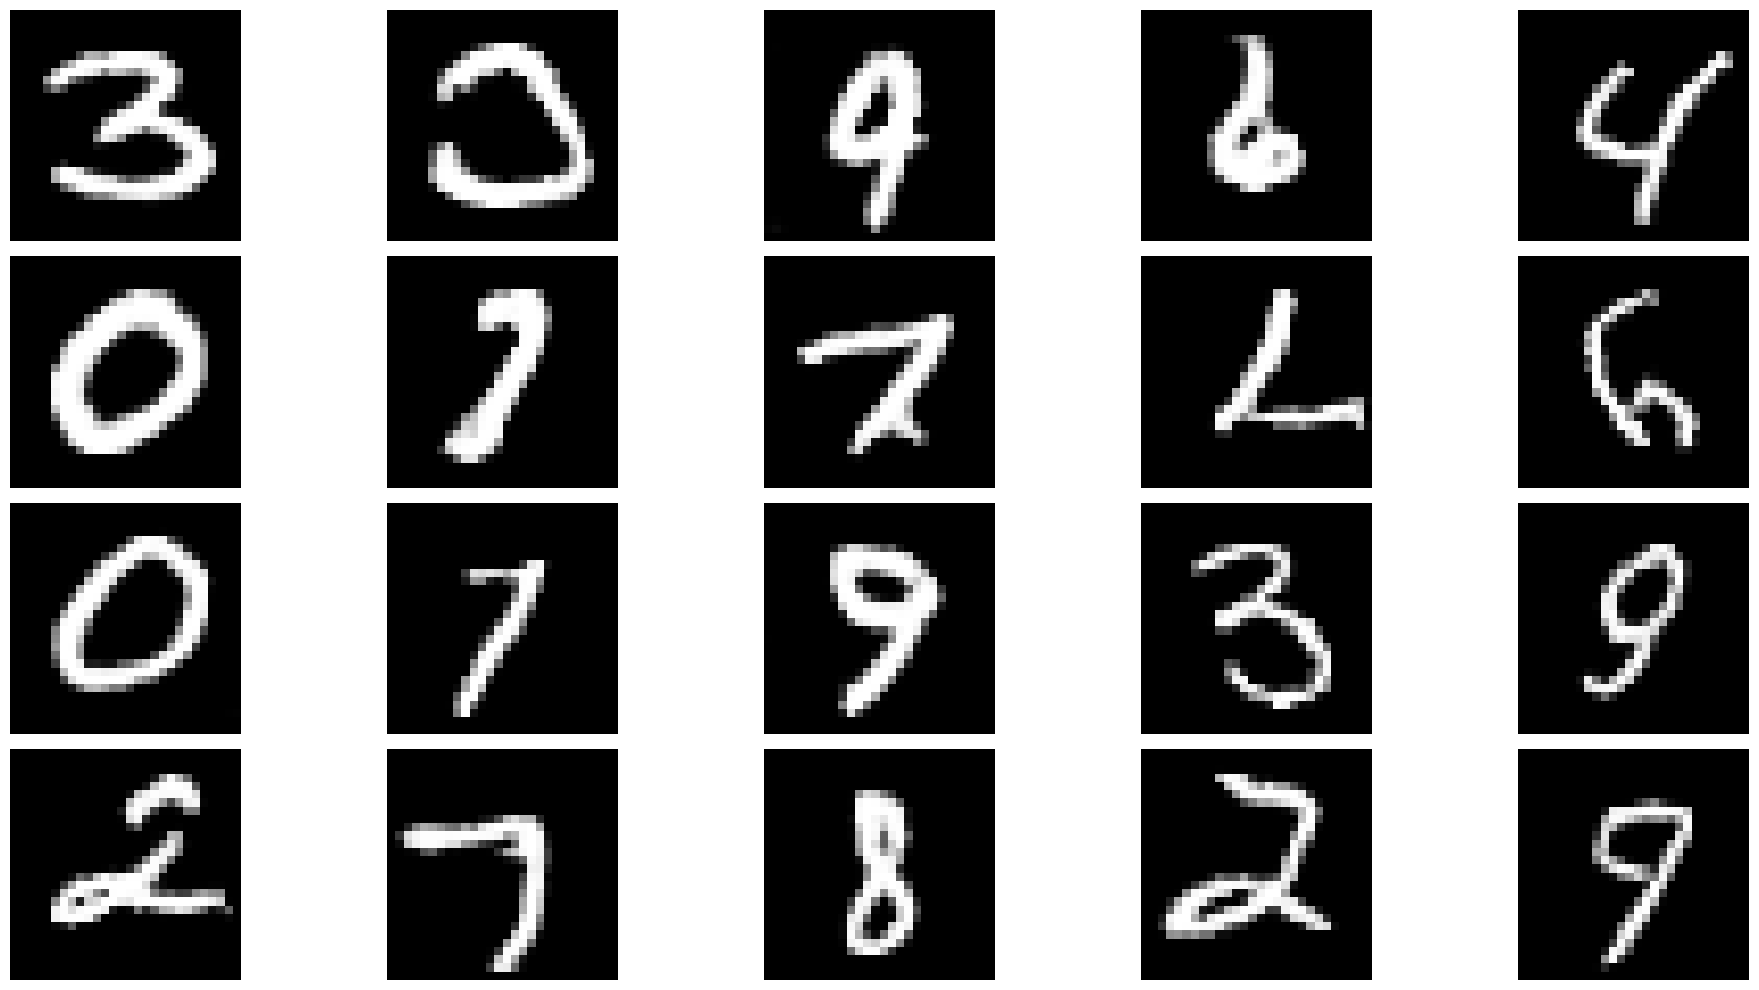

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


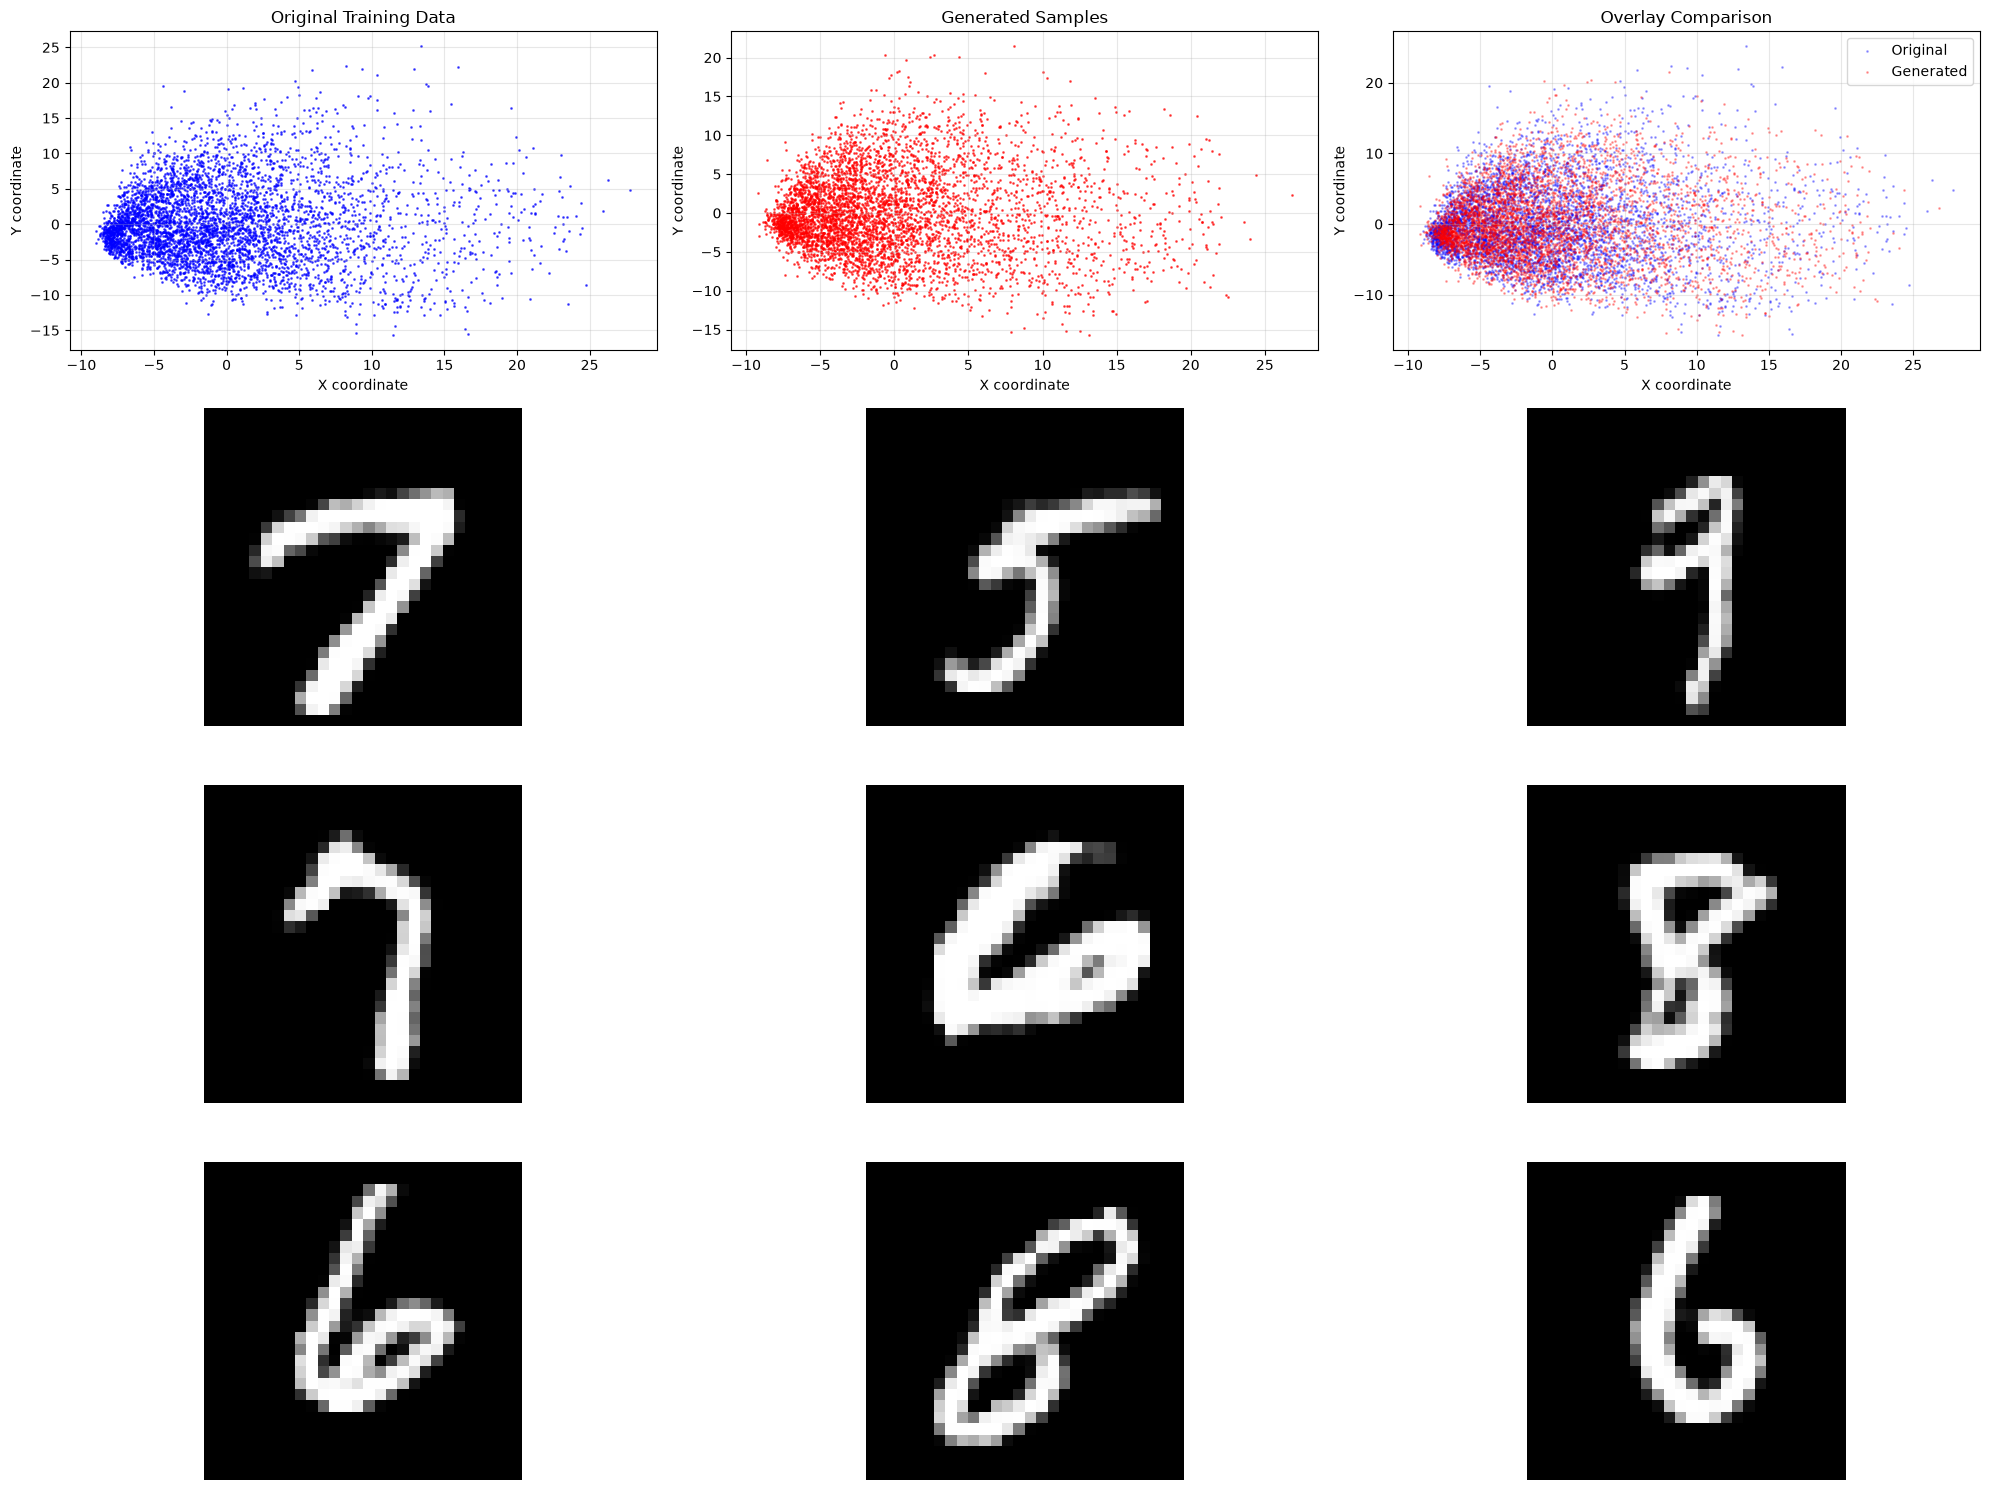

Real data confidence: 0.551
Fake data confidence: 0.200


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
